<a href="https://colab.research.google.com/github/sanikalohot14017-glitch/Demographic-Insights-into-UPI-Usage/blob/main/crop_project_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
%%writefile app_local.py
import os
import numpy as np
import pandas as pd
import lightgbm as lgb
from sklearn.preprocessing import StandardScaler
import streamlit as st
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import GRU, Dense, Dropout, Input

# Set page title
st.set_page_config(page_title="Local Yield Predictor", layout="centered")
st.title("🌾 Local Crop Yield & Production Predictor")
st.markdown("--- ")

# Cache model training to ensure localhost UI stays snappy
@st.cache_resource
def train_local_models():
    # Try loading from local path
    file_path = "panel/yield_panel_clean.csv"
    if not os.path.exists(file_path):
        return None

    df = pd.read_csv(file_path)
    df = df.sort_values(by=["crop", "district", "year"]).reset_index(drop=True)
    g = df.groupby(["crop", "district"])

    # Feature Engineering
    df['y_lag1'] = g['yield_per_ha'].shift(1)
    df['y_lag2'] = g['yield_per_ha'].shift(2)
    df['y_roll3'] = g['yield_per_ha'].transform(lambda s: s.shift(1).rolling(3, min_periods=2).mean())
    df['log_area'] = np.log(df['area_ha'])
    df['s_rain_anom'] = df['s_rain'] - g['s_rain'].transform(lambda s: s.shift(1).expanding(min_periods=3).mean())
    df['s_tmax_anom'] = df['s_tmax'] - g['s_tmax'].transform(lambda s: s.shift(1).expanding(min_periods=3).mean())

    features = ['y_lag1', 'y_lag2', 'y_roll3', 'log_area', 's_rain_anom', 's_tmax_anom']
    target = 'yield_per_ha'

    models_dict = {}
    crops = df['crop'].dropna().unique()

    for crop in crops:
        crop_df = df[df['crop'] == crop].dropna(subset=features + [target])
        if len(crop_df) < 20:
            continue

        scaler = StandardScaler()
        X_scaled = scaler.fit_transform(crop_df[features])
        y = crop_df[target].values

        # LightGBM model
        lgb_model = lgb.LGBMRegressor(n_estimators=150, learning_rate=0.05, max_depth=6, random_state=42, verbose=-1)
        lgb_model.fit(X_scaled, y)

        # GRU model
        X_gru = X_scaled.reshape((X_scaled.shape[0], 1, X_scaled.shape[1]))
        gru_model = Sequential([
            Input(shape=(X_gru.shape[1], X_gru.shape[2])),
            GRU(32, activation='relu'),
            Dropout(0.2),
            Dense(16, activation='relu'),
            Dense(1)
        ])
        gru_model.compile(optimizer='adam', loss='mse')
        gru_model.fit(X_gru, y, epochs=30, batch_size=8, verbose=0)

        models_dict[crop] = {
            'scaler': scaler,
            'lgb': lgb_model,
            'gru': gru_model,
            'avg_yield': y.mean()
        }
    return models_dict

# Run training sequence
models_dict = train_local_models()

if models_dict is None:
    st.error("⚠️ File `panel/yield_panel_clean.csv` not found locally! Please check the folder directory.")
else:
    # Setup UI Sidebar controls
    st.sidebar.header("⚙️ Simulation Parameters")
    selected_crop = st.sidebar.selectbox("Select Crop Type:", list(models_dict.keys()))
    acres = st.sidebar.number_input("Acres Planted:", min_value=0.1, max_value=10000.0, value=10.0, step=1.0)

    st.subheader("Adjust Agricultural Conditions:")
    col1, col2 = st.columns(2)

    with col1:
        y_lag1 = st.slider("Last Year Yield (t/ha):", 0.1, 5.0, 1.5, 0.1)
        y_lag2 = st.slider("Yield 2 Years Ago (t/ha):", 0.1, 5.0, 1.5, 0.1)
        y_roll3 = st.slider("3-Year Average (t/ha):", 0.1, 5.0, 1.5, 0.1)

    with col2:
        log_area = st.slider("Log Cultivated Area:", 8.0, 15.0, 12.0, 0.1)
        s_rain_anom = st.slider("Rainfall Anomaly (mm):", -500.0, 500.0, 0.0, 10.0)
        s_tmax_anom = st.slider("Temperature Anomaly (°C):", -3.0, 3.0, 0.0, 0.1)

    # Execution on user trigger
    if st.button("⚡ Generate Local Forecast"):
        scaler = models_dict[selected_crop]['scaler']
        lgb_model = models_dict[selected_crop]['lgb']
        gru_model = models_dict[selected_crop]['gru']

        custom_input = np.array([[y_lag1, y_lag2, y_roll3, log_area, s_rain_anom, s_tmax_anom]])
        scaled_input = scaler.transform(custom_input)

        # Model inferences
        lgb_pred = lgb_model.predict(scaled_input)[0]
        gru_input = scaled_input.reshape((1, 1, scaled_input.shape[1]))
        gru_pred = gru_model.predict(gru_input, verbose=0)[0][0]

        ensemble_pred = (lgb_pred + gru_pred) / 2

        # Quantify Production metrics
        hectares = acres * 0.404686
        total_production_tons = ensemble_pred * hectares
        total_production_quintals = total_production_tons * 10

        # Render Outputs
        st.success("✨ Forecast generated successfully!")

        st.metric(label="Forecasted Yield", value=f"{ensemble_pred:.2f} t/ha",
                  delta=f"{ensemble_pred - models_dict[selected_crop]['avg_yield']:.2f} vs Historical Avg")

        st.info(f"**Simulated Production Metrics for {acres} Acres ({hectares:.2f} ha):**\n"
                f"- ➔ **{total_production_tons:.2f}** Metric Tons\n"
                f"- ➔ **{total_production_quintals:.2f}** Quintals (approx {int(total_production_quintals * 100):,} kg)")


Writing app_local.py


In [ ]:
import zipfile
import os
from google.colab import files

zip_filename = 'local_dashboard_project.zip'

# Create a self-contained zip containing the app script and the panel directory data
with zipfile.ZipFile(zip_filename, 'w', zipfile.ZIP_DEFLATED) as zip_file:
    # Add the local Streamlit application script
    if os.path.exists('app_local.py'):
        zip_file.write('app_local.py')
        print('Added app_local.py to zip.')
    else:
        print('Warning: app_local.py not found in current directory!')

    # Add the clean yield panel data
    data_file = 'panel/yield_panel_clean.csv'
    if os.path.exists(data_file):
        zip_file.write(data_file, arcname='panel/yield_panel_clean.csv')
        print('Added panel/yield_panel_clean.csv to zip.')
    else:
        print('Warning: panel/yield_panel_clean.csv not found!')

# Trigger browser download of the packaged zip
print('Downloading project zip...')
files.download(zip_filename)

Added app_local.py to zip.
Added panel/yield_panel_clean.csv to zip.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

import os
os.chdir("/content/drive/MyDrive/crop_project")
print("Working directory successfully set to:", os.getcwd())
print("Files in directory:", os.listdir("."))

Mounted at /content/drive
Working directory successfully set to: /content/drive/MyDrive/crop_project
Files in directory: ['raw', 'clean', 'panel', 'source_log.csv', 'scope.txt', 'outputs', 'robustness_checks.csv', 'crop project .ipynb', 'app_local.py']


In [ ]:
import os
for p in ["raw/price","raw/yield","raw/weather","raw/ndvi","raw/msp","clean","panel"]:
    os.makedirs(p, exist_ok=True)
print(os.listdir("raw"))

['yield', 'ndvi', 'price', 'msp', 'weather']


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
base = "/content/drive/MyDrive/crop_project"
for p in ["raw/price","raw/yield","raw/weather","raw/ndvi","raw/msp","clean","panel"]:
    os.makedirs(f"{base}/{p}", exist_ok=True)
os.chdir(base)
print("Working in:", os.getcwd())

Mounted at /content/drive
Working in: /content/drive/MyDrive/crop_project


In [ ]:
with open("source_log.csv", "w") as f:
    f.write("dataset,source,url,download_date,coverage,known_gaps,notes\n")

with open("scope.txt", "w") as f:
    f.write("""Crops: Soybean, Cotton, Onion, Wheat
Period: Jan 2015 - Dec 2024
Districts: Pune, Nashik, Ahmednagar, Latur, Aurangabad, Akola, Yavatmal, Nagpur
Frequency: Monthly
""")

In [ ]:
!pip install -q openpyxl statsmodels

In [ ]:
import pandas as pd, numpy as np, requests, os

print("pandas", pd.__version__)
print("Folders OK:", all(os.path.exists(p) for p in ["raw/price","raw/yield","raw/weather","clean","panel"]))

url = ("https://power.larc.nasa.gov/api/temporal/daily/point?parameters=T2M"
       "&community=AG&longitude=73.86&latitude=18.52&start=20240101&end=20240105&format=JSON")
r = requests.get(url, timeout=60)
print("NASA POWER status:", r.status_code)

pandas 2.2.3
Folders OK: True
NASA POWER status: 200


In [ ]:
import requests, pandas as pd, os, time, datetime

districts = {"Pune":(18.52,73.86),"Nashik":(20.00,73.79),"Ahmednagar":(19.09,74.74),
             "Latur":(18.40,76.56),"Aurangabad":(19.88,75.34),"Akola":(20.71,77.00),
             "Yavatmal":(20.39,78.13),"Nagpur":(21.15,79.09)}
params = "T2M,T2M_MAX,T2M_MIN,PRECTOTCORR,RH2M,ALLSKY_SFC_SW_DWN,WS2M"

for d,(lat,lon) in districts.items():
    out = f"raw/weather/{d}.csv"
    if os.path.exists(out):
        print(d, "already downloaded, skipping"); continue
    url = (f"https://power.larc.nasa.gov/api/temporal/daily/point?parameters={params}"
           f"&community=AG&longitude={lon}&latitude={lat}&start=20150101&end=20241231&format=JSON")
    for attempt in range(3):
        try:
            r = requests.get(url, timeout=180)
            r.raise_for_status()
            data = r.json()["properties"]["parameter"]
            df = pd.DataFrame(data)
            df.index = pd.to_datetime(df.index, format="%Y%m%d")
            df = df.replace(-999, pd.NA)
            df["district"] = d
            df.to_csv(out)
            print(d, "done:", df.shape)
            break
        except Exception as e:
            print(d, "attempt", attempt+1, "failed:", e)
            time.sleep(5)

# log it
with open("source_log.csv","a") as f:
    f.write(f"weather,NASA POWER (AG community),https://power.larc.nasa.gov/api/,{datetime.date.today()},2015-2024 daily,-999 values set to NA,8 district centroids\n")

Pune done: (3653, 8)
Nashik done: (3653, 8)
Ahmednagar done: (3653, 8)
Latur done: (3653, 8)
Aurangabad done: (3653, 8)
Akola done: (3653, 8)
Yavatmal done: (3653, 8)
Nagpur done: (3653, 8)


In [ ]:
print(os.listdir("raw/weather"))
pd.read_csv("raw/weather/Pune.csv", index_col=0).describe().T

['Pune.csv', 'Nashik.csv', 'Ahmednagar.csv', 'Latur.csv', 'Aurangabad.csv', 'Akola.csv', 'Yavatmal.csv', 'Nagpur.csv']


,count,mean,std,min,25%,50%,75%,max
T2M,3653.0,23.877120,3.380195,13.41,21.69,23.61,25.85,33.59
T2M_MAX,3653.0,30.289907,4.690989,20.71,26.78,28.39,33.70,43.20
T2M_MIN,3653.0,18.854958,3.921897,5.96,15.60,20.27,21.98,27.14
PRECTOTCORR,3653.0,5.930783,13.163945,0.00,0.00,0.01,5.32,129.13
RH2M,3653.0,68.735606,20.443455,15.93,51.20,72.92,88.39,96.61
ALLSKY_SFC_SW_DWN,3653.0,17.943134,5.378449,3.06,14.71,18.07,21.75,28.73
WS2M,3653.0,2.650780,1.316728,0.47,1.68,2.25,3.25,8.67


In [ ]:
import os
print(os.getcwd())
print(os.listdir("raw/price"))

/content/drive/MyDrive/crop_project
[]


In [ ]:
import os, glob

print("Current folder:", os.getcwd())
print("\nAll files under this folder:")
found = False
for root, dirs, fs in os.walk("."):
    for f in fs:
        if not f.startswith("."):
            print(os.path.join(root, f)); found = True
if not found:
    print("(nothing found)")

Current folder: /content/drive/MyDrive/crop_project

All files under this folder:
./scope.txt
./source_log.csv
./raw/weather/Pune.csv
./raw/weather/Nashik.csv
./raw/weather/Ahmednagar.csv
./raw/weather/Latur.csv
./raw/weather/Aurangabad.csv
./raw/weather/Akola.csv
./raw/weather/Yavatmal.csv
./raw/weather/Nagpur.csv


In [ ]:
with open("scope.txt", "w") as f:
    f.write("""Crops: Soybean, Cotton, Onion, Wheat
Period: Jan 2015 - Dec 2022 (limited by Agmarknet availability)
Districts: Pune, Nashik, Ahmednagar, Latur, Aurangabad, Akola, Yavatmal, Nagpur
Frequency: Monthly
""")

with open("source_log.csv", "a") as f:
    f.write("scope_change,Agmarknet,agmarknet.gov.in,,price data available only up to 2021-22,,study window set to 2015-2022\n")

In [ ]:
import os
os.chdir("/content/drive/MyDrive/crop_project")
print(os.getcwd())
print(os.listdir("raw/price"))

/content/drive/MyDrive/crop_project
[]


In [ ]:
for f in os.listdir("raw/price"):
    print(f, os.path.getsize(f"raw/price/{f}"), "bytes")

In [ ]:
from google.colab import files
import shutil, os
up = files.upload()
for name in up:
    shutil.move(name, f"raw/price/{name}")
print(os.listdir("raw/price"))

[]


In [ ]:
!pip install -q kagglehub
import kagglehub
path = kagglehub.dataset_download("vandeetshah/india-commodity-wise-mandi-dataset")
print("Path:", path)

100%|██████████| 404M/404M [00:03<00:00, 121MB/s]

Extracting files...


Path: /root/.cache/kagglehub/datasets/vandeetshah/india-commodity-wise-mandi-dataset/versions/1


In [ ]:
import os
for root, dirs, fs in os.walk(path):
    for f in fs:
        p = os.path.join(root, f)
        print(p, round(os.path.getsize(p)/1e6, 2), "MB")

/root/.cache/kagglehub/datasets/vandeetshah/india-commodity-wise-mandi-dataset/versions/1/Groundnut (Split).csv 1.16 MB
/root/.cache/kagglehub/datasets/vandeetshah/india-commodity-wise-mandi-dataset/versions/1/Cardamoms.csv 0.77 MB
/root/.cache/kagglehub/datasets/vandeetshah/india-commodity-wise-mandi-dataset/versions/1/Squash(Chappal Kadoo).csv 3.17 MB
/root/.cache/kagglehub/datasets/vandeetshah/india-commodity-wise-mandi-dataset/versions/1/Jaffri.csv 0.27 MB
/root/.cache/kagglehub/datasets/vandeetshah/india-commodity-wise-mandi-dataset/versions/1/Banana.csv 103.45 MB
/root/.cache/kagglehub/datasets/vandeetshah/india-commodity-wise-mandi-dataset/versions/1/Marasebu.csv 0.06 MB
/root/.cache/kagglehub/datasets/vandeetshah/india-commodity-wise-mandi-dataset/versions/1/Chennangi (Whole).csv 0.0 MB
/root/.cache/kagglehub/datasets/vandeetshah/india-commodity-wise-mandi-dataset/versions/1/Hen.csv 1.67 MB
/root/.cache/kagglehub/datasets/vandeetshah/india-commodity-wise-mandi-dataset/versions/

In [ ]:
import shutil, os
os.chdir("/content/drive/MyDrive/crop_project")
for root, dirs, fs in os.walk(path):
    for f in fs:
        if f.endswith((".csv", ".xlsx")):
            shutil.copy(os.path.join(root, f), f"raw/price/{f}")
print(os.listdir("raw/price"))

['Groundnut (Split).csv', 'Cardamoms.csv', 'Squash(Chappal Kadoo).csv', 'Jaffri.csv', 'Banana.csv', 'Marasebu.csv', 'Chennangi (Whole).csv', 'Hen.csv', 'Pointed gourd (Parval).csv', 'Safflower.csv', 'Apple.csv', 'Black pepper.csv', 'Raddish.csv', 'Avare Dal.csv', 'Taramira.csv', 'Sugar.csv', 'Raya.csv', 'Castor Seed.csv', 'Coconut.csv', 'Green Gram (Moong)(Whole).csv', 'Duster Beans.csv', 'Groundnut pods (raw).csv', 'Calf.csv', 'Lime.csv', 'Sweet Potato.csv', 'Camel Hair.csv', 'Jamun(Narale Hannu).csv', 'Jute.csv', 'Sunflower.csv', 'Mahua.csv', 'Tapioca.csv', 'Thondekai.csv', 'Nutmeg.csv', 'Maragensu.csv', 'Suvarna Gadde.csv', 'Coconut Seed.csv', 'Ajwan.csv', 'Gur(Jaggery).csv', 'Chapparad Avare.csv', 'Pepper ungarbled.csv', 'Dry Chillies.csv', 'Grapes.csv', 'Jack Fruit.csv', 'Cotton.csv', 'Resinwood.csv', 'Long Melon(Kakri).csv', 'Brinjal.csv', 'Myrobolan(Harad).csv', 'Karamani.csv', 'Ginger(Dry).csv', 'Jamamkhan.csv', 'Same-Savi.csv', 'Drumstick.csv', 'Cummin Seed(Jeera).csv', 'Jute 

In [ ]:
import os, shutil, glob
os.chdir("/content/drive/MyDrive/crop_project")

want = ["Soyabean.csv", "Cotton.csv", "Onion.csv", "Wheat.csv"]
found = {}
for root, dirs, fs in os.walk(path):
    for f in fs:
        if f in want:
            found[f] = os.path.join(root, f)

for f, p in found.items():
    shutil.copy(p, f"raw/price/{f}")
    print("copied", f, round(os.path.getsize(p)/1e6, 2), "MB")

print("missing:", [w for w in want if w not in found])

copied Cotton.csv 61.02 MB
copied Onion.csv 217.46 MB
copied Soyabean.csv 75.22 MB
copied Wheat.csv 212.99 MB
missing: []


In [ ]:
import pandas as pd
for f in want:
    df = pd.read_csv(f"raw/price/{f}")
    print("=====", f, df.shape)
    print(df.columns.tolist())
    print(df.head(3))
    print(df.dtypes, "\n")

===== Soyabean.csv (888414, 10)
['State Name', 'District Name', 'Market Name', 'Variety', 'Group', 'Arrivals (Tonnes)', 'Min Price (Rs./Quintal)', 'Max Price (Rs./Quintal)', 'Modal Price (Rs./Quintal)', 'Reported Date']
       State Name District Name Market Name   Variety      Group  \
0  Andhra Pradesh       Kurnool  Yemmiganur     Local  Oil Seeds   
1  Andhra Pradesh       Kurnool     Kurnool  Soyabeen  Oil Seeds   
2  Andhra Pradesh       Kurnool     Kurnool  Soyabeen  Oil Seeds   

   Arrivals (Tonnes)  Min Price (Rs./Quintal)  Max Price (Rs./Quintal)  \
0                1.3                   1021.0                   1069.0   
1                0.8                   4041.0                   4600.0   
2                0.6                   4049.0                   4600.0   

   Modal Price (Rs./Quintal) Reported Date  
0                     1029.0   12 Jan 2007  
1                     4396.0   30 Jan 2024  
2                     4305.0   27 Jan 2024  
State Name                    

In [ ]:
import pandas as pd, os
os.chdir("/content/drive/MyDrive/crop_project")

crops = {"Soybean":"Soyabean.csv","Cotton":"Cotton.csv","Onion":"Onion.csv","Wheat":"Wheat.csv"}
parts = []
for crop, f in crops.items():
    df = pd.read_csv(f"raw/price/{f}")
    df = df[df["State Name"].str.contains("Maharashtra", case=False, na=False)].copy()
    df["crop"] = crop
    df["date"] = pd.to_datetime(df["Reported Date"], format="%d %b %Y", errors="coerce")
    parts.append(df)
    print(crop, "Maharashtra rows:", len(df), "| dates:", df["date"].min().date(), "to", df["date"].max().date())

mh = pd.concat(parts, ignore_index=True)
mh = mh.rename(columns={"District Name":"district","Market Name":"market","Arrivals (Tonnes)":"arrivals",
                        "Min Price (Rs./Quintal)":"min_price","Max Price (Rs./Quintal)":"max_price",
                        "Modal Price (Rs./Quintal)":"modal"})
mh = mh[["crop","district","market","Variety","date","arrivals","min_price","max_price","modal"]]
mh.to_csv("clean/maharashtra_daily.csv", index=False)
print(mh.shape)
print(sorted(mh["district"].dropna().unique()))

Soybean Maharashtra rows: 290535 | dates: 2001-05-26 to 2024-02-01
Cotton Maharashtra rows: 87728 | dates: 2002-12-14 to 2024-02-02
Onion Maharashtra rows: 191600 | dates: 2001-02-08 to 2024-02-02
Wheat Maharashtra rows: 339923 | dates: 2001-03-30 to 2024-02-01
(909786, 9)
['Ahmednagar', 'Akola', 'Amarawati', 'Aurangabad', 'Beed', 'Bhandara', 'Buldhana', 'Chandrapur', 'Dhule', 'Gadchiroli', 'Gondiya', 'Hingoli', 'Jalana', 'Jalgaon', 'Kolhapur', 'Latur', 'Mumbai', 'Nagpur', 'Nanded', 'Nandurbar', 'Nashik', 'Osmanabad', 'Parbhani', 'Pune', 'Raigad', 'Ratnagiri', 'Sangli', 'Satara', 'Sholapur', 'Thane', 'Vashim', 'Wardha', 'Yavatmal']


In [ ]:
mh = pd.read_csv("clean/maharashtra_daily.csv", parse_dates=["date"])
mh = mh[(mh["date"]>="2015-01-01") & (mh["date"]<="2024-12-31")]
mh["year"] = mh["date"].dt.year
cov = (mh.groupby(["crop","district","year"]).size().unstack(fill_value=0))
pd.set_option("display.max_rows", 200, "display.width", 200)
print(cov)

year                2015  2016  2017  2018  2019  2020  2021  2022  2023  2024
crop    district                                                              
Cotton  Ahmednagar    58    51    45     0    14    15     1    22    90    13
        Akola         92   279   288   298   101   198    40    15    77    26
        Amarawati    128   510   563   397    75   239    59    68    10    19
        Aurangabad    40   128   245   314   195   139     0     0    28    18
        Beed         143   258   427   375   158   167   188   250   366    43
        Buldhana      90   329   326   317   278   274   145   165   471    44
        Chandrapur    53   586   907   917   675   688   471   442   662   105
        Dhule         17     1    21    21    49    70     1     0     0     0
        Gadchiroli     3    42    47    13     0    26    65    56   161     8
        Hingoli       95   122   253   155   142   204   103    57    69     6
        Jalana       109   303   393   448   217   1

In [ ]:
def wavg(g):
    w = g["arrivals"].fillna(0)
    return (g["modal"]*w).sum()/w.sum() if w.sum()>0 else g["modal"].mean()

mh["month"] = mh["date"].dt.to_period("M").dt.to_timestamp()
monthly = (mh.groupby(["crop","district","month"])
             .apply(lambda g: pd.Series({"modal_price":wavg(g),
                                         "arrivals":g["arrivals"].sum(),
                                         "n_obs":len(g)}))
             .reset_index())

/tmp/ipykernel_1495/1217543660.py:7: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: pd.Series({"modal_price":wavg(g),


In [ ]:
import pandas as pd, os
os.chdir("/content/drive/MyDrive/crop_project")

mh = pd.read_csv("clean/maharashtra_daily.csv", parse_dates=["date"])
mh = mh[(mh["date"]>="2015-01-01") & (mh["date"]<="2024-12-31")]
mh = mh.dropna(subset=["modal"])
mh = mh[mh["modal"]>0]

mh["arr"] = mh["arrivals"].fillna(0)
mh["pxw"] = mh["modal"]*mh["arr"]
mh["month"] = mh["date"].dt.to_period("M").dt.to_timestamp()

g = mh.groupby(["crop","district","month"])
monthly = g.agg(sum_pxw=("pxw","sum"), arrivals=("arr","sum"),
                mean_modal=("modal","mean"), min_price=("min_price","min"),
                max_price=("max_price","max"), n_obs=("modal","size")).reset_index()

# arrivals-weighted price, falling back to simple mean if arrivals are all zero
monthly["modal_price"] = monthly["sum_pxw"]/monthly["arrivals"]
monthly.loc[monthly["arrivals"]==0, "modal_price"] = monthly["mean_modal"]
monthly = monthly.drop(columns=["sum_pxw","mean_modal"])

monthly.to_csv("clean/price_monthly_all_districts.csv", index=False)
print(monthly.shape)
print(monthly.head())

(8940, 8)
     crop    district      month  arrivals  min_price  max_price  n_obs  modal_price
0  Cotton  Ahmednagar 2015-01-01      34.3     4050.0     4100.0      2  4062.390671
1  Cotton  Ahmednagar 2015-10-01      37.0     4100.0     4500.0      8  4405.405405
2  Cotton  Ahmednagar 2015-11-01     123.0     4100.0     4350.0     24  4268.292683
3  Cotton  Ahmednagar 2015-12-01     294.0     4100.0     4500.0     24  4272.380952
4  Cotton  Ahmednagar 2016-01-01      93.0     4100.0     4800.0      9  4574.193548


In [ ]:
import pandas as pd, os
os.chdir("/content/drive/MyDrive/crop_project")
monthly = pd.read_csv("clean/price_monthly_all_districts.csv", parse_dates=["month"])

print(sorted(monthly["district"].unique()))

target = ["Pune","Nashik","Ahmednagar","Latur","Aurangabad","Akola","Yavatmal","Nagpur"]
sub = monthly[monthly["district"].isin(target)]
cov = (sub.groupby(["crop","district"])
          .agg(months=("month","nunique"), first=("month","min"), last=("month","max")))
pd.set_option("display.width", 200, "display.max_rows", 100)
print(cov)

['Ahmednagar', 'Akola', 'Amarawati', 'Aurangabad', 'Beed', 'Bhandara', 'Buldhana', 'Chandrapur', 'Dhule', 'Gadchiroli', 'Hingoli', 'Jalana', 'Jalgaon', 'Kolhapur', 'Latur', 'Mumbai', 'Nagpur', 'Nanded', 'Nandurbar', 'Nashik', 'Osmanabad', 'Parbhani', 'Pune', 'Raigad', 'Ratnagiri', 'Sangli', 'Satara', 'Sholapur', 'Thane', 'Vashim', 'Wardha', 'Yavatmal']
                    months      first       last
crop    district                                
Cotton  Ahmednagar      24 2015-01-01 2024-01-01
        Akola           62 2015-05-01 2024-02-01
        Aurangabad      46 2015-05-01 2024-02-01
        Nagpur          84 2015-03-01 2024-02-01
        Pune            14 2017-02-01 2024-01-01
        Yavatmal        67 2015-10-01 2024-02-01
Onion   Ahmednagar     110 2015-01-01 2024-02-01
        Akola           18 2018-05-01 2024-02-01
        Aurangabad     110 2015-01-01 2024-02-01
        Nagpur         110 2015-01-01 2024-02-01
        Nashik         110 2015-01-01 2024-02-01
        

In [ ]:
c = monthly[(monthly.crop=="Cotton")].groupby("district")["month"].nunique().sort_values(ascending=False)
print(c)

district
Jalgaon       97
Nagpur        84
Wardha        82
Buldhana      77
Parbhani      72
Chandrapur    72
Beed          71
Yavatmal      67
Jalana        66
Nanded        64
Amarawati     62
Akola         62
Hingoli       60
Aurangabad    46
Gadchiroli    37
Nandurbar     35
Vashim        31
Ahmednagar    24
Dhule         20
Pune          14
Sangli         1
Name: month, dtype: int64


In [ ]:
import pandas as pd, numpy as np, os
os.chdir("/content/drive/MyDrive/crop_project")
monthly = pd.read_csv("clean/price_monthly_all_districts.csv", parse_dates=["month"])

keep = {
 "Soybean": ["Ahmednagar","Akola","Aurangabad","Latur","Nagpur","Nashik","Pune","Yavatmal"],
 "Wheat":   ["Ahmednagar","Akola","Aurangabad","Latur","Nagpur","Nashik","Pune","Yavatmal"],
 "Onion":   ["Ahmednagar","Aurangabad","Nagpur","Nashik","Pune"],
 "Cotton":  ["Nagpur","Yavatmal","Akola"],
}
months = pd.date_range("2015-01-01","2024-02-01",freq="MS")

def fill_short(s, maxgap=2):
    isna = s.isna()
    gaplen = isna.groupby((~isna).cumsum()).transform("sum")
    interp = s.interpolate(limit_area="inside")
    return s.where(~(isna & (gaplen<=maxgap)), interp)

out = []
for crop, ds in keep.items():
    for d in ds:
        s = monthly[(monthly.crop==crop)&(monthly.district==d)].set_index("month")
        s = s.reindex(months)
        g = pd.DataFrame({"crop":crop,"district":d,"month":months,
                          "modal_price":s["modal_price"].values,
                          "arrivals":s["arrivals"].values,
                          "n_obs":s["n_obs"].values})
        g["traded"] = g["modal_price"].notna().astype(int)
        g["modal_price"] = fill_short(g["modal_price"])
        g["arrivals"] = g["arrivals"].fillna(0)
        out.append(g)

price = pd.concat(out, ignore_index=True)
price.to_csv("clean/price_monthly_selected.csv", index=False)
print(price.shape)
print(price.groupby("crop")[["modal_price"]].agg(["count","min","max"]))

(2640, 7)
        modal_price                           
              count          min           max
crop                                          
Cotton          227  1500.000000  11365.651537
Onion           550   311.897577   6004.310343
Soybean         879  2455.000000   9434.062134
Wheat           876   841.002144   4291.984463


In [ ]:
with open("scope.txt","w") as f:
    f.write("""Crops: Soybean, Wheat, Onion, Cotton
Period: Jan 2015 - Feb 2024 (limited by Kaggle mandi dataset end date)
Series: Soybean 8, Wheat 8, Onion 5, Cotton 3 districts (24 total)
Frequency: Monthly
""")
with open("source_log.csv","a") as f:
    f.write("price,Kaggle India Commodity Wise Mandi Dataset (vandeetshah),https://www.kaggle.com/datasets/vandeetshah/india-commodity-wise-mandi-dataset,,2015-2024 daily; ends Feb 2024,seasonal gaps for cotton and onion; some districts sparse,aggregated to monthly arrivals-weighted modal price\n")

In [ ]:
import requests, pandas as pd, os, time, datetime
os.chdir("/content/drive/MyDrive/crop_project")

new = {"Jalgaon":(21.01,75.56),"Wardha":(20.74,78.60),"Buldhana":(20.53,76.18)}
params = "T2M,T2M_MAX,T2M_MIN,PRECTOTCORR,RH2M,ALLSKY_SFC_SW_DWN,WS2M"

for d,(lat,lon) in new.items():
    out = f"raw/weather/{d}.csv"
    if os.path.exists(out):
        print(d,"already there"); continue
    url = (f"https://power.larc.nasa.gov/api/temporal/daily/point?parameters={params}"
           f"&community=AG&longitude={lon}&latitude={lat}&start=20150101&end=20241231&format=JSON")
    for attempt in range(3):
        try:
            r = requests.get(url, timeout=180); r.raise_for_status()
            df = pd.DataFrame(r.json()["properties"]["parameter"])
            df.index = pd.to_datetime(df.index, format="%Y%m%d")
            df = df.replace(-999, pd.NA); df["district"] = d
            df.to_csv(out); print(d,"done",df.shape); break
        except Exception as e:
            print(d,"attempt",attempt+1,"failed:",e); time.sleep(5)

Jalgaon done (3653, 8)
Wardha done (3653, 8)
Buldhana done (3653, 8)


In [ ]:
import numpy as np
monthly = pd.read_csv("clean/price_monthly_all_districts.csv", parse_dates=["month"])

keep = {
 "Soybean": ["Ahmednagar","Akola","Aurangabad","Latur","Nagpur","Nashik","Pune","Yavatmal"],
 "Wheat":   ["Ahmednagar","Akola","Aurangabad","Latur","Nagpur","Nashik","Pune","Yavatmal"],
 "Onion":   ["Ahmednagar","Aurangabad","Nagpur","Nashik","Pune"],
 "Cotton":  ["Jalgaon","Nagpur","Wardha","Buldhana","Yavatmal","Akola"],
}
months = pd.date_range("2015-01-01","2024-02-01",freq="MS")

def fill_short(s, maxgap=2):
    isna = s.isna()
    gaplen = isna.groupby((~isna).cumsum()).transform("sum")
    interp = s.interpolate(limit_area="inside")
    return s.where(~(isna & (gaplen<=maxgap)), interp)

out = []
for crop, ds in keep.items():
    for d in ds:
        s = monthly[(monthly.crop==crop)&(monthly.district==d)].set_index("month").reindex(months)
        g = pd.DataFrame({"crop":crop,"district":d,"month":months,
                          "modal_price":s["modal_price"].values,
                          "arrivals":s["arrivals"].values,
                          "n_obs":s["n_obs"].values})
        g["traded"] = g["modal_price"].notna().astype(int)
        g["modal_price"] = fill_short(g["modal_price"])
        g["arrivals"] = g["arrivals"].fillna(0)
        out.append(g)

price = pd.concat(out, ignore_index=True)
price.to_csv("clean/price_monthly_selected.csv", index=False)
print(price.shape, "| series:", price.groupby(["crop","district"]).ngroups)
print(price.groupby("crop")["modal_price"].agg(["count","min","max"]))

(2970, 7) | series: 27
         count          min           max
crop                                     
Cotton     495  1500.000000  11365.651537
Onion      550   311.897577   6004.310343
Soybean    879  2455.000000   9434.062134
Wheat      876   841.002144   4291.984463


In [ ]:
districts = sorted(set(d for ds in keep.values() for d in ds))
print(districts)

w = pd.concat([pd.read_csv(f"raw/weather/{d}.csv", index_col=0, parse_dates=True) for d in districts])
w.index.name = "date"
w = w.reset_index()
w["month"] = w["date"].dt.to_period("M").dt.to_timestamp()

wm = (w.groupby(["district","month"])
        .agg(rain=("PRECTOTCORR","sum"), tmax=("T2M_MAX","mean"), tmin=("T2M_MIN","mean"),
             tmean=("T2M","mean"), rh=("RH2M","mean"),
             solar=("ALLSKY_SFC_SW_DWN","mean"), wind=("WS2M","mean")).reset_index())

panel = price.merge(wm, on=["district","month"], how="left")
panel["covid"] = ((panel["month"]>="2020-03-01")&(panel["month"]<="2021-12-01")).astype(int)
panel.to_csv("panel/panel_monthly_v1.csv", index=False)
print(panel.shape)
print(panel.isna().sum())

['Ahmednagar', 'Akola', 'Aurangabad', 'Buldhana', 'Jalgaon', 'Latur', 'Nagpur', 'Nashik', 'Pune', 'Wardha', 'Yavatmal']
(2970, 15)
crop             0
district         0
month            0
modal_price    170
arrivals         0
n_obs          206
traded           0
rain             0
tmax             0
tmin             0
tmean            0
rh               0
solar            0
wind             0
covid            0
dtype: int64


In [ ]:
with open("scope.txt","w") as f:
    f.write("""Crops: Soybean, Wheat, Onion, Cotton
Period: Jan 2015 - Feb 2024 (limited by Kaggle mandi dataset end date)
Series: Soybean 8, Wheat 8, Onion 5, Cotton 6 districts (27 total)
Frequency: Monthly
""")

In [ ]:
import glob, pandas as pd
files = glob.glob("raw/yield/**/*.csv", recursive=True) + glob.glob("raw/yield/**/*.xlsx", recursive=True)
print(files)
f = files[0]
y = pd.read_csv(f) if f.endswith(".csv") else pd.read_excel(f)
print(y.columns.tolist()); print(y.head()); print(y.shape)

for c in y.columns:
    if y[c].nunique() < 80:
        print(c, "->", sorted(y[c].astype(str).unique())[:40])

[]


IndexError: list index out of range

In [ ]:
import requests, os
os.chdir("/content/drive/MyDrive/crop_project")
url = ("https://ckandev.indiadataportal.com/dataset/80789131-1b7d-4809-a03e-7ce88cee2917/"
       "resource/ead44f5f-6471-48ec-a488-4b5894302aaa/download/crop-wise-area-production-yield.csv")
r = requests.get(url, timeout=180)
print(r.status_code, len(r.content)/1e6, "MB")
if r.status_code == 200:
    open("raw/yield/apy_idp.csv","wb").write(r.content)

404 0.018531 MB


In [ ]:
!pip install -q kagglehub
import kagglehub, os, shutil
os.chdir("/content/drive/MyDrive/crop_project")
ypath = kagglehub.dataset_download("pyatakov/india-agriculture-crop-production")
for root, dirs, fs in os.walk(ypath):
    for f in fs:
        p = os.path.join(root, f)
        print(p, round(os.path.getsize(p)/1e6,2), "MB")
        if f.endswith((".csv",".xlsx")):
            shutil.copy(p, f"raw/yield/{f}")
print(os.listdir("raw/yield"))

100%|██████████| 5.59M/5.59M [00:00<00:00, 134MB/s]

Extracting files...


/root/.cache/kagglehub/datasets/pyatakov/india-agriculture-crop-production/versions/4/India Agriculture Crop Production.csv 30.99 MB
['India Agriculture Crop Production.csv']


In [ ]:
import glob, pandas as pd, os
os.chdir("/content/drive/MyDrive/crop_project")
y = pd.read_csv("raw/yield/India Agriculture Crop Production.csv")
print(y.shape)
print(y.columns.tolist())
print(y.head())
print(y.dtypes)

for c in y.columns:
    if y[c].nunique() < 80:
        print("\n", c, "->", sorted(y[c].astype(str).unique())[:40])

(345407, 10)
['State', 'District', 'Crop', 'Year', 'Season', 'Area', 'Area Units', 'Production', 'Production Units', 'Yield']
                         State                  District      Crop     Year      Season    Area Area Units  Production Production Units     Yield
0  Andaman and Nicobar Islands                  NICOBARS  Arecanut  2001-02      Kharif  1254.0    Hectare      2061.0           Tonnes  1.643541
1  Andaman and Nicobar Islands                  NICOBARS  Arecanut  2002-03  Whole Year  1258.0    Hectare      2083.0           Tonnes  1.655803
2  Andaman and Nicobar Islands                  NICOBARS  Arecanut  2003-04  Whole Year  1261.0    Hectare      1525.0           Tonnes  1.209358
3  Andaman and Nicobar Islands  NORTH AND MIDDLE ANDAMAN  Arecanut  2001-02      Kharif  3100.0    Hectare      5239.0           Tonnes  1.690000
4  Andaman and Nicobar Islands            SOUTH ANDAMANS  Arecanut  2002-03  Whole Year  3105.0    Hectare      5267.0           Tonnes  1.69629

In [ ]:
import pandas as pd, os
os.chdir("/content/drive/MyDrive/crop_project")
y = pd.read_csv("raw/yield/India Agriculture Crop Production.csv")
m = y[y["State"]=="Maharashtra"].copy()
print(m.shape)

print(sorted(m["Crop"].unique()))
print(sorted(m["District"].unique()))

want = m[m["Crop"].str.contains("soy|cotton|wheat|onion", case=False, na=False)]
print(want.groupby("Crop")[["Year"]].agg(["min","max","nunique"]))
print(want.groupby(["Crop","Season"]).size())
print(want.groupby(["Crop","Production Units"]).size())

(17922, 10)
['Arhar/Tur', 'Bajra', 'Banana', 'Castor seed', 'Cotton(lint)', 'Gram', 'Groundnut', 'Jowar', 'Linseed', 'Maize', 'Moong(Green Gram)', 'Niger seed', 'Onion', 'Other Cereals', 'Other Kharif pulses', 'Other Rabi pulses', 'Other Summer Pulses', 'Ragi', 'Rapeseed &Mustard', 'Rice', 'Safflower', 'Sesamum', 'Small millets', 'Soyabean', 'Sugarcane', 'Sunflower', 'Tobacco', 'Urad', 'Wheat', 'other oilseeds']
['AHMEDNAGAR', 'AKOLA', 'AMRAVATI', 'AURANGABAD', 'BEED', 'BHANDARA', 'BULDHANA', 'CHANDRAPUR', 'DHULE', 'GADCHIROLI', 'GONDIA', 'HINGOLI', 'JALGAON', 'JALNA', 'KOLHAPUR', 'LATUR', 'MUMBAI', 'MUMBAI SUBURBAN', 'NAGPUR', 'NANDED', 'NANDURBAR', 'NASHIK', 'OSMANABAD', 'PALGHAR', 'PARBHANI', 'PUNE', 'RAIGAD', 'RATNAGIRI', 'SANGLI', 'SATARA', 'SINDHUDURG', 'SOLAPUR', 'THANE', 'WARDHA', 'WASHIM', 'YAVATMAL']
                 Year                 
                  min      max nunique
Crop                                  
Cotton(lint)  1997-98  2019-20      23
Onion         2003-04 

In [ ]:
import os
os.chdir("/content/drive/MyDrive/crop_project")
with open("scope.txt","w") as f:
    f.write("""Title: Explainable multivariate time-series framework for joint crop yield and agricultural price forecasting (ML + DL)
Joint model crops: Soybean (8 districts), Wheat (8), Cotton (6)
Price-only extra (optional): Onion (5 districts), no district yield available
Price period: Jan 2015 - Feb 2024 (monthly)
Yield period: 1997-98 to 2019-20 (annual, source ends 2019-20)
Yield-only model window: 2001-2020; joint model window: 2015-16 to 2019-20
""")
with open("source_log.csv","a") as f:
    f.write("yield,Kaggle India Agriculture Crop Production (pyatakov),https://www.kaggle.com/datasets/pyatakov/india-agriculture-crop-production,,1997-98 to 2019-20 for Maharashtra,onion has one year only; cotton in bales,crops limited to soybean cotton wheat\n")

In [ ]:
import requests, pandas as pd, os, time
os.chdir("/content/drive/MyDrive/crop_project")
os.makedirs("raw/weather_hist", exist_ok=True)

coords = {"Pune":(18.52,73.86),"Nashik":(20.00,73.79),"Ahmednagar":(19.09,74.74),
          "Latur":(18.40,76.56),"Aurangabad":(19.88,75.34),"Akola":(20.71,77.00),
          "Yavatmal":(20.39,78.13),"Nagpur":(21.15,79.09),
          "Jalgaon":(21.01,75.56),"Wardha":(20.74,78.60),"Buldhana":(20.53,76.18)}
params = "T2M,T2M_MAX,T2M_MIN,PRECTOTCORR,RH2M,ALLSKY_SFC_SW_DWN,WS2M"

for d,(lat,lon) in coords.items():
    out = f"raw/weather_hist/{d}.csv"
    if os.path.exists(out):
        print(d,"already there"); continue
    url = (f"https://power.larc.nasa.gov/api/temporal/daily/point?parameters={params}"
           f"&community=AG&longitude={lon}&latitude={lat}&start=20010101&end=20141231&format=JSON")
    for attempt in range(3):
        try:
            r = requests.get(url, timeout=180); r.raise_for_status()
            df = pd.DataFrame(r.json()["properties"]["parameter"])
            df.index = pd.to_datetime(df.index, format="%Y%m%d")
            df = df.replace(-999, pd.NA); df["district"] = d
            df.to_csv(out); print(d,"done",df.shape); break
        except Exception as e:
            print(d,"attempt",attempt+1,"failed:",e); time.sleep(5)
print(sorted(os.listdir("raw/weather_hist")))

Pune done (5113, 8)
Nashik done (5113, 8)
Ahmednagar done (5113, 8)
Latur done (5113, 8)
Aurangabad done (5113, 8)
Akola done (5113, 8)
Yavatmal done (5113, 8)
Nagpur done (5113, 8)
Jalgaon done (5113, 8)
Wardha done (5113, 8)
Buldhana done (5113, 8)
['Ahmednagar.csv', 'Akola.csv', 'Aurangabad.csv', 'Buldhana.csv', 'Jalgaon.csv', 'Latur.csv', 'Nagpur.csv', 'Nashik.csv', 'Pune.csv', 'Wardha.csv', 'Yavatmal.csv']


In [ ]:
frames = []
for folder in ["raw/weather_hist","raw/weather"]:
    for d in coords:
        p = f"{folder}/{d}.csv"
        if os.path.exists(p):
            frames.append(pd.read_csv(p, index_col=0, parse_dates=True))
w = pd.concat(frames)
w.index.name = "date"
w = w.reset_index().drop_duplicates(["district","date"])
w["month"] = w["date"].dt.to_period("M").dt.to_timestamp()

wm_all = (w.groupby(["district","month"])
            .agg(rain=("PRECTOTCORR","sum"), tmax=("T2M_MAX","mean"), tmin=("T2M_MIN","mean"),
                 tmean=("T2M","mean"), rh=("RH2M","mean"),
                 solar=("ALLSKY_SFC_SW_DWN","mean"), wind=("WS2M","mean")).reset_index())
wm_all.to_csv("clean/weather_monthly_2001_2024.csv", index=False)
print(wm_all.shape, wm_all["month"].min(), wm_all["month"].max())
print(wm_all.isna().sum())

(3168, 9) 2001-01-01 00:00:00 2024-12-01 00:00:00
district    0
month       0
rain        0
tmax        0
tmin        0
tmean       0
rh          0
solar       0
wind        0
dtype: int64


In [ ]:
import pandas as pd, os
os.chdir("/content/drive/MyDrive/crop_project")

y = pd.read_csv("raw/yield/India Agriculture Crop Production.csv")
m = y[y["State"]=="Maharashtra"].copy()
m["district"] = m["District"].str.title()
crop_map = {"Soyabean":"Soybean","Cotton(lint)":"Cotton","Wheat":"Wheat"}
m = m[m["Crop"].isin(crop_map)].copy()
m["crop"] = m["Crop"].map(crop_map)
m["year"] = m["Year"].str[:4].astype(int)

keep = {
 "Soybean": ["Ahmednagar","Akola","Aurangabad","Latur","Nagpur","Nashik","Pune","Yavatmal"],
 "Wheat":   ["Ahmednagar","Akola","Aurangabad","Latur","Nagpur","Nashik","Pune","Yavatmal"],
 "Cotton":  ["Jalgaon","Nagpur","Wardha","Buldhana","Yavatmal","Akola"],
}
m = m[m.apply(lambda r: r["district"] in keep[r["crop"]], axis=1)].copy()

# duplicates check
dup = m.duplicated(["crop","district","year"], keep=False)
print("Rows in duplicated crop-district-year groups:", dup.sum())
print(m[dup].sort_values(["crop","district","year"])[["crop","district","year","Season","Area","Production","Yield"]].head(12))

# keep one row per crop-district-year, preferring Kharif/Rabi over Whole Year
m["pref"] = (m["Season"]=="Whole Year").astype(int)
m = (m.sort_values(["crop","district","year","pref"])
       .drop_duplicates(["crop","district","year"], keep="first"))

yl = m[["crop","district","year","Season","Area","Production","Yield"]].rename(
        columns={"Area":"area_ha","Production":"production","Yield":"yield_raw"})
yl["yield_per_ha"] = yl["production"]/yl["area_ha"]
yl.loc[yl.area_ha<=0, "yield_per_ha"] = float("nan")
yl.to_csv("clean/yield_annual.csv", index=False)

print("\nRows:", yl.shape)
print("\nCoverage 2014 onward:")
print(yl[yl.year>=2014].groupby(["crop","district"])["year"].agg(["nunique","min","max"]))
print("\nDescribe by crop:")
print(yl.groupby("crop")["yield_per_ha"].describe())
print("\nYield_raw vs computed check (should be close):")
print((yl["yield_raw"]-yl["yield_per_ha"]).abs().describe())

Rows in duplicated crop-district-year groups: 0
Empty DataFrame
Columns: [crop, district, year, Season, Area, Production, Yield]
Index: []

Rows: (498, 8)

Coverage 2014 onward:
                    nunique   min   max
crop    district                       
Cotton  Akola             6  2014  2019
        Buldhana          6  2014  2019
        Jalgaon           6  2014  2019
        Nagpur            6  2014  2019
        Wardha            6  2014  2019
        Yavatmal          6  2014  2019
Soybean Ahmednagar        6  2014  2019
        Akola             6  2014  2019
        Aurangabad        6  2014  2019
        Latur             6  2014  2019
        Nagpur            6  2014  2019
        Nashik            6  2014  2019
        Pune              6  2014  2019
        Yavatmal          6  2014  2019
Wheat   Ahmednagar        6  2014  2019
        Akola             6  2014  2019
        Aurangabad        6  2014  2019
        Latur             6  2014  2019
        Nagpur        

In [ ]:
def season_feats(wm, crop, year, district):
    if crop in ("Soybean","Cotton"):
        s, e = pd.Timestamp(year,6,1), pd.Timestamp(year,10,1)
    else:  # Wheat, agricultural year 2015-16 -> Nov 2015 - Mar 2016
        s, e = pd.Timestamp(year,11,1), pd.Timestamp(year+1,3,1)
    d = wm[(wm.district==district)&(wm.month>=s)&(wm.month<=e)]
    if len(d)==0: return pd.Series(dtype=float)
    return pd.Series({"s_rain":d.rain.sum(), "s_tmax":d.tmax.mean(), "s_tmin":d.tmin.mean(),
                      "s_rh":d.rh.mean(), "s_solar":d.solar.mean(), "s_wind":d.wind.mean(),
                      "s_rain_days_proxy":(d.rain>50).sum()})

yl = pd.read_csv("clean/yield_annual.csv")
feats = yl.apply(lambda r: season_feats(wm_all, r["crop"], int(r["year"]), r["district"]), axis=1)
yield_panel = pd.concat([yl, feats], axis=1)
yield_panel.to_csv("panel/yield_panel.csv", index=False)
print(yield_panel.shape)
print(yield_panel.isna().sum())

(498, 15)
crop                  0
district              0
year                  0
Season                0
area_ha               0
production            0
yield_raw             0
yield_per_ha          0
s_rain               72
s_tmax               72
s_tmin               72
s_rh                 72
s_solar              72
s_wind               72
s_rain_days_proxy    72
dtype: int64


In [ ]:
import pandas as pd, os
os.chdir("/content/drive/MyDrive/crop_project")
yp = pd.read_csv("panel/yield_panel.csv")

# 1. Confirm the missing rows are all before 2001
print("Missing-weather rows by year:")
print(yp[yp.s_rain.isna()].groupby("year").size())

# 2. Drop pre-2001 rows and the incomplete 2000 wheat season
yp = yp[yp.year>=2001].copy()
yp = yp.dropna(subset=["s_rain","yield_per_ha"])

# 3. Check remaining coverage
print("\nRows after cleaning:", yp.shape)
print(yp.groupby(["crop","district"])["year"].agg(["nunique","min","max"]))
print("\nYield summary by crop:")
print(yp.groupby("crop")["yield_per_ha"].describe())

yp.to_csv("panel/yield_panel_clean.csv", index=False)

Missing-weather rows by year:
year
1997    14
1998    22
1999    22
2000    14
dtype: int64

Rows after cleaning: (418, 15)
                    nunique   min   max
crop    district                       
Cotton  Akola            19  2001  2019
        Buldhana         19  2001  2019
        Jalgaon          19  2001  2019
        Nagpur           19  2001  2019
        Wardha           19  2001  2019
        Yavatmal         19  2001  2019
Soybean Ahmednagar       19  2001  2019
        Akola            19  2001  2019
        Aurangabad       19  2001  2019
        Latur            19  2001  2019
        Nagpur           19  2001  2019
        Nashik           19  2001  2019
        Pune             19  2001  2019
        Yavatmal         19  2001  2019
Wheat   Ahmednagar       19  2001  2019
        Akola            19  2001  2019
        Aurangabad       19  2001  2019
        Latur            19  2001  2019
        Nagpur           19  2001  2019
        Nashik           19  2001  2

In [ ]:
import pandas as pd, os
os.chdir("/content/drive/MyDrive/crop_project")
yp = pd.read_csv("panel/yield_panel_clean.csv")

# each value vs its own series median
yp["med"] = yp.groupby(["crop","district"])["yield_per_ha"].transform("median")
yp["ratio"] = yp["yield_per_ha"]/yp["med"]
print("Highest 8 yields:")
print(yp.nlargest(8,"yield_per_ha")[["crop","district","year","area_ha","production","yield_per_ha","ratio"]])
print("\nLowest 8 yields:")
print(yp.nsmallest(8,"yield_per_ha")[["crop","district","year","area_ha","production","yield_per_ha","ratio"]])
print("\nRows with ratio <0.35 or >2.2:")
print(yp[(yp.ratio<0.35)|(yp.ratio>2.2)][["crop","district","year","area_ha","production","yield_per_ha","ratio"]])

Highest 8 yields:
        crop  district  year   area_ha  production  yield_per_ha     ratio
72    Cotton    Nagpur  2016  136500.0    550200.0      4.030769  2.812017
240  Soybean      Pune  2013    6900.0     26800.0      3.884058  2.013956
230  Soybean      Pune  2003     600.0      2000.0      3.333333  1.728395
34    Cotton  Buldhana  2016  169550.0    516600.0      3.046889  2.425920
231  Soybean      Pune  2004    1200.0      3600.0      3.000000  1.555556
91    Cotton    Wardha  2016  240500.0    718900.0      2.989189  2.166310
242  Soybean      Pune  2015   16100.0     47000.0      2.919255  1.513688
53    Cotton   Jalgaon  2016  504200.0   1462300.0      2.900238  1.778808

Lowest 8 yields:
        crop  district  year   area_ha  production  yield_per_ha     ratio
140  Soybean     Akola  2008  137500.0     28300.0      0.205818  0.200670
336    Wheat     Latur  2014   47200.0     10800.0      0.228814  0.217801
176  Soybean     Latur  2006  155400.0     43300.0      0.278636

In [ ]:
panel = pd.read_csv("panel/panel_monthly_v1.csv", parse_dates=["month"])
yp = pd.read_csv("panel/yield_panel_clean.csv")

def last_done_season(crop, month):
    y, mth = month.year, month.month
    if crop in ("Soybean","Cotton"):
        return y if mth >= 12 else y - 1
    return y - 1 if mth >= 5 else y - 2        # Wheat

panel["last_season"] = [last_done_season(c, m) for c, m in zip(panel.crop, panel.month)]

ycols = yp[["crop","district","year","yield_per_ha","area_ha","s_rain","s_tmax","s_tmin"]].rename(
    columns={"year":"last_season","yield_per_ha":"prev_yield","area_ha":"prev_area",
             "s_rain":"prev_s_rain","s_tmax":"prev_s_tmax","s_tmin":"prev_s_tmin"})
joint = panel.merge(ycols, on=["crop","district","last_season"], how="left")
joint = joint[joint.crop!="Onion"] if False else joint      # keep onion; it will have NaN yield
joint.to_csv("panel/joint_panel_v1.csv", index=False)

print(joint.shape)
print(joint.groupby("crop")[["prev_yield"]].agg(lambda s: s.notna().sum()))
print(joint[joint.prev_yield.notna()].groupby("crop")["month"].agg(["min","max"]))

(2970, 21)
         prev_yield
crop               
Cotton          426
Onion             0
Soybean         568
Wheat           608
               min        max
crop                         
Cotton  2015-01-01 2020-11-01
Soybean 2015-01-01 2020-11-01
Wheat   2015-01-01 2021-04-01


In [ ]:
import pandas as pd, os
os.chdir("/content/drive/MyDrive/crop_project")
pd.set_option("display.width", 200, "display.max_rows", 200)

# ---------- PRICE CHECK ----------
p = pd.read_csv("clean/price_monthly_selected.csv", parse_dates=["month"]).sort_values(["crop","district","month"])
print("=== PRICE: lowest 5 and highest 5 per crop ===")
for crop in p.crop.unique():
    d = p[(p.crop==crop) & (p.traded==1)]
    print("\n", crop, "- lowest")
    print(d.nsmallest(5,"modal_price")[["district","month","modal_price","arrivals","n_obs"]])
    print(crop, "- highest")
    print(d.nlargest(5,"modal_price")[["district","month","modal_price","arrivals","n_obs"]])

p["roll_med"] = p.groupby(["crop","district"])["modal_price"].transform(
    lambda s: s.rolling(7, center=True, min_periods=3).median())
p["ratio"] = p["modal_price"]/p["roll_med"]
flag = p[(p.traded==1) & ((p.ratio<0.6)|(p.ratio>1.6))]
print("\n=== PRICE: flagged jumps (vs 7-month rolling median):", len(flag), "===")
print(flag.sort_values("ratio")[["crop","district","month","modal_price","roll_med","ratio","n_obs"]].head(40))

# ---------- YIELD CHECK ----------
yp = pd.read_csv("panel/yield_panel_clean.csv")
yp["med"] = yp.groupby(["crop","district"])["yield_per_ha"].transform("median")
yp["ratio"] = yp["yield_per_ha"]/yp["med"]
cols = ["crop","district","year","area_ha","production","yield_per_ha","ratio"]
print("\n=== YIELD: highest 8 ===");  print(yp.nlargest(8,"yield_per_ha")[cols])
print("\n=== YIELD: lowest 8 ===");   print(yp.nsmallest(8,"yield_per_ha")[cols])
print("\n=== YIELD: ratio <0.35 or >2.2 ===")
print(yp[(yp.ratio<0.35)|(yp.ratio>2.2)][cols])

=== PRICE: lowest 5 and highest 5 per crop ===

 Cotton - lowest
     district      month  modal_price  arrivals  n_obs
2483   Nagpur 2020-04-01  1500.000000       2.0    1.0
2463   Nagpur 2018-08-01  1965.000000      15.0    1.0
2374  Jalgaon 2020-05-01  2376.694915     118.0   12.0
2453   Nagpur 2017-10-01  3831.000000      45.0    1.0
2379  Jalgaon 2020-10-01  3894.551724     145.0    9.0
Cotton - highest
     district      month   modal_price  arrivals  n_obs
2508   Nagpur 2022-05-01  11365.651537    2049.0   40.0
2618   Wardha 2022-05-01  11249.018139    2536.0   65.0
2399  Jalgaon 2022-06-01  11152.700000      50.0   21.0
2397  Jalgaon 2022-04-01  11081.025641      78.0   22.0
2398  Jalgaon 2022-05-01  11051.607143      56.0   21.0

 Onion - lowest
        district      month  modal_price  arrivals  n_obs
1898  Aurangabad 2017-05-01   311.897577    5819.0   47.0
1890  Aurangabad 2016-09-01   358.628210    2531.0   18.0
2139      Nashik 2019-02-01   389.092626  295003.0  282.0
211

In [ ]:
import pandas as pd, os
os.chdir("/content/drive/MyDrive/crop_project")
raw = pd.read_csv("clean/maharashtra_daily.csv", parse_dates=["date"])
w = raw[(raw.crop=="Wheat")&(raw.district=="Ahmednagar")&(raw.date>="2021-06-01")&(raw.date<"2021-07-01")]
print(w["Variety"].value_counts().head())
print(w["modal"].describe())
print(w.nsmallest(10,"modal")[["market","Variety","arrivals","modal","date"]])

Variety
Other               163
Maharashtra 2189     66
Name: count, dtype: int64
count     229.000000
mean     1735.759825
std       251.660867
min         1.000000
25%      1650.000000
50%      1708.000000
75%      1851.000000
max      2300.000000
Name: modal, dtype: float64
                     market           Variety  arrivals   modal       date
671892  Shrirampur(Belapur)             Other     490.0     1.0 2021-06-03
671893  Shrirampur(Belapur)             Other     490.0     1.0 2021-06-02
671891  Shrirampur(Belapur)             Other     495.0     3.0 2021-06-05
652055      Rahuri(Vambori)             Other       2.0  1500.0 2021-06-25
665726             Shevgaon  Maharashtra 2189       3.0  1500.0 2021-06-23
665731             Shevgaon  Maharashtra 2189       6.0  1500.0 2021-06-17
665733             Shevgaon  Maharashtra 2189       9.0  1500.0 2021-06-15
665735             Shevgaon  Maharashtra 2189       6.0  1500.0 2021-06-12
665736             Shevgaon  Maharashtra 2189  

In [ ]:
import pandas as pd, numpy as np, os
os.chdir("/content/drive/MyDrive/crop_project")

d = pd.read_csv("clean/maharashtra_daily.csv", parse_dates=["date"])
d = d[(d.date>="2015-01-01")&(d.date<="2024-02-29")].dropna(subset=["modal"])
d = d[d.modal>0].copy()
d["month"] = d.date.dt.to_period("M").dt.to_timestamp()

g = d.groupby(["crop","district","month"])["modal"]
d["m_med"], d["m_cnt"] = g.transform("median"), g.transform("size")
bad = (d.m_cnt>=5)&((d.modal<0.4*d.m_med)|(d.modal>2.5*d.m_med))
print("Daily rows removed:", int(bad.sum()), "of", len(d))
print(d[bad].groupby("crop").size())
d = d[~bad].copy()

d["arr"] = d["arrivals"].fillna(0); d["pxw"] = d["modal"]*d["arr"]
mo = (d.groupby(["crop","district","month"])
        .agg(sum_pxw=("pxw","sum"), arrivals=("arr","sum"), mean_modal=("modal","mean"), n_obs=("modal","size"))
        .reset_index())
mo["modal_price"] = np.where(mo.arrivals>0, mo.sum_pxw/mo.arrivals, mo.mean_modal)

keep = {"Soybean":["Ahmednagar","Akola","Aurangabad","Latur","Nagpur","Nashik","Pune","Yavatmal"],
        "Wheat":["Ahmednagar","Akola","Aurangabad","Latur","Nagpur","Nashik","Pune","Yavatmal"],
        "Onion":["Ahmednagar","Aurangabad","Nagpur","Nashik","Pune"],
        "Cotton":["Jalgaon","Nagpur","Wardha","Buldhana","Yavatmal","Akola"]}
months = pd.date_range("2015-01-01","2024-02-01",freq="MS")

def fill_short(s, maxgap=2):
    isna = s.isna()
    gaplen = isna.groupby((~isna).cumsum()).transform("sum")
    return s.where(~(isna & (gaplen<=maxgap)), s.interpolate(limit_area="inside"))

out, removed = [], []
for crop, ds in keep.items():
    for dist in ds:
        s = mo[(mo.crop==crop)&(mo.district==dist)].set_index("month").reindex(months)
        x = pd.DataFrame({"crop":crop,"district":dist,"month":months,
                          "modal_price":s.modal_price.values,"arrivals":s.arrivals.values,"n_obs":s.n_obs.values})
        rm = x.modal_price.rolling(7, center=True, min_periods=3).median()
        ratio = x.modal_price/rm
        flag = (x.n_obs<=2)&((ratio<0.6)|(ratio>1.6))
        removed.append(x[flag][["crop","district","month","modal_price","n_obs"]])
        x.loc[flag,"modal_price"] = np.nan
        x["traded"] = x.modal_price.notna().astype(int)
        x["modal_price"] = fill_short(x.modal_price)
        x["arrivals"] = x.arrivals.fillna(0)
        out.append(x)

price2 = pd.concat(out, ignore_index=True)
price2.to_csv("clean/price_monthly_selected_v2.csv", index=False)
print("\nMonthly values set to missing:"); print(pd.concat(removed))
print(price2.shape); print(price2.groupby("crop")["modal_price"].agg(["count","min","max"]))

Daily rows removed: 907 of 507505
crop
Cotton      20
Onion      695
Soybean     43
Wheat      149
dtype: int64

Monthly values set to missing:
      crop district      month  modal_price  n_obs
43  Cotton   Nagpur 2018-08-01       1965.0    1.0
63  Cotton   Nagpur 2020-04-01       1500.0    1.0
(2970, 7)
         count          min           max
crop                                     
Cotton     495  3831.000000  11365.651537
Onion      550   311.897577   6006.515978
Soybean    879  2455.000000   9434.062134
Wheat      876  1436.968366   4291.984463


In [ ]:
wm = pd.read_csv("clean/weather_monthly_2001_2024.csv", parse_dates=["month"])
yp = pd.read_csv("panel/yield_panel_clean.csv")

panel = price2.merge(wm, on=["district","month"], how="left")
panel["covid"] = ((panel.month>="2020-03-01")&(panel.month<="2021-12-01")).astype(int)
panel.to_csv("panel/panel_monthly_v2.csv", index=False)

def last_done_season(crop, month):
    y, m = month.year, month.month
    if crop in ("Soybean","Cotton"): return y if m>=12 else y-1
    return y-1 if m>=5 else y-2

panel["last_season"] = [last_done_season(c,m) for c,m in zip(panel.crop, panel.month)]
ycols = yp[["crop","district","year","yield_per_ha","area_ha","s_rain","s_tmax","s_tmin"]].rename(
    columns={"year":"last_season","yield_per_ha":"prev_yield","area_ha":"prev_area",
             "s_rain":"prev_s_rain","s_tmax":"prev_s_tmax","s_tmin":"prev_s_tmin"})
joint = panel.merge(ycols, on=["crop","district","last_season"], how="left")
joint.to_csv("panel/joint_panel_v2.csv", index=False)
print(joint.shape); print(joint.isna().sum())

(2970, 21)
crop              0
district          0
month             0
modal_price     170
arrivals          0
n_obs           206
traded            0
rain              0
tmax              0
tmin              0
tmean             0
rh                0
solar             0
wind              0
covid             0
last_season       0
prev_yield     1368
prev_area      1368
prev_s_rain    1368
prev_s_tmax    1368
prev_s_tmin    1368
dtype: int64


In [ ]:
import pandas as pd, os
os.chdir("/content/drive/MyDrive/crop_project")
rows = [
 ("Soybean","2020-21",3880,"USDA FAS IN2023-0041"),
 ("Soybean","2021-22",3950,"USDA FAS IN2023-0041"),
 ("Soybean","2022-23",4300,"USDA FAS IN2023-0041"),
 ("Soybean","2023-24",4600,"PIB Kharif 2024-25"),
 ("Cotton_medium","2023-24",6620,"PIB Kharif 2024-25"),
 ("Wheat","2023-24",2125,"Deccan Chronicle Oct 2023 / PIB Rabi 2024-25"),
]
msp = pd.DataFrame(rows, columns=["crop","marketing_year","msp_rs_per_quintal","source"])

# add empty rows for years still to fill in
need = {"Soybean":["2015-16","2016-17","2017-18","2018-19","2019-20"],
        "Cotton_medium":["2015-16","2016-17","2017-18","2018-19","2019-20","2020-21","2021-22","2022-23"],
        "Wheat":["2015-16","2016-17","2017-18","2018-19","2019-20","2020-21","2021-22","2022-23"]}
extra = pd.DataFrame([(c,y,None,"TO FILL") for c,ys in need.items() for y in ys],
                     columns=msp.columns)
msp = pd.concat([msp, extra]).sort_values(["crop","marketing_year"])
msp.to_csv("raw/msp/msp.csv", index=False)
print(msp)

             crop marketing_year msp_rs_per_quintal                                        source
5   Cotton_medium        2015-16               None                                       TO FILL
6   Cotton_medium        2016-17               None                                       TO FILL
7   Cotton_medium        2017-18               None                                       TO FILL
8   Cotton_medium        2018-19               None                                       TO FILL
9   Cotton_medium        2019-20               None                                       TO FILL
10  Cotton_medium        2020-21               None                                       TO FILL
11  Cotton_medium        2021-22               None                                       TO FILL
12  Cotton_medium        2022-23               None                                       TO FILL
4   Cotton_medium        2023-24               6620                            PIB Kharif 2024-25
0         Soybean   

In [ ]:
print(joint[joint.n_obs.isna() & joint.modal_price.notna()].groupby(["crop","district"]).size())

crop     district  
Cotton   Akola         4
         Buldhana      4
         Jalgaon       4
         Nagpur        5
         Wardha        4
         Yavatmal      5
Soybean  Aurangabad    1
         Pune          6
Wheat    Latur         1
         Yavatmal      2
dtype: int64


In [ ]:
sus = joint[joint.n_obs.isna() & joint.modal_price.notna()]
print(sus[["crop","district","month","modal_price","arrivals","traded"]]
      .sort_values(["crop","district","month"]).to_string())
print(sus.traded.value_counts(), (sus.arrivals>0).value_counts())

         crop    district      month  modal_price  arrivals  traded
2865   Cotton       Akola 2015-06-01  4162.500000       0.0       0
2891   Cotton       Akola 2017-08-01  4768.547009       0.0       0
2892   Cotton       Akola 2017-09-01  4470.427350       0.0       0
2965   Cotton       Akola 2023-10-01  7462.669455       0.0       0
2670   Cotton    Buldhana 2017-07-01  4689.333333       0.0       0
2671   Cotton    Buldhana 2017-08-01  4594.666667       0.0       0
2703   Cotton    Buldhana 2020-04-01  4822.782718       0.0       0
2708   Cotton    Buldhana 2020-09-01  5027.500000       0.0       0
2330   Cotton     Jalgaon 2016-09-01  4463.216630       0.0       0
2354   Cotton     Jalgaon 2018-09-01  5302.485549       0.0       0
2366   Cotton     Jalgaon 2019-09-01  5431.543779       0.0       0
2402   Cotton     Jalgaon 2022-09-01  8335.000000       0.0       0
2452   Cotton      Nagpur 2017-09-01  4405.932099       0.0       0
2464   Cotton      Nagpur 2018-09-01  5481.54089

In [ ]:
import pandas as pd, os
os.chdir("/content/drive/MyDrive/crop_project")
msp = pd.read_csv("raw/msp/msp.csv")

# (crop, marketing_year): (value, source)  <- replace the None with the number you verified
updates = {
    ("Soybean", "2019-20"): (None, "paste source name or URL here"),
    ("Soybean", "2018-19"): (None, "paste source name or URL here"),
    # add one line per year you have verified
}

for (crop, yr), (val, src) in updates.items():
    if val is None:
        continue                      # skip anything not yet filled in
    mask = (msp.crop == crop) & (msp.marketing_year == yr)
    msp.loc[mask, "msp_rs_per_quintal"] = val
    msp.loc[mask, "source"] = src

msp.to_csv("raw/msp/msp.csv", index=False)
print(msp[msp.msp_rs_per_quintal.isna()])      # rows still missing

             crop marketing_year  msp_rs_per_quintal   source
0   Cotton_medium        2015-16                 NaN  TO FILL
1   Cotton_medium        2016-17                 NaN  TO FILL
2   Cotton_medium        2017-18                 NaN  TO FILL
3   Cotton_medium        2018-19                 NaN  TO FILL
4   Cotton_medium        2019-20                 NaN  TO FILL
5   Cotton_medium        2020-21                 NaN  TO FILL
6   Cotton_medium        2021-22                 NaN  TO FILL
7   Cotton_medium        2022-23                 NaN  TO FILL
9         Soybean        2015-16                 NaN  TO FILL
10        Soybean        2016-17                 NaN  TO FILL
11        Soybean        2017-18                 NaN  TO FILL
12        Soybean        2018-19                 NaN  TO FILL
13        Soybean        2019-20                 NaN  TO FILL
18          Wheat        2015-16                 NaN  TO FILL
19          Wheat        2016-17                 NaN  TO FILL
20      

In [ ]:
# bring the level-target predictions (hgb) from the earlier run into res2
old = res[["series","month","hgb"]]
res2 = res2.drop(columns=["hgb"], errors="ignore").merge(old, on=["series","month"], how="left")
print("rows:", len(res2), "| missing hgb:", res2.hgb.isna().sum())

rows = []
for model in ["naive","hgb","hgb_rel"]:
    for crop, gg in res2.groupby("crop"):
        rows.append(metrics(gg.modal_price, gg[model]).rename((model, crop)))
    rows.append(metrics(res2.modal_price, res2[model]).rename((model, "ALL")))
print(pd.DataFrame(rows).round(2))

print("\nMAPE% by test year:")
yr = {}
for y_, x in res2.groupby("year"):
    yr[y_] = {m: metrics(x.modal_price, x[m])["MAPE%"] for m in ["naive","hgb","hgb_rel"]}
print(pd.DataFrame(yr).T.round(2))

rows: 1509 | missing hgb: 0
                    RMSE     MAE  MAPE%       n
naive   Cotton    650.46  384.40   5.63   256.0
        Onion     716.32  478.54  27.38   300.0
        Soybean   513.02  303.50   5.76   477.0
        Wheat     168.03  108.90   4.79   476.0
        ALL       515.65  290.64   9.73  1509.0
hgb     Cotton   1292.27  871.40  11.45   256.0
        Onion     730.86  474.03  25.25   300.0
        Soybean  1154.62  630.86  10.87   477.0
        Wheat     232.03  140.53   5.95   476.0
        ALL       909.89  485.82  12.27  1509.0
hgb_rel Cotton    858.18  531.61   7.46   256.0
        Onion     764.21  492.56  26.82   300.0
        Soybean   582.82  359.10   6.55   477.0
        Wheat     178.23  113.58   5.02   476.0
        ALL       598.70  337.45  10.25  1509.0

MAPE% by test year:
      naive    hgb  hgb_rel
2019   7.62   8.99     8.08
2020  11.93  10.17    11.40
2021  12.12  20.26    13.89
2022   9.11  12.12     9.56
2023   7.90  10.03     8.39


In [ ]:
import pandas as pd, numpy as np, os
from sklearn.ensemble import HistGradientBoostingRegressor
os.chdir("/content/drive/MyDrive/crop_project")

df = pd.read_csv("panel/joint_panel_v2.csv", parse_dates=["month"])
df = df.sort_values(["crop","district","month"]).reset_index(drop=True)
df["series"] = df.crop + "_" + df.district
g = df.groupby("series")

# ---- price features (all use only past data) ----
for k in [1,2,3,6,12]:
    df[f"p_lag{k}"] = g["modal_price"].shift(k)
df["p_roll3"] = g["modal_price"].transform(lambda s: s.shift(1).rolling(3, min_periods=1).mean())
df["p_roll6"] = g["modal_price"].transform(lambda s: s.shift(1).rolling(6, min_periods=1).mean())
df["p_last_obs"] = g["modal_price"].transform(lambda s: s.shift(1).ffill())

# ---- arrivals ----
df["arr_lag1"] = g["arrivals"].shift(1)
df["arr_roll3"] = g["arrivals"].transform(lambda s: s.shift(1).rolling(3, min_periods=1).mean())

# ---- weather, lagged one month ----
for c in ["rain","tmax","tmin","rh","solar"]:
    df[f"{c}_l1"] = g[c].shift(1)
df["rain_3m"] = g["rain"].transform(lambda s: s.shift(1).rolling(3, min_periods=3).sum())

# ---- calendar and identifiers ----
df["m_sin"] = np.sin(2*np.pi*df.month.dt.month/12)
df["m_cos"] = np.cos(2*np.pi*df.month.dt.month/12)
df["crop_c"] = df.crop.astype("category").cat.codes
df["district_c"] = df.district.astype("category").cat.codes

feats = ["p_lag1","p_lag2","p_lag3","p_lag6","p_lag12","p_roll3","p_roll6",
         "arr_lag1","arr_roll3","rain_l1","tmax_l1","tmin_l1","rh_l1","solar_l1","rain_3m",
         "m_sin","m_cos","covid","prev_yield","crop_c","district_c"]
cat_mask = [f in ("crop_c","district_c") for f in feats]

data = df[(df.traded==1) & df.modal_price.notna()].copy()
data["year"] = data.month.dt.year
data["naive"] = data.p_lag1.fillna(data.p_last_obs)
data["snaive"] = data.p_lag12.fillna(data.naive)

def metrics(y, p):
    y, p = np.asarray(y), np.asarray(p)
    ok = ~np.isnan(p)
    y, p = y[ok], p[ok]
    return pd.Series({"RMSE": np.sqrt(np.mean((y-p)**2)),
                      "MAE": np.mean(np.abs(y-p)),
                      "MAPE%": np.mean(np.abs((y-p)/y))*100, "n": len(y)})

preds = []
for ty in [2019,2020,2021,2022,2023]:
    train = data[data.month < f"{ty}-01-01"]
    test = data[data.year == ty].copy()
    m = HistGradientBoostingRegressor(max_iter=300, learning_rate=0.05,
                                      categorical_features=cat_mask, random_state=42)
    m.fit(train[feats], np.log(train.modal_price))
    test["hgb"] = np.exp(m.predict(test[feats]))
    preds.append(test)
res = pd.concat(preds)
res.to_csv("panel/price_walkforward_preds_v1.csv", index=False)

rows = []
for model in ["naive","snaive","hgb"]:
    for crop, gg in res.groupby("crop"):
        rows.append(metrics(gg.modal_price, gg[model]).rename((model, crop)))
    rows.append(metrics(res.modal_price, res[model]).rename((model, "ALL")))
print(pd.DataFrame(rows).round(2))

print("\nMAPE% by test year:")
print(res.groupby("year").apply(lambda d: pd.Series({m: metrics(d.modal_price, d[m])["MAPE%"]
                                                     for m in ["naive","snaive","hgb"]}), include_groups=False).round(2))

                   RMSE      MAE  MAPE%       n
naive  Cotton    650.46   384.40   5.63   256.0
       Onion     716.32   478.54  27.38   300.0
       Soybean   513.02   303.50   5.76   477.0
       Wheat     168.03   108.90   4.79   476.0
       ALL       515.65   290.64   9.73  1509.0
snaive Cotton   1842.48  1291.74  17.74   256.0
       Onion    1217.71   829.61  50.58   300.0
       Soybean  1489.85  1011.98  17.95   477.0
       Wheat     427.29   317.71  14.21   476.0
       ALL      1276.69   804.18  23.22  1509.0
hgb    Cotton   1292.27   871.40  11.45   256.0
       Onion     730.86   474.03  25.25   300.0
       Soybean  1154.62   630.86  10.87   477.0
       Wheat     232.03   140.53   5.95   476.0
       ALL       909.89   485.82  12.27  1509.0

MAPE% by test year:
      naive  snaive    hgb
year                      
2019   7.62   25.33   8.99
2020  11.93   20.09  10.17
2021  12.12   26.10  20.26
2022   9.11   23.61  12.12
2023   7.90   21.24  10.03


In [ ]:
import pandas as pd, numpy as np, os
from sklearn.ensemble import HistGradientBoostingRegressor
os.chdir("/content/drive/MyDrive/crop_project")

# ---------- load and build features (past information only) ----------
df = pd.read_csv("panel/joint_panel_v2.csv", parse_dates=["month"])
df = df.sort_values(["crop","district","month"]).reset_index(drop=True)
df["series"] = df.crop + "_" + df.district
g = df.groupby("series")

for k in [1,2,3,6,12]:
    df[f"p_lag{k}"] = g["modal_price"].shift(k)
df["p_roll3"] = g["modal_price"].transform(lambda s: s.shift(1).rolling(3, min_periods=1).mean())
df["p_roll6"] = g["modal_price"].transform(lambda s: s.shift(1).rolling(6, min_periods=1).mean())
df["p_last_obs"] = g["modal_price"].transform(lambda s: s.shift(1).ffill())
df["arr_lag1"] = g["arrivals"].shift(1)
df["arr_roll3"] = g["arrivals"].transform(lambda s: s.shift(1).rolling(3, min_periods=1).mean())
for c in ["rain","tmax","tmin","rh","solar"]:
    df[f"{c}_l1"] = g[c].shift(1)
df["rain_3m"] = g["rain"].transform(lambda s: s.shift(1).rolling(3, min_periods=3).sum())
df["m_sin"] = np.sin(2*np.pi*df.month.dt.month/12)
df["m_cos"] = np.cos(2*np.pi*df.month.dt.month/12)
df["crop_c"] = df.crop.astype("category").cat.codes
df["district_c"] = df.district.astype("category").cat.codes

d = df[(df.traded==1) & df.modal_price.notna()].copy()
d["year"] = d.month.dt.year
d["naive"] = d.p_lag1.fillna(d.p_last_obs)
d["snaive"] = d.p_lag12.fillna(d.naive)
d = d.dropna(subset=["naive"]).copy()
ln = np.log(d["naive"])
for c in ["p_lag2","p_lag3","p_lag6","p_lag12","p_roll3","p_roll6"]:
    d[c+"_r"] = np.log(d[c]) - ln
d["arr_l1_log"] = np.log1p(d["arr_lag1"])
d["arr_r3_log"] = np.log1p(d["arr_roll3"])

feats = ["p_lag1","p_lag2","p_lag3","p_lag6","p_lag12","p_roll3","p_roll6",
         "arr_lag1","arr_roll3","rain_l1","tmax_l1","tmin_l1","rh_l1","solar_l1","rain_3m",
         "m_sin","m_cos","covid","prev_yield","crop_c","district_c"]
feats_r = ["p_lag2_r","p_lag3_r","p_lag6_r","p_lag12_r","p_roll3_r","p_roll6_r",
           "arr_l1_log","arr_r3_log","rain_l1","tmax_l1","tmin_l1","rh_l1","solar_l1","rain_3m",
           "m_sin","m_cos","covid","prev_yield","crop_c","district_c"]
cat1 = [f in ("crop_c","district_c") for f in feats]
cat2 = [f in ("crop_c","district_c") for f in feats_r]

def metrics(y, p):
    y, p = np.asarray(y), np.asarray(p)
    ok = ~np.isnan(p); y, p = y[ok], p[ok]
    return pd.Series({"RMSE": np.sqrt(np.mean((y-p)**2)), "MAE": np.mean(np.abs(y-p)),
                      "MAPE%": np.mean(np.abs((y-p)/y))*100, "n": len(y)})

# ---------- walk-forward: train on all data before each test year ----------
out = []
for ty in [2019,2020,2021,2022,2023]:
    tr = d[d.month < f"{ty}-01-01"]
    te = d[d.year == ty].copy()
    m1 = HistGradientBoostingRegressor(max_iter=300, learning_rate=0.05,
                                       categorical_features=cat1, random_state=42)
    m1.fit(tr[feats], np.log(tr.modal_price))
    te["hgb"] = np.exp(m1.predict(te[feats]))
    m2 = HistGradientBoostingRegressor(max_iter=300, learning_rate=0.03, max_depth=4,
                                       min_samples_leaf=30, l2_regularization=1.0,
                                       categorical_features=cat2, random_state=42)
    m2.fit(tr[feats_r], np.log(tr.modal_price) - np.log(tr.naive))
    te["hgb_rel"] = te["naive"] * np.exp(m2.predict(te[feats_r]))
    out.append(te)
res2 = pd.concat(out)
res2.to_csv("panel/price_walkforward_preds_v2.csv", index=False)

models = ["naive","snaive","hgb","hgb_rel"]
rows = []
for model in models:
    for crop, gg in res2.groupby("crop"):
        rows.append(metrics(gg.modal_price, gg[model]).rename((model, crop)))
    rows.append(metrics(res2.modal_price, res2[model]).rename((model, "ALL")))
print(pd.DataFrame(rows).round(2))

yr = {y_: {m: metrics(x.modal_price, x[m])["MAPE%"] for m in models} for y_, x in res2.groupby("year")}
print("\nMAPE% by test year:"); print(pd.DataFrame(yr).T.round(2))

                    RMSE      MAE  MAPE%       n
naive   Cotton    650.46   384.40   5.63   256.0
        Onion     716.32   478.54  27.38   300.0
        Soybean   513.02   303.50   5.76   477.0
        Wheat     168.03   108.90   4.79   476.0
        ALL       515.65   290.64   9.73  1509.0
snaive  Cotton   1842.48  1291.74  17.74   256.0
        Onion    1217.71   829.61  50.58   300.0
        Soybean  1489.85  1011.98  17.95   477.0
        Wheat     427.29   317.71  14.21   476.0
        ALL      1276.69   804.18  23.22  1509.0
hgb     Cotton   1216.79   821.04  10.81   256.0
        Onion     802.91   515.77  27.43   300.0
        Soybean   936.68   538.98   9.46   477.0
        Wheat     202.14   134.56   5.81   476.0
        ALL       818.27   454.65  12.11  1509.0
hgb_rel Cotton    858.18   531.61   7.46   256.0
        Onion     764.21   492.56  26.82   300.0
        Soybean   582.82   359.10   6.55   477.0
        Wheat     178.23   113.58   5.02   476.0
        ALL       59

In [ ]:
import pandas as pd, numpy as np, os
os.chdir("/content/drive/MyDrive/crop_project")

msp = pd.read_csv("raw/msp/msp.csv")
msp["msp_rs_per_quintal"] = pd.to_numeric(msp["msp_rs_per_quintal"], errors="coerce")
msp["crop"] = msp["crop"].replace({"Cotton_medium":"Cotton"})
msp["y0"] = msp["marketing_year"].str[:4].astype(int)

# ---- checks ----
print("Still missing:", msp.msp_rs_per_quintal.isna().sum())
print("Rows still marked TO FILL:", (msp["source"].astype(str).str.contains("TO FILL")).sum())
print("Duplicate crop-years:", msp.duplicated(["crop","y0"]).sum())
msp = msp.sort_values(["crop","y0"])
msp["step"] = msp.groupby("crop")["msp_rs_per_quintal"].diff()
print("Year-on-year DROPS (should be empty):")
print(msp[msp.step < 0][["crop","marketing_year","msp_rs_per_quintal","step"]])
print("\nMSP table:")
print(msp.pivot(index="y0", columns="crop", values="msp_rs_per_quintal"))

# ---- map marketing year -> calendar months ----
def msp_for(crop, month):
    y, m = month.year, month.month
    if crop in ("Soybean","Cotton"):
        start = y if m >= 10 else y - 1        # Oct XX .. Sep YY
    elif crop == "Wheat":
        start = y if m >= 4 else y - 1         # Apr XX .. Mar YY
    else:
        return np.nan
    row = msp[(msp.crop == crop) & (msp.y0 == start)]
    return row.msp_rs_per_quintal.iloc[0] if len(row) else np.nan

joint = pd.read_csv("panel/joint_panel_v2.csv", parse_dates=["month"])
joint["msp"] = [msp_for(c, m) for c, m in zip(joint.crop, joint.month)]
joint["has_msp"] = joint.crop.isin(["Soybean","Cotton","Wheat"]).astype(int)

# prev-year MSP growth (announced, so known in advance)
joint["msp_prev"] = [msp_for(c, m - pd.DateOffset(years=1)) for c, m in zip(joint.crop, joint.month)]
joint["msp_growth"] = joint.msp / joint.msp_prev - 1

# price relative to MSP, using LAST observed price only (no leakage)
joint = joint.sort_values(["crop","district","month"])
joint["p_last"] = joint.groupby(["crop","district"])["modal_price"].transform(lambda s: s.shift(1).ffill())
joint["price_to_msp"] = np.log(joint.p_last / joint.msp)

joint.to_csv("panel/joint_panel_v3.csv", index=False)
print("\nShape:", joint.shape)
print(joint.groupby("crop")[["msp","msp_growth","price_to_msp"]].agg(lambda s: s.notna().sum()))
print("\nprice_to_msp summary by crop (log ratio; 0 = price equals MSP):")
print(joint.groupby("crop")["price_to_msp"].describe().round(2))

Still missing: 21
Rows still marked TO FILL: 21
Duplicate crop-years: 0
Year-on-year DROPS (should be empty):
Empty DataFrame
Columns: [crop, marketing_year, msp_rs_per_quintal, step]
Index: []

MSP table:
crop  Cotton  Soybean   Wheat
y0                           
2015     NaN      NaN     NaN
2016     NaN      NaN     NaN
2017     NaN      NaN     NaN
2018     NaN      NaN     NaN
2019     NaN      NaN     NaN
2020     NaN   3880.0     NaN
2021     NaN   3950.0     NaN
2022     NaN   4300.0     NaN
2023  6620.0   4600.0  2125.0

Shape: (2970, 27)
         msp  msp_growth  price_to_msp
crop                                  
Cotton    30           0            30
Onion      0           0             0
Soybean  328         232           328
Wheat     88           0            88

price_to_msp summary by crop (log ratio; 0 = price equals MSP):
         count  mean   std   min   25%   50%   75%   max
crop                                                    
Cotton    30.0  0.05  0.04 -0.02

In [ ]:
import os, time
os.chdir("/content/drive/MyDrive/crop_project")
for root, dirs, fs in os.walk("raw/msp"):
    for f in fs:
        p = os.path.join(root, f)
        print(p, "| modified:", time.ctime(os.path.getmtime(p)))

raw/msp/msp.csv | modified: Wed Sep 30 07:52:36 2026


In [ ]:
import pandas as pd, os
os.chdir("/content/drive/MyDrive/crop_project")

filled = pd.DataFrame([
    # (crop, marketing_year, msp, source)
    ("Soybean","2015-16",None,"source"),
    ("Soybean","2016-17",None,"source"),
    ("Soybean","2017-18",None,"source"),
    ("Soybean","2018-19",None,"source"),
    ("Soybean","2019-20",None,"source"),
    ("Soybean","2020-21",3880,"USDA FAS IN2023-0041"),
    ("Soybean","2021-22",3950,"USDA FAS IN2023-0041"),
    ("Soybean","2022-23",4300,"USDA FAS IN2023-0041"),
    ("Soybean","2023-24",4600,"PIB Kharif 2024-25"),
    ("Cotton","2015-16",None,"source"),
    ("Cotton","2016-17",None,"source"),
    ("Cotton","2017-18",None,"source"),
    ("Cotton","2018-19",None,"source"),
    ("Cotton","2019-20",None,"source"),
    ("Cotton","2020-21",None,"source"),
    ("Cotton","2021-22",None,"source"),
    ("Cotton","2022-23",None,"source"),
    ("Cotton","2023-24",6620,"PIB Kharif 2024-25"),
    ("Wheat","2015-16",None,"source"),
    ("Wheat","2016-17",None,"source"),
    ("Wheat","2017-18",None,"source"),
    ("Wheat","2018-19",None,"source"),
    ("Wheat","2019-20",None,"source"),
    ("Wheat","2020-21",None,"source"),
    ("Wheat","2021-22",None,"source"),
    ("Wheat","2022-23",None,"source"),
    ("Wheat","2023-24",2125,"Deccan Chronicle / PIB Rabi"),
], columns=["crop","marketing_year","msp_rs_per_quintal","source"])

print("Missing:", filled.msp_rs_per_quintal.isna().sum())
filled.to_csv("raw/msp/msp_final.csv", index=False)

Missing: 21


In [ ]:
import pandas as pd, os
os.chdir("/content/drive/MyDrive/crop_project")

R = "Business Standard 2018-19 Kharif MSP report"
rows = [
 ("Soybean","2015-16",None,"TO FILL"),
 ("Soybean","2016-17",None,"TO FILL"),
 ("Soybean","2017-18",3050,R),
 ("Soybean","2018-19",3399,R),
 ("Soybean","2019-20",3710,"Derived: 3399 + 311 (Business Standard, 3 Jul 2019)"),
 ("Soybean","2020-21",3880,"USDA FAS IN2023-0041"),
 ("Soybean","2021-22",3950,"USDA FAS IN2023-0041"),
 ("Soybean","2022-23",4300,"USDA FAS IN2023-0041"),
 ("Soybean","2023-24",4600,"PIB Kharif 2024-25"),
 ("Cotton","2015-16",None,"TO FILL"),
 ("Cotton","2016-17",None,"TO FILL"),
 ("Cotton","2017-18",4020,R),
 ("Cotton","2018-19",5150,R),
 ("Cotton","2019-20",5255,"Derived: 5150 + 105 (Business Standard, 3 Jul 2019)"),
 ("Cotton","2020-21",None,"TO FILL"),
 ("Cotton","2021-22",5726,"The News Minute, 2022-23 Kharif MSP report"),
 ("Cotton","2022-23",6080,"The News Minute, 2022-23 Kharif MSP report"),
 ("Cotton","2023-24",6620,"PIB Kharif 2024-25"),
 ("Wheat","2015-16",None,"TO FILL"),
 ("Wheat","2016-17",None,"TO FILL"),
 ("Wheat","2017-18",None,"TO FILL"),
 ("Wheat","2018-19",None,"TO FILL"),
 ("Wheat","2019-20",None,"TO FILL"),
 ("Wheat","2020-21",None,"TO FILL"),
 ("Wheat","2021-22",1975,"Derived: 2015 - 40 (Hindustan Times, Sep 2021)"),
 ("Wheat","2022-23",2015,"Hindustan Times, Sep 2021 (RMS 2022-23)"),
 ("Wheat","2023-24",2125,"Deccan Chronicle Oct 2023 / PIB Rabi 2024-25"),
]
m = pd.DataFrame(rows, columns=["crop","marketing_year","msp_rs_per_quintal","source"])
m.to_csv("raw/msp/msp_final.csv", index=False)
print("Still missing:", m.msp_rs_per_quintal.isna().sum())
print(m[m.msp_rs_per_quintal.isna()][["crop","marketing_year"]])

Still missing: 11
       crop marketing_year
0   Soybean        2015-16
1   Soybean        2016-17
9    Cotton        2015-16
10   Cotton        2016-17
14   Cotton        2020-21
18    Wheat        2015-16
19    Wheat        2016-17
20    Wheat        2017-18
21    Wheat        2018-19
22    Wheat        2019-20
23    Wheat        2020-21


In [ ]:
import pandas as pd, numpy as np, os
os.chdir("/content/drive/MyDrive/crop_project")
pd.set_option("display.width", 220, "display.max_columns", 30)
os.makedirs("outputs", exist_ok=True)

p = pd.read_csv("panel/joint_panel_v2.csv", parse_dates=["month"])
y = pd.read_csv("panel/yield_panel_clean.csv")

# ---- Table 1: dataset overview ----
t1 = pd.DataFrame({
  "Series (crop-district)": p.groupby("crop").apply(lambda d: d.district.nunique(), include_groups=False),
  "Months in panel": p.groupby("crop").month.nunique(),
  "Traded (real) months": p[p.traded==1].groupby("crop").size(),
  "Period start": p.groupby("crop").month.min().dt.strftime("%Y-%m"),
  "Period end": p.groupby("crop").month.max().dt.strftime("%Y-%m"),
})
t1["Yield rows"] = y.groupby("crop").size()
print("TABLE 1: Dataset overview"); print(t1, "\n")

# ---- Table 2: monthly modal price (Rs/quintal), real observations only ----
real = p[p.traded==1]
t2 = real.groupby("crop")["modal_price"].agg(["count","mean","std","min",
        lambda s: s.quantile(.25), "median", lambda s: s.quantile(.75), "max"])
t2.columns = ["N","Mean","SD","Min","Q1","Median","Q3","Max"]
t2["CV%"] = t2.SD / t2.Mean * 100
print("TABLE 2: Monthly modal price (Rs/quintal)"); print(t2.round(1), "\n")

# ---- Table 3: monthly arrivals (tonnes), traded months ----
t3 = real.groupby("crop")["arrivals"].agg(["mean","std","min","median","max"])
print("TABLE 3: Monthly arrivals (tonnes)"); print(t3.round(1), "\n")

# ---- Table 4: weather (monthly district values, all series) ----
wc = ["rain","tmax","tmin","tmean","rh","solar","wind"]
units = {"rain":"mm/month","tmax":"C","tmin":"C","tmean":"C","rh":"%","solar":"kWh/m2/day","wind":"m/s"}
t4 = p.drop_duplicates(["district","month"])[wc].agg(["count","mean","std","min","median","max"]).T
t4["unit"] = t4.index.map(units)
print("TABLE 4: Weather variables"); print(t4.round(2), "\n")

# ---- Table 5: yield (t/ha; cotton = bales/ha) ----
t5 = y.groupby("crop")["yield_per_ha"].agg(["count","mean","std","min",
        lambda s: s.quantile(.25), "median", lambda s: s.quantile(.75), "max"])
t5.columns = ["N","Mean","SD","Min","Q1","Median","Q3","Max"]
t5["CV%"] = t5.SD / t5.Mean * 100
t5["Mean area (ha)"] = y.groupby("crop")["area_ha"].mean()
print("TABLE 5: Yield (soybean and wheat t/ha; cotton bales/ha)"); print(t5.round(2), "\n")

# ---- Table 6: missing values ----
t6 = pd.DataFrame({"Missing": p.isna().sum(), "Missing %": (p.isna().mean()*100).round(1)})
print("TABLE 6: Missing values in joint panel"); print(t6[t6.Missing>0], "\n")
print("Interpolated months (filled gaps):", int(((p.traded==0) & p.modal_price.notna()).sum()))

# ---- Table 7: correlation of price with drivers, by crop ----
cols = ["modal_price","arrivals","rain","tmax","tmin","rh","solar","prev_yield"]
corr = {c: p[p.crop==c][cols].corr()["modal_price"].drop("modal_price") for c in ["Soybean","Cotton","Wheat","Onion"]}
t7 = pd.DataFrame(corr)
print("TABLE 7: Correlation of monthly price with drivers"); print(t7.round(2), "\n")

# ---- Table 8: yield vs season weather ----
yc = ["yield_per_ha","s_rain","s_tmax","s_tmin","s_rh","s_solar"]
t8 = pd.DataFrame({c: y[y.crop==c][yc].corr()["yield_per_ha"].drop("yield_per_ha")
                   for c in ["Soybean","Cotton","Wheat"]})
print("TABLE 8: Correlation of yield with season weather"); print(t8.round(2))

# ---- save all ----
with pd.ExcelWriter("outputs/summary_statistics.xlsx") as xw:
    for n, t in [("overview",t1),("price",t2),("arrivals",t3),("weather",t4),
                 ("yield",t5),("missing",t6),("corr_price",t7),("corr_yield",t8)]:
        t.to_excel(xw, sheet_name=n)
print("\nSaved to outputs/summary_statistics.xlsx")

TABLE 1: Dataset overview
         Series (crop-district)  Months in panel  Traded (real) months Period start Period end  Yield rows
crop                                                                                                      
Cotton                        6              110                   467      2015-01    2024-02       114.0
Onion                         5              110                   550      2015-01    2024-02         NaN
Soybean                       8              110                   872      2015-01    2024-02       152.0
Wheat                         8              110                   873      2015-01    2024-02       152.0 

TABLE 2: Monthly modal price (Rs/quintal)
           N    Mean      SD     Min      Q1  Median      Q3      Max   CV%
crop                                                                       
Cotton   467  5851.8  1515.6  3831.0  4759.9  5350.0  6801.9  11365.7  25.9
Onion    550  1494.1   978.2   311.9   766.5  1187.3  1934.6

In [ ]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [ ]:
import pandas as pd, numpy as np, os
os.chdir("/content/drive/MyDrive/crop_project")

# ---- Price: month-on-month log change vs weather anomaly and arrivals change ----
p = pd.read_csv("panel/joint_panel_v2.csv", parse_dates=["month"]).sort_values(["crop","district","month"])
p["series"] = p.crop + "_" + p.district
g = p.groupby("series")
p["dlogp"]   = g["modal_price"].transform(lambda s: np.log(s).diff())
p["dlogarr"] = g["arrivals"].transform(lambda s: np.log1p(s).diff())
ok = (p.traded == 1) & (g["traded"].shift(1) == 1)
for col in ["rain","tmax","tmin","rh","solar"]:
    p[col + "_a"] = p[col] - p.groupby(["series", p.month.dt.month])[col].transform("mean")

d = p[ok]
cols = ["dlogarr","rain_a","tmax_a","tmin_a","rh_a","solar_a"]
t7 = pd.DataFrame({k: d[d.crop == k][cols + ["dlogp"]].corr()["dlogp"].drop("dlogp")
                   for k in ["Soybean","Cotton","Wheat","Onion"]})
print("Price change vs weather anomaly and arrivals change (within series):")
print(t7.round(2))

# ---- Yield: deviation from the series' own mean vs season-weather deviation ----
y = pd.read_csv("panel/yield_panel_clean.csv")
y["ly"] = np.log(y.yield_per_ha)
wc = ["s_rain","s_tmax","s_tmin","s_rh","s_solar"]
for col in ["ly"] + wc:
    y[col + "_d"] = y[col] - y.groupby(["crop","district"])[col].transform("mean")
t8 = pd.DataFrame({k: y[y.crop == k][[c + "_d" for c in wc] + ["ly_d"]].corr()["ly_d"].drop("ly_d")
                   for k in ["Soybean","Cotton","Wheat"]})
print("\nLog-yield deviation vs season-weather deviation (within series):")
print(t8.round(2))

Price change vs weather anomaly and arrivals change (within series):
         Soybean  Cotton  Wheat  Onion
dlogarr    -0.16    0.11   0.01  -0.09
rain_a     -0.08   -0.10   0.01   0.03
tmax_a      0.04   -0.03   0.04  -0.11
tmin_a      0.08   -0.04   0.03  -0.12
rh_a       -0.04   -0.00  -0.02   0.09
solar_a    -0.03    0.09  -0.01   0.01

Log-yield deviation vs season-weather deviation (within series):
           Soybean  Cotton  Wheat
s_rain_d      0.12    0.30  -0.02
s_tmax_d     -0.41   -0.39  -0.26
s_tmin_d     -0.18   -0.11  -0.26
s_rh_d        0.43    0.37   0.20
s_solar_d    -0.16   -0.32   0.02


In [ ]:
import pandas as pd, os
os.chdir("/content/drive/MyDrive/crop_project")
m = pd.read_csv("raw/msp/msp_final.csv")
upd = {
 ("Soybean","2016-17"): (2675, "desagri.gov.in MSP-kharif-2016-17.pdf (base MSP; Rs100 bonus not included)"),
 ("Soybean","2015-16"): (2600, "Derived: 2775 - 175 (Tribune, Jun 2016 CCEA report)"),
 ("Cotton","2016-17"):  (3860, "desagri.gov.in MSP-kharif-2016-17.pdf"),
 ("Cotton","2015-16"):  (3800, "Derived: 3860 - 60 (Tribune); agrees with 3750 (2014-15) + 50"),
}
for (c, y), (v, s) in upd.items():
    k = (m.crop == c) & (m.marketing_year == y)
    m.loc[k, ["msp_rs_per_quintal","source"]] = [v, s]
m.to_csv("raw/msp/msp_final.csv", index=False)
print("Missing:", m.msp_rs_per_quintal.isna().sum())

Missing: 0


In [ ]:
import pandas as pd, numpy as np, os
os.chdir("/content/drive/MyDrive/crop_project")

m = pd.read_csv("raw/msp/msp_final.csv")
upd = {
 ("Cotton","2020-21"): (5515, "PIB Kharif MSP 2020-21 release, 1 Jun 2020 (PRID 1628348)"),
 ("Cotton","2019-20"): (5255, "Business Standard / Agriculture Post tables, Kharif 2019-20 MSP"),
 ("Soybean","2019-20"): (3710, "Business Standard table, Kharif 2019-20 MSP"),
 ("Wheat","2015-16"): (1450, "PIB Rabi 2021-22 release table (PRID 1657457); crop year 2014-15 shifted to RMS 2015-16"),
 ("Wheat","2016-17"): (1525, "PIB Rabi 2021-22 release table (PRID 1657457); crop year 2015-16 shifted to RMS 2016-17"),
 ("Wheat","2017-18"): (1625, "PIB Rabi 2021-22 release table (PRID 1657457); crop year 2016-17 shifted to RMS 2017-18"),
 ("Wheat","2018-19"): (1735, "PIB Rabi MSP release, 3 Oct 2018"),
 ("Wheat","2019-20"): (1840, "PIB Rabi MSP release, 3 Oct 2018 and 23 Oct 2019"),
 ("Wheat","2020-21"): (1925, "PIB Rabi MSP release, 23 Oct 2019"),
 ("Wheat","2021-22"): (1975, "PIB Rabi MSP 2021-22 release (PRID 1657426)"),
}
for (c, y), (v, s) in upd.items():
    k = (m.crop == c) & (m.marketing_year == y)
    m.loc[k, ["msp_rs_per_quintal","source"]] = [v, s]
m.to_csv("raw/msp/msp_final.csv", index=False)

# ---- validate ----
m["y0"] = m.marketing_year.str[:4].astype(int)
print("Missing:", m.msp_rs_per_quintal.isna().sum(), "| duplicates:", m.duplicated(["crop","y0"]).sum())
m = m.sort_values(["crop","y0"]); m["step"] = m.groupby("crop").msp_rs_per_quintal.diff()
print("Year-on-year drops:", int((m.step < 0).sum()))
print(m.pivot(index="y0", columns="crop", values="msp_rs_per_quintal"))

# ---- map to months and merge ----
def msp_for(crop, month):
    y, mo = month.year, month.month
    if crop in ("Soybean","Cotton"): start = y if mo >= 10 else y - 1
    elif crop == "Wheat":            start = y if mo >= 4 else y - 1
    else: return np.nan
    r = m[(m.crop == crop) & (m.y0 == start)]
    return r.msp_rs_per_quintal.iloc[0] if len(r) else np.nan

j = pd.read_csv("panel/joint_panel_v2.csv", parse_dates=["month"]).sort_values(["crop","district","month"])
j["msp"] = [msp_for(c, d) for c, d in zip(j.crop, j.month)]
j["has_msp"] = j.crop.isin(["Soybean","Cotton","Wheat"]).astype(int)
prev = [msp_for(c, d - pd.DateOffset(years=1)) for c, d in zip(j.crop, j.month)]
j["msp_growth"] = j.msp / pd.Series(prev, index=j.index) - 1
j["p_last"] = j.groupby(["crop","district"]).modal_price.transform(lambda s: s.shift(1).ffill())
j["price_to_msp"] = np.log(j.p_last / j.msp)
j.to_csv("panel/joint_panel_v3.csv", index=False)

print(j.shape)
print(j.groupby("crop")[["msp","msp_growth","price_to_msp"]].agg(lambda s: s.notna().sum()))
print(j.groupby("crop")["price_to_msp"].describe().round(2))

Missing: 0 | duplicates: 0
Year-on-year drops: 0
crop  Cotton  Soybean   Wheat
y0                           
2015  3800.0   2600.0  1450.0
2016  3860.0   2675.0  1525.0
2017  4020.0   3050.0  1625.0
2018  5150.0   3399.0  1735.0
2019  5255.0   3710.0  1840.0
2020  5515.0   3880.0  1925.0
2021  5726.0   3950.0  1975.0
2022  6080.0   4300.0  2015.0
2023  6620.0   4600.0  2125.0
(2970, 26)
         msp  msp_growth  price_to_msp
crop                                  
Cotton   606         534           605
Onion      0           0             0
Soybean  808         712           808
Wheat    856         760           856
         count  mean   std   min   25%   50%   75%   max
crop                                                    
Cotton   605.0  0.16  0.17 -0.35  0.05  0.15  0.26  0.69
Onion      0.0   NaN   NaN   NaN   NaN   NaN   NaN   NaN
Soybean  808.0  0.15  0.20 -0.21 -0.00  0.08  0.29  0.89
Wheat    856.0  0.13  0.16 -0.26  0.03  0.13  0.22  0.74


In [ ]:
%%writefile app.py
import os
import numpy as np, pandas as pd
import plotly.express as px
import plotly.graph_objects as go
import streamlit as st

st.set_page_config(page_title="Crop Yield & Price Dashboard", layout="wide")
st.title("Crop yield and price dashboard: Maharashtra")

DRIVE = "./panel"
folder = st.sidebar.text_input("Data folder", DRIVE if os.path.isdir(DRIVE) else ".")

@st.cache_data
def load(folder):
    p = pd.read_csv(os.path.join(folder, "joint_panel_v3.csv"), parse_dates=["month"])
    y = pd.read_csv(os.path.join(folder, "yield_panel_clean.csv"))
    return p, y

try:
    p, y = load(folder)
except FileNotFoundError:
    st.error("Put joint_panel_v3.csv and yield_panel_clean.csv in the data folder.")
    st.stop()

crop = st.sidebar.selectbox("Crop", sorted(p.crop.unique()))
all_d = sorted(p[p.crop == crop].district.unique())
dists = st.sidebar.multiselect("Districts", all_d, default=all_d)
lo, hi = p.month.min().to_pydatetime(), p.month.max().to_pydatetime()
rng = st.sidebar.slider("Period", lo, hi, (lo, hi), format="MMM YYYY")
real_only = st.sidebar.checkbox("Real trading months only", True)

d = p[(p.crop == crop) & p.district.isin(dists) & p.month.between(*rng)]
if real_only:
    d = d[d.traded == 1]
d = d.dropna(subset=["modal_price"])
if d.empty:
    st.warning("No data for this selection."); st.stop()

t1, t2, t3, t4, t5, t6 = st.tabs(["Overview", "Price & MSP", "Seasonality", "Weather", "Yield", "Yield vs weather"])

with t1:
    c = st.columns(4)
    c[0].metric("Districts", len(dists)); c[1].metric("Months of data", d.month.nunique())
    c[2].metric("Mean price (Rs/qtl)", f"{d.modal_price.mean():,.0f}")
    c[3].metric("Volatility (CV %)", f"{d.modal_price.std() / d.modal_price.mean() * 100:.1f}")
    allr = p[p.traded == 1].groupby("crop").modal_price.agg(["count", "mean", "std", "min", "median", "max"])
    allr["CV %"] = allr["std"] / allr["mean"] * 100
    st.subheader("All crops, real trading months")
    st.dataframe(allr.round(1))

with t2:
    fig = px.line(d, x="month", y="modal_price", color="district", labels={"modal_price": "Rs/quintal"})
    if d.msp.notna().any():
        m = d.groupby("month").msp.mean().dropna()
        fig.add_trace(go.Scatter(x=m.index, y=m.values, name="MSP", line=dict(color="black", dash="dash")))
    fig.add_vrect(x0="2020-03-01", x1="2021-12-31", fillcolor="grey", opacity=0.15, line_width=0,
                  annotation_text="Covid period")
    st.plotly_chart(fig, use_container_width=True)
    st.plotly_chart(px.line(d, x="month", y="arrivals", color="district", title="Arrivals (tonnes)"),
                    use_container_width=True)
    if d.price_to_msp.notna().any():
        st.plotly_chart(px.histogram(d.dropna(subset=["price_to_msp"]), x="price_to_msp", nbins=40,
                        title="log(last market price / MSP): 0 means price equals MSP"), use_container_width=True)

with t3:
    s = d.assign(mon=d.month.dt.month, yr=d.month.dt.year)
    st.plotly_chart(px.box(s, x="mon", y="modal_price", labels={"mon": "Calendar month"}), use_container_width=True)
    hm = s.groupby(["yr", "mon"]).modal_price.mean().unstack()
    st.plotly_chart(px.imshow(hm, aspect="auto", labels=dict(x="Month", y="Year", color="Rs/qtl"),
                    title="Average price by year and month"), use_container_width=True)

with t4:
    wd = st.selectbox("District", sorted(p.district.unique()))
    w = p[p.district == wd].drop_duplicates("month").sort_values("month")
    st.plotly_chart(px.bar(w, x="month", y="rain", title="Rainfall (mm/month)"), use_container_width=True)
    st.plotly_chart(px.line(w, x="month", y=["tmax", "tmin"], title="Temperature (C)"), use_container_width=True)

yy = y[(y.crop == crop) & y.district.isin(dists)]
with t5:
    if yy.empty:
        st.info("No district yield for this crop (onion is price-only).")
    else:
        z = st.checkbox("Standardise within district (z-score)", False)
        v = "yield_per_ha"
        if z:
            yy = yy.assign(z=yy.groupby("district")[v].transform(lambda s: (s - s.mean()) / s.std())); v = "z"
        st.plotly_chart(px.line(yy, x="year", y=v, color="district"), use_container_width=True)
        st.caption("Soybean and wheat in t/ha; cotton in bales/ha, so do not compare levels across crops.")

with t6:
    if yy.empty:
        st.info("No yield data for this crop.")
    else:
        var = st.selectbox("Season weather variable", ["s_rain", "s_tmax", "s_tmin", "s_rh", "s_solar"])
        dm = st.checkbox("Remove district means (within-district view)", True)
        q = yy[["district", "year", "yield_per_ha", var]].dropna()
        xs, ys = q[var], np.log(q.yield_per_ha)
        if dm:
            xs = xs - q.groupby("district")[var].transform("mean")
            ys = ys - ys.groupby(q.district).transform("mean")
        fig = px.scatter(x=xs, y=ys, color=q.district, labels={"x": var, "y": "log yield"})
        b = np.polyfit(xs, ys, 1); xl = np.linspace(xs.min(), xs.max(), 20)
        fig.add_trace(go.Scatter(x=xl, y=np.polyval(b, xl), name="Linear fit", line=dict(color="black")))
        st.plotly_chart(fig, use_container_width=True)
        st.write(f"Correlation: {np.corrcoef(xs, ys)[0, 1]:.2f} (n = {len(q)})")
        st.caption("Association only. Humidity, temperature and radiation move together.")

Overwriting app.py


In [ ]:
!cp /content/app.py /content/drive/MyDrive/crop_project/dashboard.py

cp: cannot create regular file '/content/drive/MyDrive/crop_project/dashboard.py': No such file or directory


In [ ]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


In [ ]:
import os
print(sorted(os.listdir("/content/drive/MyDrive")))
for root, dirs, files in os.walk("/content/drive/MyDrive"):
    if "joint_panel_v3.csv" in files:
        print("FOUND:", root)
    if root.count(os.sep) > 8:
        dirs[:] = []

['14017 (1).pdf', '14017.pdf', 'Certificate of Sanika Lohot.pdf', 'Classroom', 'Colab Notebooks', 'Licence .jpg', 'Resume.gdoc', 'SanikaLohotResume.pdf', 'Saved from Chrome', 'Unit-1 ML.gdoc', 'Unit-III.gdoc', '_Sanika Lahu Lohot__Certificate.pdf', 'aadhar card.pdf', 'crop_project', 'dob.pdf', 'fundamentals of analytics.pdf', 'gap10.txt', 'gap11.txt', 'gap12.txt', 'gap8.txt', 'gap9.txt', 'gapa.txt', 'gapb.txt', 'gapc.txt', 'gapd.txt', 'migration.pdf', 'research intership paper']
FOUND: /content/drive/MyDrive/crop_project/panel


In [ ]:
!cp /content/app.py /content/drive/MyDrive/crop_project/dashboard.py
!ls /content/drive/MyDrive/crop_project

clean  dashboard.py  outputs  panel  raw  scope.txt  source_log.csv


In [ ]:
import os
print(os.path.exists("/content/drive/MyDrive/crop_project/panel/joint_panel_v3.csv"))
print(os.path.exists("/content/drive/MyDrive/crop_project/panel/yield_panel_clean.csv"))


True
True


In [ ]:
import os, numpy as np, pandas as pd
import plotly.express as px, plotly.graph_objects as go
import ipywidgets as w
from IPython.display import display, HTML, clear_output
try:
    from google.colab import output; output.enable_custom_widget_manager()
except Exception:
    pass

base = "/content/drive/MyDrive/crop_project"
p = pd.read_csv(f"{base}/panel/joint_panel_v3.csv", parse_dates=["month"])
y = pd.read_csv(f"{base}/panel/yield_panel_clean.csv")

# one fixed colour per district, same in every chart
PAL = ["#1f77b4","#ff7f0e","#2ca02c","#d62728","#9467bd","#8c564b",
       "#e377c2","#17becf","#bcbd22","#393b79","#7f7f7f"]
CMAP = {d: PAL[i % len(PAL)] for i, d in enumerate(sorted(p.district.unique()))}
def fin(f, title):
    f.update_layout(template="plotly_white", title=title, legend_title_text="District")
    return f

crop_dd = w.Dropdown(options=sorted(p.crop.unique()), description="Crop")
dist_sel = w.SelectMultiple(description="Districts", rows=8)
real_cb = w.Checkbox(True, description="Real trading months only")
wvar = w.Dropdown(options=["s_rain","s_tmax","s_tmin","s_rh","s_solar"], description="Weather")
save_btn = w.Button(description="Save as HTML")
out = w.Output()
figs, header = [], [""]

def set_dists(*_):
    ds = sorted(p[p.crop == crop_dd.value].district.unique())
    dist_sel.options = ds
    dist_sel.value = tuple(ds)

def draw(*_):
    figs.clear()
    crop, ds = crop_dd.value, list(dist_sel.value)
    d = p[(p.crop == crop) & p.district.isin(ds)]
    if real_cb.value:
        d = d[d.traded == 1]
    d = d.dropna(subset=["modal_price"])
    with out:
        clear_output(wait=True)
        if d.empty:
            print("No data for this selection"); return
        header[0] = (f"<b>{crop}</b> | {len(ds)} districts | {d.month.nunique()} months | "
                     f"mean price {d.modal_price.mean():,.0f} Rs/qtl | "
                     f"CV {d.modal_price.std()/d.modal_price.mean()*100:.1f}%")
        display(HTML(header[0]))

        f = px.line(d, x="month", y="modal_price", color="district", color_discrete_map=CMAP,
                    labels={"modal_price": "Rs/quintal", "month": "Month"})
        if d.msp.notna().any():
            m = d.groupby("month").msp.mean().dropna()
            f.add_trace(go.Scatter(x=m.index, y=m.values, name="MSP",
                                   line=dict(color="#d62728", dash="dash", width=3)))
        f.add_vrect(x0="2020-03-01", x1="2021-12-31", fillcolor="#999999", opacity=0.15, line_width=0)
        figs.append(fin(f, "Price (Rs/quintal) and MSP (red dashed)"))

        f = px.line(d, x="month", y="arrivals", color="district", color_discrete_map=CMAP,
                    labels={"arrivals": "Tonnes", "month": "Month"})
        figs.append(fin(f, "Arrivals (tonnes)"))

        f = px.box(d.assign(mon=d.month.dt.month), x="mon", y="modal_price",
                   color_discrete_sequence=["#1f77b4"],
                   labels={"mon": "Calendar month", "modal_price": "Rs/quintal"})
        figs.append(fin(f, "Price by calendar month"))

        yy = y[(y.crop == crop) & y.district.isin(ds)]
        if not yy.empty:
            f = px.line(yy, x="year", y="yield_per_ha", color="district", color_discrete_map=CMAP,
                        labels={"yield_per_ha": "Yield per ha", "year": "Year"})
            figs.append(fin(f, "Yield (t/ha; cotton in bales/ha)"))

            q = yy[["district", "year", "yield_per_ha", wvar.value]].dropna()
            xs = q[wvar.value] - q.groupby("district")[wvar.value].transform("mean")
            ly = np.log(q.yield_per_ha)
            ys = ly - ly.groupby(q.district).transform("mean")
            sc = pd.DataFrame({wvar.value: xs, "log yield": ys, "district": q.district})
            f = px.scatter(sc, x=wvar.value, y="log yield", color="district", color_discrete_map=CMAP)
            b = np.polyfit(xs, ys, 1); xl = np.linspace(xs.min(), xs.max(), 20)
            f.add_trace(go.Scatter(x=xl, y=np.polyval(b, xl), name="Fit",
                                   line=dict(color="#222222", width=2)))
            figs.append(fin(f, f"Yield vs {wvar.value} (within district, r = {np.corrcoef(xs, ys)[0,1]:.2f})"))
        else:
            display(HTML("<i>No district yield for this crop (onion is price-only).</i>"))
        for f in figs:
            f.show()

def save(_):
    os.makedirs(f"{base}/outputs", exist_ok=True)
    path = f"{base}/outputs/dashboard_{crop_dd.value}.html"
    body = "".join(f.to_html(full_html=False, include_plotlyjs=("cdn" if i == 0 else False))
                   for i, f in enumerate(figs))
    open(path, "w").write(f"<html><body style='font-family:Arial'><h2>Crop yield and price dashboard</h2>"
                          f"<p>{header[0]}</p>{body}</body></html>")
    with out:
        print("Saved:", path)

crop_dd.observe(set_dists, "value")
for wd in (dist_sel, real_cb, wvar):
    wd.observe(draw, "value")
save_btn.on_click(save)

set_dists(); draw()
display(w.HBox([w.VBox([crop_dd, dist_sel, real_cb, wvar, save_btn]), out]))

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
import os, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.stats.outliers_influence import variance_inflation_factor
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="Set2")
os.chdir("/content/drive/MyDrive/crop_project")
p = pd.read_csv("panel/joint_panel_v3.csv", parse_dates=["month"])
y = pd.read_csv("panel/yield_panel_clean.csv")
p["series"] = p.crop + "_" + p.district
real = p[p.traded == 1].copy()
CROPS = ["Soybean", "Cotton", "Wheat", "Onion"]
print(p.shape, y.shape)

Mounted at /content/drive
(2970, 27) (418, 15)


In [ ]:
print("Price panel:", p.shape, "| period", p.month.min().date(), "to", p.month.max().date())
display(p.groupby("crop").agg(series=("series", "nunique"), rows=("month", "size"), traded_months=("traded", "sum")))
miss = pd.DataFrame({"missing": p.isna().sum(), "pct": (p.isna().mean() * 100).round(1)})
display(miss[miss.missing > 0])

def stats(df, col):
    t = df.groupby("crop")[col].agg(["count", "mean", "std", "min", lambda s: s.quantile(.25), "median", lambda s: s.quantile(.75), "max", "skew"])
    t.columns = ["N", "Mean", "SD", "Min", "Q1", "Median", "Q3", "Max", "Skew"]
    t["CV%"] = t.SD / t.Mean * 100
    return t.round(2)
print("Price (Rs/quintal)"); display(stats(real, "modal_price"))
print("Arrivals (tonnes)"); display(stats(real, "arrivals"))
print("Yield (cotton in bales/ha)"); display(stats(y, "yield_per_ha"))
display(p.drop_duplicates(["district", "month"])[["rain", "tmax", "tmin", "rh", "solar", "wind"]].describe().T.round(2))

Price panel: (2970, 27) | period 2015-01-01 to 2024-02-01


,series,rows,traded_months
crop,,,
Cotton,6,660,467
Onion,5,550,550
Soybean,8,880,872
Wheat,8,880,873


,missing,pct
modal_price,170,5.7
n_obs,206,6.9
prev_yield,1368,46.1
prev_area,1368,46.1
prev_s_rain,1368,46.1
prev_s_tmax,1368,46.1
prev_s_tmin,1368,46.1
msp,700,23.6
msp_growth,964,32.5
p_last,45,1.5


Price (Rs/quintal)


,N,Mean,SD,Min,Q1,Median,Q3,Max,Skew,CV%
crop,,,,,,,,,,
Cotton,467,5851.84,1515.57,3831.00,4759.88,5350.00,6801.90,11365.65,1.31,25.90
Onion,550,1494.11,978.18,311.90,766.55,1187.28,1934.60,6006.52,1.61,65.47
Soybean,872,4109.25,1254.88,2455.00,3313.06,3623.79,4796.68,9434.06,1.22,30.54
Wheat,873,2066.71,421.62,1436.97,1761.98,1995.65,2257.57,4291.98,1.64,20.40


Arrivals (tonnes)


,N,Mean,SD,Min,Q1,Median,Q3,Max,Skew,CV%
crop,,,,,,,,,,
Cotton,467,9144.97,14087.66,2.0,311.50,2548.00,12918.50,69380.0,2.17,154.05
Onion,550,87095.15,111466.92,333.0,8279.75,44655.65,121738.25,836896.0,2.13,127.98
Soybean,872,5575.46,11893.88,1.0,211.00,1393.50,4877.25,100215.0,4.49,213.33
Wheat,873,1074.56,1305.15,2.0,331.00,679.00,1362.00,14602.0,4.04,121.46


Yield (cotton in bales/ha)


,N,Mean,SD,Min,Q1,Median,Q3,Max,Skew,CV%
crop,,,,,,,,,,
Cotton,114,1.59,0.63,0.66,1.16,1.45,1.89,4.03,0.98,39.67
Soybean,152,1.23,0.61,0.21,0.81,1.18,1.53,3.88,1.06,49.48
Wheat,152,1.50,0.45,0.23,1.17,1.50,1.81,2.71,0.04,29.95


,count,mean,std,min,25%,50%,75%,max
rain,1210.0,93.95,147.86,0.00,1.90,16.67,149.76,992.40
tmax,1210.0,32.69,4.74,24.74,29.19,31.25,35.73,45.05
tmin,1210.0,19.96,4.56,10.36,15.92,21.05,23.32,30.43
rh,1210.0,57.08,23.41,13.49,34.36,60.85,79.23,93.53
solar,1210.0,18.38,3.85,9.62,15.42,17.70,21.09,27.72
wind,1210.0,2.42,0.94,0.98,1.72,2.02,3.11,5.50


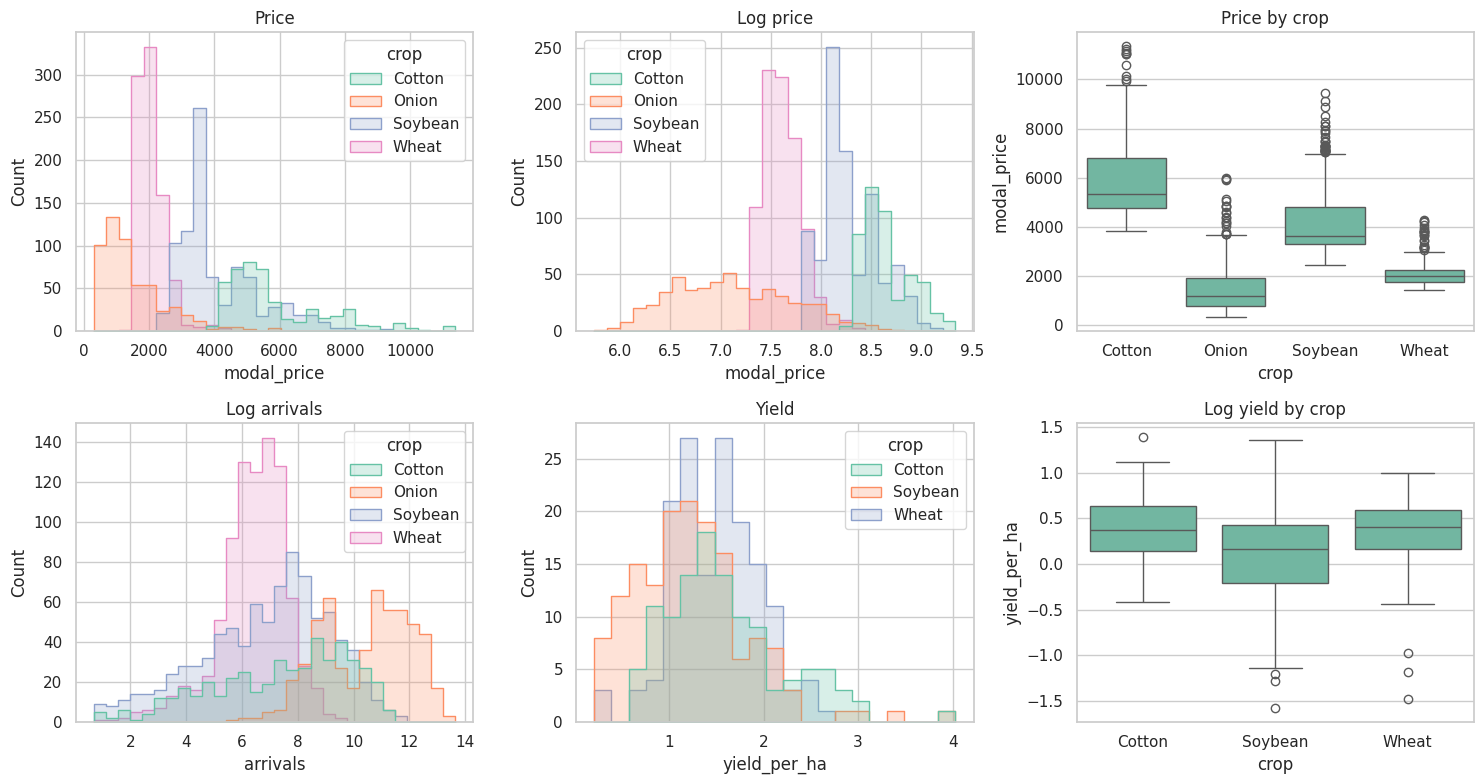

In [ ]:
fig, ax = plt.subplots(2, 3, figsize=(15, 8))
sns.histplot(data=real, x="modal_price", hue="crop", element="step", ax=ax[0, 0]); ax[0, 0].set_title("Price")
sns.histplot(x=np.log(real.modal_price), hue=real.crop, element="step", ax=ax[0, 1]); ax[0, 1].set_title("Log price")
sns.boxplot(data=real, x="crop", y="modal_price", ax=ax[0, 2]); ax[0, 2].set_title("Price by crop")
sns.histplot(x=np.log1p(real.arrivals), hue=real.crop, element="step", ax=ax[1, 0]); ax[1, 0].set_title("Log arrivals")
sns.histplot(data=y, x="yield_per_ha", hue="crop", element="step", ax=ax[1, 1]); ax[1, 1].set_title("Yield")
sns.boxplot(x=y.crop, y=np.log(y.yield_per_ha), ax=ax[1, 2]); ax[1, 2].set_title("Log yield by crop")
plt.tight_layout(); plt.show()

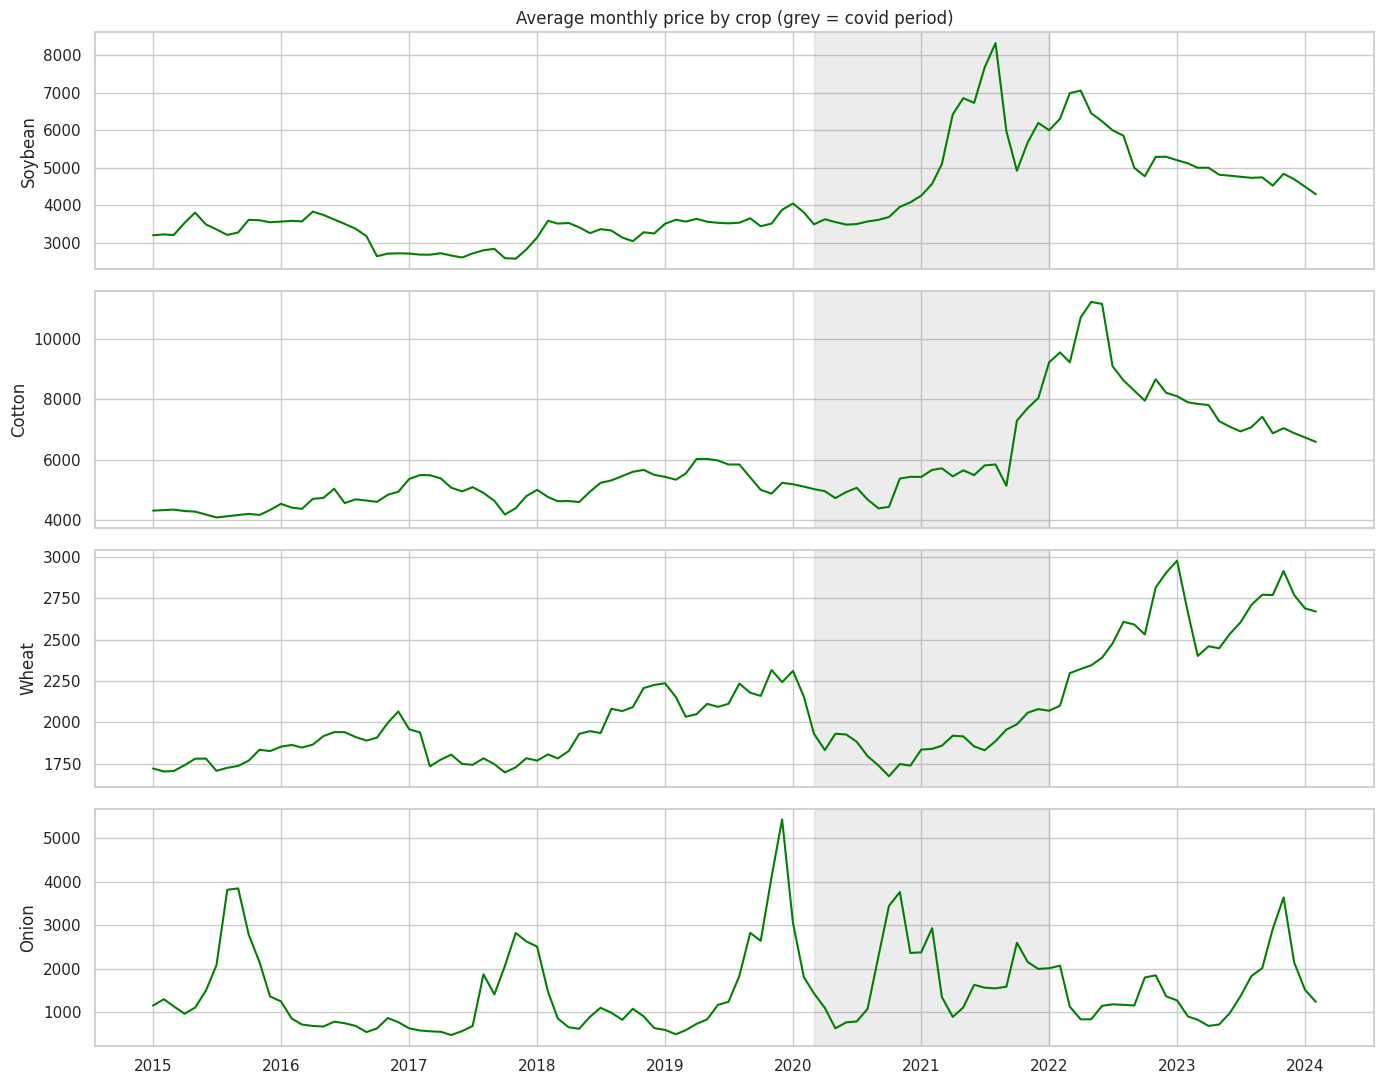

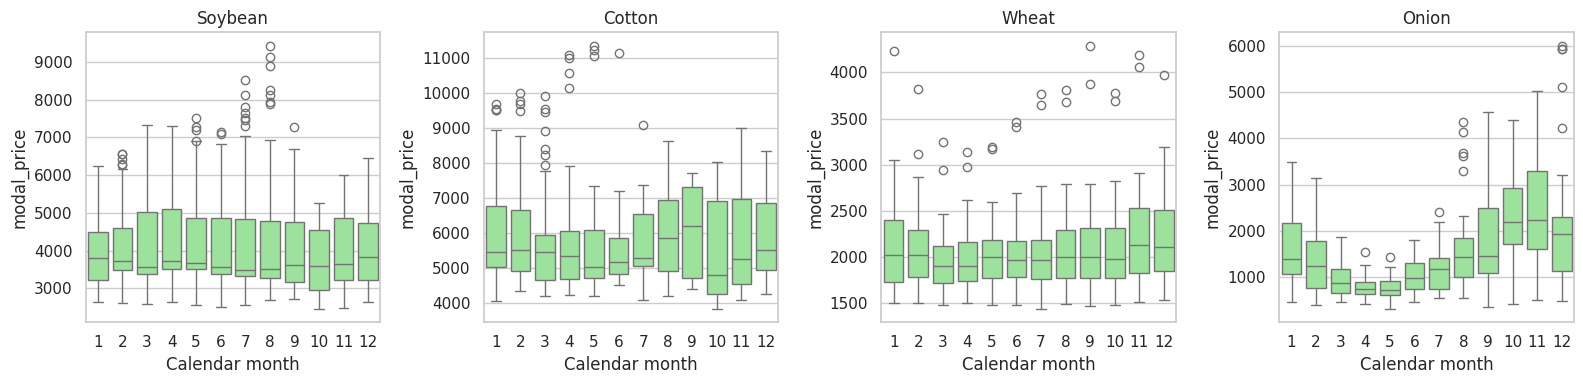

Soybean Latur: seasonal strength = 0.13
Wheat Pune: seasonal strength = 0.00
Onion Nashik: seasonal strength = 0.34


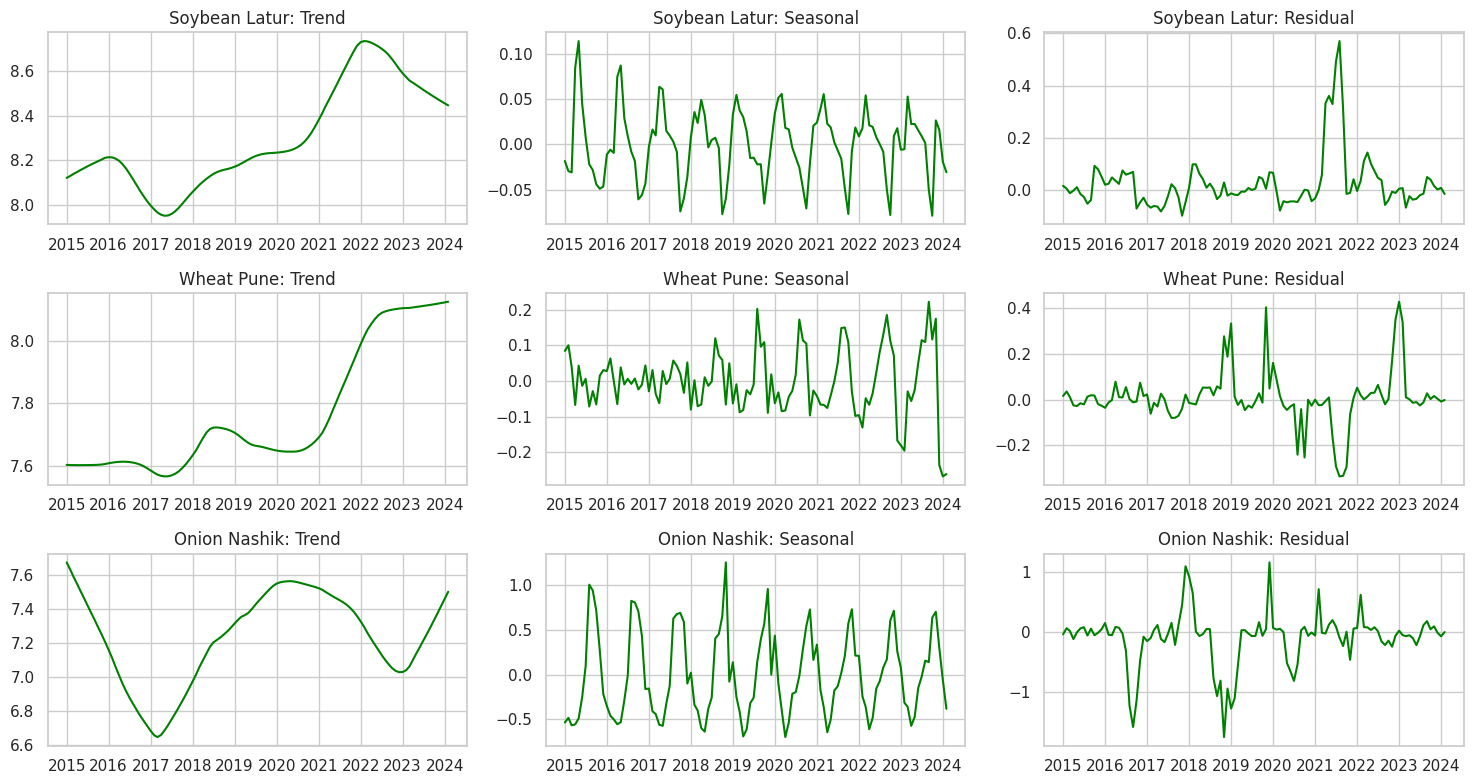

In [ ]:
fig, ax = plt.subplots(4, 1, figsize=(14, 11), sharex=True)
for a, c in zip(ax, CROPS):
    m = real[real.crop == c].groupby("month").modal_price.mean()
    a.plot(m.index, m.values, color="green"); a.set_ylabel(c)
    a.axvspan(pd.Timestamp("2020-03-01"), pd.Timestamp("2021-12-31"), color="grey", alpha=.15)
ax[0].set_title("Average monthly price by crop (grey = covid period)")
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(1, 4, figsize=(16, 4))
for a, c in zip(ax, CROPS):
    d = real[real.crop == c]
    sns.boxplot(x=d.month.dt.month, y=d.modal_price, ax=a, color="lightgreen"); a.set_title(c); a.set_xlabel("Calendar month")
plt.tight_layout(); plt.show()

ex = [("Soybean", "Latur"), ("Wheat", "Pune"), ("Onion", "Nashik")]
fig, ax = plt.subplots(3, 3, figsize=(15, 8))
for i, (c, d) in enumerate(ex):
    s = p[(p.crop == c) & (p.district == d)].set_index("month").modal_price.asfreq("MS").interpolate().dropna()
    r = STL(np.log(s), period=12, robust=True).fit()
    for j, (comp, nm) in enumerate([(r.trend, "Trend"), (r.seasonal, "Seasonal"), (r.resid, "Residual")]):
        ax[i, j].plot(comp, color="green"); ax[i, j].set_title(f"{c} {d}: {nm}")
    print(f"{c} {d}: seasonal strength = {max(0, 1 - np.var(r.resid) / np.var(r.seasonal + r.resid)):.2f}")
plt.tight_layout(); plt.show()

In [ ]:
rows = []
for name, g in real.groupby("series"):
    if len(g) < 80 or g.month.diff().dt.days.max() > 100:
        continue
    s = np.log(g.set_index("month").modal_price)
    rows.append({"series": name, "crop": g.crop.iloc[0],
                 "ADF p (level)": adfuller(s)[1], "KPSS p (level)": kpss(s, nlags="auto")[1],
                 "ADF p (diff)": adfuller(s.diff().dropna())[1], "KPSS p (diff)": kpss(s.diff().dropna(), nlags="auto")[1]})
st = pd.DataFrame(rows)
print("Series tested:", len(st), "(cotton excluded: seasonal gaps)")
display(st.groupby("crop").median(numeric_only=True).round(3))
print("Share stationary by ADF (p<0.05): level =", round((st["ADF p (level)"] < .05).mean(), 2),
      "| first difference =", round((st["ADF p (diff)"] < .05).mean(), 2))

Series tested: 21 (cotton excluded: seasonal gaps)


,ADF p (level),KPSS p (level),ADF p (diff),KPSS p (diff)
crop,,,,
Onion,0.027,0.10,0.0,0.1
Soybean,0.540,0.01,0.0,0.1
Wheat,0.615,0.01,0.0,0.1


Share stationary by ADF (p<0.05): level = 0.14 | first difference = 1.0


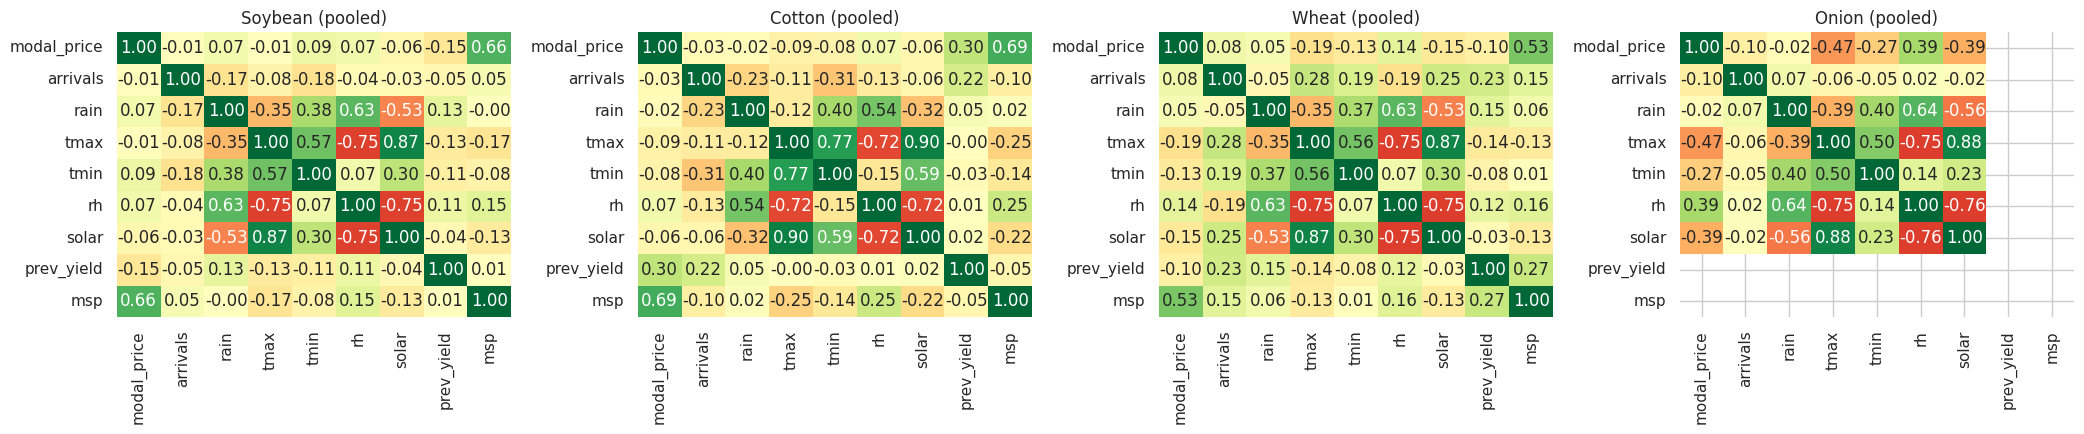

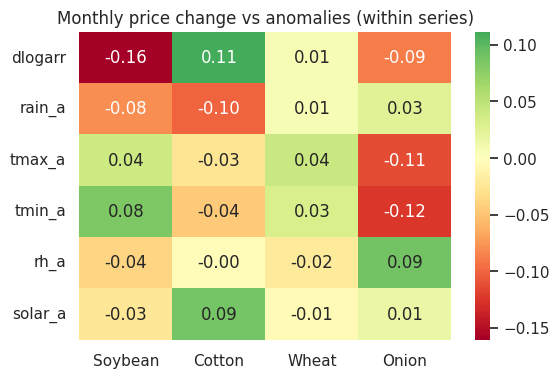

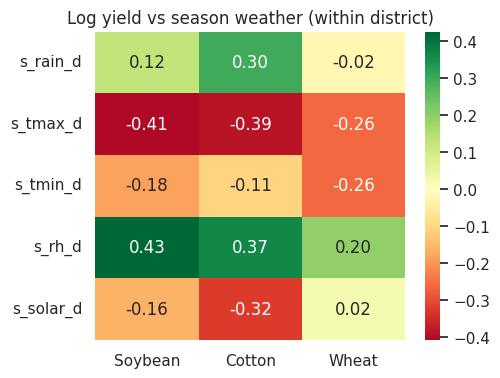

VIF, monthly weather


,0
rain,3.2
tmax,45.0
tmin,17.3
rh,17.3
solar,6.3
wind,1.9


VIF, season weather


,0
s_rain,8.1
s_tmax,19.1
s_tmin,51.9
s_rh,44.5
s_solar,4.5
s_wind,3.3


In [ ]:
cols = ["modal_price", "arrivals", "rain", "tmax", "tmin", "rh", "solar", "prev_yield", "msp"]
fig, ax = plt.subplots(1, 4, figsize=(21, 4.5))
for a, c in zip(ax, CROPS):
    sns.heatmap(real[real.crop == c][cols].corr(), annot=True, fmt=".2f", cmap="RdYlGn", center=0, ax=a, cbar=False); a.set_title(c + " (pooled)")
plt.tight_layout(); plt.show()

q = p.sort_values(["series", "month"]).copy(); g = q.groupby("series")
q["dlogp"] = g.modal_price.transform(lambda s: np.log(s).diff())
q["dlogarr"] = g.arrivals.transform(lambda s: np.log1p(s).diff())
ok = (q.traded == 1) & (g.traded.shift(1) == 1)
for c in ["rain", "tmax", "tmin", "rh", "solar"]:
    q[c + "_a"] = q[c] - q.groupby(["series", q.month.dt.month])[c].transform("mean")
cc = ["dlogarr", "rain_a", "tmax_a", "tmin_a", "rh_a", "solar_a"]
w = pd.DataFrame({k: q[ok & (q.crop == k)][cc + ["dlogp"]].corr()["dlogp"].drop("dlogp") for k in CROPS})
plt.figure(figsize=(6, 4)); sns.heatmap(w, annot=True, fmt=".2f", cmap="RdYlGn", center=0)
plt.title("Monthly price change vs anomalies (within series)"); plt.show()

yc = ["s_rain", "s_tmax", "s_tmin", "s_rh", "s_solar"]
z = y.copy(); z["ly"] = np.log(z.yield_per_ha)
for c in ["ly"] + yc:
    z[c + "_d"] = z[c] - z.groupby(["crop", "district"])[c].transform("mean")
t8 = pd.DataFrame({k: z[z.crop == k][[c + "_d" for c in yc] + ["ly_d"]].corr()["ly_d"].drop("ly_d") for k in ["Soybean", "Cotton", "Wheat"]})
plt.figure(figsize=(5, 4)); sns.heatmap(t8, annot=True, fmt=".2f", cmap="RdYlGn", center=0)
plt.title("Log yield vs season weather (within district)"); plt.show()

def vif(df, cols):
    X = df[cols].dropna(); X = (X - X.mean()) / X.std()
    return pd.Series([variance_inflation_factor(X.values, i) for i in range(len(cols))], index=cols).round(1)
print("VIF, monthly weather"); display(vif(p.drop_duplicates(["district", "month"]), ["rain", "tmax", "tmin", "rh", "solar", "wind"]))
print("VIF, season weather"); display(vif(y, ["s_rain", "s_tmax", "s_tmin", "s_rh", "s_solar", "s_wind"]))

In [ ]:
q2 = p.sort_values(["series", "month"]).copy()
q2["roll_med"] = q2.groupby("series").modal_price.transform(lambda s: s.rolling(7, center=True, min_periods=3).median())
q2["ratio"] = q2.modal_price / q2.roll_med
fl = q2[(q2.traded == 1) & ((q2.ratio < 0.6) | (q2.ratio > 1.6))]
print("Price months flagged:", len(fl), "of", int(q2.traded.sum()))
display(fl.groupby("crop").size().rename("flagged"))
display(fl.sort_values("ratio")[["crop", "district", "month", "modal_price", "roll_med", "ratio"]].head(10))
y2 = y.copy(); y2["ratio"] = y2.yield_per_ha / y2.groupby(["crop", "district"]).yield_per_ha.transform("median")
display(y2[(y2.ratio < 0.35) | (y2.ratio > 2.2)][["crop", "district", "year", "area_ha", "yield_per_ha", "ratio"]])

Price months flagged: 29 of 2762


,flagged
crop,
Onion,29


,crop,district,month,modal_price,roll_med,ratio
845,Onion,Aurangabad,2021-04-01,766.445917,1492.946128,0.513378
944,Onion,Nagpur,2020-05-01,729.525483,1330.527457,0.548298
810,Onion,Aurangabad,2018-05-01,456.939955,833.105578,0.548478
1065,Onion,Nashik,2021-04-01,910.612832,1654.256262,0.550467
735,Onion,Ahmednagar,2021-04-01,816.308061,1475.873423,0.553102
724,Onion,Ahmednagar,2020-05-01,535.721019,940.130538,0.569837
834,Onion,Aurangabad,2020-05-01,436.963240,747.978437,0.584192
778,Onion,Aurangabad,2015-09-01,2789.864865,1740.367776,1.603032
667,Onion,Ahmednagar,2015-08-01,3609.175740,2230.070455,1.618413
1048,Onion,Nashik,2019-11-01,5033.018718,3075.066765,1.636719


,crop,district,year,area_ha,yield_per_ha,ratio
31,Cotton,Buldhana,2013,227900.0,2.806494,2.234518
34,Cotton,Buldhana,2016,169550.0,3.046889,2.425920
72,Cotton,Nagpur,2016,136500.0,4.030769,2.812017
140,Soybean,Akola,2008,137500.0,0.205818,0.200670
146,Soybean,Akola,2014,233100.0,0.298584,0.291116
176,Soybean,Latur,2006,155400.0,0.278636,0.257732
185,Soybean,Latur,2015,340800.0,0.319836,0.295841
254,Soybean,Yavatmal,2008,311800.0,0.332585,0.297960
260,Soybean,Yavatmal,2014,306000.0,0.318954,0.285749
336,Wheat,Latur,2014,47200.0,0.228814,0.217801


In [ ]:
yc = ["s_rain", "s_tmax", "s_tmin", "s_rh", "s_solar", "s_wind"]
d = y.copy()
for c in yc:
    d[c] = d[c] - d.groupby(["crop", "district"])[c].transform("mean")
print("VIF on within-district deviations"); display(vif(d, yc))

cols = yc.copy()
while True:
    v = vif(d, cols)
    if v.max() < 5 or len(cols) <= 2:
        break
    print("dropping", v.idxmax(), "VIF", v.max()); cols.remove(v.idxmax())
print("Reduced set:", cols); display(vif(d, cols))

VIF on within-district deviations


,0
s_rain,1.4
s_tmax,13.9
s_tmin,2.9
s_rh,8.1
s_solar,2.5
s_wind,1.2


dropping s_tmax VIF 13.9
Reduced set: ['s_rain', 's_tmin', 's_rh', 's_solar', 's_wind']


,0
s_rain,1.3
s_tmin,1.1
s_rh,1.6
s_solar,1.8
s_wind,1.1


In [ ]:
rows = []
for name, g in p.groupby("series"):
    if g.crop.iloc[0] == "Cotton":
        continue
    s = g.set_index("month").modal_price.asfreq("MS").interpolate().dropna()
    if len(s) < 60:
        continue
    r = STL(np.log(s), period=12, robust=True).fit()
    rows.append({"crop": g.crop.iloc[0],
                 "seasonal": max(0, 1 - np.var(r.resid) / np.var(r.seasonal + r.resid)),
                 "trend": max(0, 1 - np.var(r.resid) / np.var(r.trend + r.resid))})
sd = pd.DataFrame(rows)
display(sd.groupby("crop")[["seasonal", "trend"]].agg(["median", "min", "max"]).round(2))

seasonal              trend            
          median   min   max median   min   max
crop                                           
Onion       0.46  0.34  0.48   0.41  0.31  0.49
Soybean     0.16  0.13  0.20   0.89  0.86  0.90
Wheat       0.10  0.00  0.51   0.83  0.66  0.94

In [ ]:
rows = []
for name, g in p.groupby("series"):
    if g.crop.iloc[0] != "Wheat":
        continue
    s = g.set_index("month").modal_price.asfreq("MS").interpolate().dropna()
    r = STL(np.log(s), period=12, robust=True).fit()
    rows.append((name, round(max(0, 1 - np.var(r.resid) / np.var(r.seasonal + r.resid)), 2)))
print(sorted(rows, key=lambda t: -t[1]))

[('Wheat_Nagpur', 0.51), ('Wheat_Yavatmal', 0.13), ('Wheat_Aurangabad', 0.12), ('Wheat_Latur', 0.12), ('Wheat_Akola', 0.07), ('Wheat_Ahmednagar', 0.06), ('Wheat_Nashik', 0), ('Wheat_Pune', 0)]


In [ ]:
from google.colab import drive
drive.mount('/content/drive')
!pip install -q shap
import os, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import RidgeCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="Set2")
os.chdir("/content/drive/MyDrive/crop_project"); os.makedirs("outputs", exist_ok=True)
p = pd.read_csv("panel/joint_panel_v3.csv", parse_dates=["month"])
y = pd.read_csv("panel/yield_panel_clean.csv")
def xgb(): return XGBRegressor(n_estimators=300, learning_rate=0.03, max_depth=3, subsample=0.8, colsample_bytree=0.8, min_child_weight=10, reg_lambda=1.0, random_state=42, n_jobs=-1)
def lgbm(): return LGBMRegressor(n_estimators=300, learning_rate=0.03, num_leaves=15, min_child_samples=20, subsample=0.8, subsample_freq=1, colsample_bytree=0.8, reg_lambda=1.0, random_state=42, verbose=-1)
def hgb(cat=None): return HistGradientBoostingRegressor(max_iter=300, learning_rate=0.03, max_depth=4, min_samples_leaf=20, l2_regularization=1.0, categorical_features=cat, random_state=42)
def acc(a, f):
    a, f = np.asarray(a, float), np.asarray(f, float)
    ok = ~np.isnan(f); a, f = a[ok], f[ok]
    return pd.Series({"MAPE%": np.mean(np.abs((a - f) / a)) * 100, "MAE": np.mean(np.abs(a - f)), "RMSE": np.sqrt(np.mean((a - f) ** 2)), "n": len(a)})
print(p.shape, y.shape)

Mounted at /content/drive
(2970, 26) (418, 15)


In [ ]:
y = y.sort_values(["crop", "district", "year"]).reset_index(drop=True)
y["series"] = y.crop + "_" + y.district
g = y.groupby("series")
y["y_lag1"] = g.yield_per_ha.shift(1); y["y_lag2"] = g.yield_per_ha.shift(2)
y["y_roll3"] = g.yield_per_ha.transform(lambda s: s.shift(1).rolling(3, min_periods=2).mean())
y["log_area"] = np.log(y.area_ha); y["area_chg"] = y.log_area - g.log_area.shift(1)
for c in ["s_rain", "s_tmax", "s_tmin"]:
    y[c + "_anom"] = y[c] - g[c].transform(lambda s: s.shift(1).expanding(min_periods=3).mean())
y["crop_c"] = y.crop.astype("category").cat.codes; y["district_c"] = y.district.astype("category").cat.codes
YF = ["y_lag1", "y_lag2", "y_roll3", "log_area", "area_chg", "s_rain", "s_tmax", "s_tmin", "s_rh", "s_solar", "s_wind",
      "s_rain_anom", "s_tmax_anom", "s_tmin_anom", "year", "crop_c", "district_c"]
YR = [f for f in YF if f != "s_tmax"]
yd = y.dropna(subset=["y_lag1", "y_roll3"]).copy()
yd["target"] = np.log(yd.yield_per_ha) - np.log(yd.y_roll3)
def ym(name):
    if name in ("ridge", "ridge_reduced"):
        return make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), RidgeCV(alphas=np.logspace(-2, 3, 20)))
    if name == "rf":
        return make_pipeline(SimpleImputer(strategy="median"), RandomForestRegressor(n_estimators=300, min_samples_leaf=3, random_state=42, n_jobs=-1))
    if name == "hgb": return hgb()
    return {"xgb": xgb, "lgbm": lgbm}[name]()
YMODELS = ["ridge", "ridge_reduced", "rf", "hgb", "xgb", "lgbm"]
out = []
for ty in range(2012, 2020):
    tr, te = yd[yd.year < ty], yd[yd.year == ty].copy()
    for n in YMODELS:
        cols = YR if n == "ridge_reduced" else YF
        m = ym(n).fit(tr[cols], tr.target)
        te[n] = te.y_roll3 * np.exp(m.predict(te[cols]))
    out.append(te)
YR_ = pd.concat(out); YR_["naive_last"] = YR_.y_lag1; YR_["naive_roll3"] = YR_.y_roll3
YR_.to_csv("panel/yield_preds_stage3.csv", index=False)
rows = {}
for mo in ["naive_last", "naive_roll3"] + YMODELS:
    for crop, x in list(YR_.groupby("crop")) + [("ALL", YR_)]:
        rows[(mo, crop)] = acc(x.yield_per_ha, x[mo])
yield_tab = pd.DataFrame(rows).T
yield_tab["skill vs naive_roll3 (MAE)"] = [1 - yield_tab.loc[(m, c), "MAE"] / yield_tab.loc[("naive_roll3", c), "MAE"] for m, c in yield_tab.index]
yield_tab = yield_tab.round(3); yield_tab.to_csv("outputs/yield_comparison.csv")
display(yield_tab)

MAPE%    MAE   RMSE      n  skill vs naive_roll3 (MAE)
naive_last    Cotton   54.347  0.837  1.059   48.0                      -0.338
              Soybean  60.728  0.534  0.702   64.0                      -0.053
              Wheat    34.248  0.378  0.481   64.0                      -0.051
              ALL      49.359  0.560  0.755  176.0                      -0.152
naive_roll3   Cotton   40.219  0.625  0.816   48.0                       0.000
              Soybean  66.848  0.507  0.632   64.0                       0.000
              Wheat    36.327  0.360  0.445   64.0                       0.000
              ALL      48.487  0.486  0.632  176.0                       0.000
ridge         Cotton   39.385  0.689  0.892   48.0                      -0.102
              Soybean  51.919  0.461  0.620   64.0                       0.092
              Wheat    43.830  0.445  0.581   64.0                      -0.238
              ALL      45.559  0.517  0.692  176.0                      -0.065
ridge_reduced Cotton   41.056  0.695  0.894   48.0                      -0.112
              Soybean  54.271  0.476  0.638   64.0                       0.063
              Wheat    44.456  0.463  0.602   64.0                      -0.287
              ALL      47.098  0.531  0.706  176.0                      -0.092
rf            Cotton   36.921  0.612  0.871   48.0                       0.021
              Soybean  53.839  0.474  0.600   64.0                       0.065
              Wheat    39.559  0.420  0.536   64.0                      -0.169
              ALL      44.032  0.492  0.665  176.0                      -0.013
hgb           Cotton   38.408  0.617  0.869   48.0                       0.013
              Soybean  56.231  0.491  0.613   64.0                       0.033
              Wheat    41.780  0.434  0.536   64.0                      -0.207
              ALL      46.115  0.505  0.669  176.0                      -0.039
xgb           Cotton   37.401  0.600  0.839   48.0                       0.041
              Soybean  55.914  0.498  0.612   64.0                       0.019
              Wheat    40.091  0.411  0.508   64.0                      -0.142
              ALL      45.111  0.494  0.649  176.0                      -0.016
lgbm          Cotton   37.172  0.604  0.843   48.0                       0.034
              Soybean  56.285  0.493  0.608   64.0                       0.028
              Wheat    42.330  0.429  0.539   64.0                      -0.194
              ALL      45.997  0.500  0.659  176.0                      -0.030

In [ ]:
df = p.sort_values(["crop", "district", "month"]).reset_index(drop=True)
df["series"] = df.crop + "_" + df.district
g = df.groupby("series")
for k in [1, 2, 3, 6, 12]: df[f"p_lag{k}"] = g.modal_price.shift(k)
df["p_roll3"] = g.modal_price.transform(lambda s: s.shift(1).rolling(3, min_periods=1).mean())
df["p_roll6"] = g.modal_price.transform(lambda s: s.shift(1).rolling(6, min_periods=1).mean())
df["p_last_obs"] = g.modal_price.transform(lambda s: s.shift(1).ffill())
df["arr_lag1"] = g.arrivals.shift(1); df["arr_roll3"] = g.arrivals.transform(lambda s: s.shift(1).rolling(3, min_periods=1).mean())
for c in ["rain", "tmax", "tmin", "rh", "solar"]: df[f"{c}_l1"] = g[c].shift(1)
df["rain_3m"] = g.rain.transform(lambda s: s.shift(1).rolling(3, min_periods=3).sum())
df["crop_c"] = df.crop.astype("category").cat.codes; df["district_c"] = df.district.astype("category").cat.codes
d = df[(df.traded == 1) & df.modal_price.notna()].copy()
d["naive"] = d.p_lag1.fillna(d.p_last_obs); d = d.dropna(subset=["naive"]).copy()
for c in ["p_lag2", "p_lag3", "p_lag6", "p_lag12", "p_roll3", "p_roll6"]: d[c + "_r"] = np.log(d[c]) - np.log(d.naive)
d["arr_l1_log"] = np.log1p(d.arr_lag1); d["arr_r3_log"] = np.log1p(d.arr_roll3)
BASEF = ["p_lag2_r", "p_lag3_r", "p_lag6_r", "p_lag12_r", "p_roll3_r", "p_roll6_r", "arr_l1_log", "arr_r3_log",
         "rain_l1", "tmax_l1", "tmin_l1", "rh_l1", "solar_l1", "rain_3m", "covid", "prev_yield", "crop_c", "district_c"]
MSPF = ["msp", "msp_growth", "price_to_msp", "has_msp"]
store, res = {}, []
for h in [1, 3, 6]:
    df["y_t"] = g.modal_price.shift(-(h - 1)); df["y_tr"] = g.traded.shift(-(h - 1))
    dh = d.merge(df[["series", "month", "y_t", "y_tr"]], on=["series", "month"], how="left")
    dh = dh[(dh.y_tr == 1) & dh.y_t.notna()].copy()
    dh["tmonth"] = dh.month + pd.DateOffset(months=h - 1)
    dh["tyear"] = dh.tmonth.dt.year
    dh["tm_sin"] = np.sin(2 * np.pi * dh.tmonth.dt.month / 12); dh["tm_cos"] = np.cos(2 * np.pi * dh.tmonth.dt.month / 12)
    F0 = BASEF + ["tm_sin", "tm_cos"]; F1 = F0 + MSPF
    store[h] = (dh, F0, F1)
    for ty in [2019, 2020, 2021, 2022, 2023]:
        tr, te = dh[dh.tmonth < f"{ty}-01-01"], dh[dh.tyear == ty].copy()
        tgt = np.log(tr.y_t) - np.log(tr.naive)
        for name, mk, F in [("hgb_noMSP", lambda: hgb([f in ("crop_c", "district_c") for f in F0]), F0),
                            ("hgb_MSP", lambda: hgb([f in ("crop_c", "district_c") for f in F1]), F1),
                            ("xgb_MSP", xgb, F1), ("lgbm_MSP", lgbm, F1)]:
            te[name] = te.naive * np.exp(mk().fit(tr[F], tgt).predict(te[F]))
        te["h"] = h; res.append(te)
PR = pd.concat(res); PR["naive_"] = PR.naive
PR.to_csv("panel/price_preds_stage3.csv", index=False)
PM = ["naive_", "hgb_noMSP", "hgb_MSP", "xgb_MSP", "lgbm_MSP"]
rows = {}
for h, xh in PR.groupby("h"):
    for mo in PM:
        for crop, x in list(xh.groupby("crop")) + [("ALL", xh)]:
            rows[(h, mo, crop)] = acc(x.y_t, x[mo])
price_tab = pd.DataFrame(rows).T
price_tab["skill vs naive (MAE)"] = [1 - price_tab.loc[(h, m, c), "MAE"] / price_tab.loc[(h, "naive_", c), "MAE"] for h, m, c in price_tab.index]
price_tab = price_tab.round(3); price_tab.to_csv("outputs/price_comparison.csv")
print("OVERALL"); display(price_tab.xs("ALL", level=2))
print("BY CROP, MAPE%"); display(price_tab["MAPE%"].unstack(1))

OVERALL


MAPE%      MAE      RMSE       n  skill vs naive (MAE)
1 naive_      9.731  290.637   515.645  1509.0                 0.000
  hgb_noMSP  10.482  349.529   633.948  1509.0                -0.203
  hgb_MSP    10.374  339.340   607.547  1509.0                -0.168
  xgb_MSP    10.053  327.566   582.683  1509.0                -0.127
  lgbm_MSP   10.311  343.698   603.271  1509.0                -0.183
3 naive_     20.459  542.837   857.852  1454.0                 0.000
  hgb_noMSP  17.490  583.370   968.457  1454.0                -0.075
  hgb_MSP    17.486  579.513   948.118  1454.0                -0.068
  xgb_MSP    17.405  568.941   892.471  1454.0                -0.048
  lgbm_MSP   18.978  643.206  1096.375  1454.0                -0.185
6 naive_     30.335  755.727  1191.885  1413.0                 0.000
  hgb_noMSP  24.881  799.257  1290.027  1413.0                -0.058
  hgb_MSP    24.857  818.291  1307.399  1413.0                -0.083
  xgb_MSP    25.457  849.760  1369.045  1413.0                -0.124
  lgbm_MSP   29.498  979.596  1590.948  1413.0                -0.296

BY CROP, MAPE%


hgb_MSP  hgb_noMSP  lgbm_MSP  naive_  xgb_MSP
1 ALL       10.374     10.482    10.311   9.731   10.053
  Cotton     7.534      7.585     7.745   5.632    7.119
  Onion     27.772     27.381    26.104  27.376   26.451
  Soybean    6.393      6.972     6.840   5.758    6.495
  Wheat      4.924      4.907     5.215   4.795    4.861
3 ALL       17.486     17.490    18.978  20.459   17.405
  Cotton    14.234     13.455    15.328   9.605   14.726
  Onion     38.186     38.120    37.746  61.989   39.499
  Soybean   13.961     14.738    16.129  11.046   13.291
  Wheat      9.313      8.930    11.528   8.302    8.687
6 ALL       24.857     24.881    29.498  30.335   25.457
  Cotton    23.412     19.459    25.390  14.521   24.938
  Onion     54.177     55.619    54.561  93.831   54.193
  Soybean   20.292     20.194    26.481  14.914   20.994
  Wheat     11.343     11.984    18.067  11.067   11.884

In [ ]:
with pd.ExcelWriter("outputs/model_comparison.xlsx") as xw:
    price_tab.to_excel(xw, sheet_name="price"); yield_tab.to_excel(xw, sheet_name="yield")
best_p = price_tab.xs("ALL", level=2)["MAPE%"].unstack(1)
best_p["best model"] = best_p.idxmin(axis=1)
print("Price: best model by horizon (overall MAPE%)"); display(best_p.round(2))
by = yield_tab.xs("ALL", level=1)[["MAPE%", "MAE", "skill vs naive_roll3 (MAE)"]]
print("Yield (ALL crops; use MAPE% and skill)"); display(by.sort_values("MAPE%"))

Price: best model by horizon (overall MAPE%)


,hgb_MSP,hgb_noMSP,lgbm_MSP,naive_,xgb_MSP,best model
1,10.37,10.48,10.31,9.73,10.05,naive_
3,17.49,17.49,18.98,20.46,17.40,xgb_MSP
6,24.86,24.88,29.50,30.34,25.46,hgb_MSP


Yield (ALL crops; use MAPE% and skill)


,MAPE%,MAE,skill vs naive_roll3 (MAE)
rf,44.032,0.492,-0.013
xgb,45.111,0.494,-0.016
ridge,45.559,0.517,-0.065
lgbm,45.997,0.500,-0.030
hgb,46.115,0.505,-0.039
ridge_reduced,47.098,0.531,-0.092
naive_roll3,48.487,0.486,0.000
naive_last,49.359,0.560,-0.152


Season-level rows: 108


,crop,n,r,CI low,CI high,p
0,Cotton,28,0.580,0.263,0.783,0.001
1,Soybean,40,-0.173,-0.460,0.147,0.286
2,Wheat,40,-0.162,-0.451,0.157,0.318
3,ALL,108,0.009,-0.181,0.197,0.928


Pooled regression with crop effects: slope = 0.000, 95% CI [-0.068, 0.069], p = 0.992


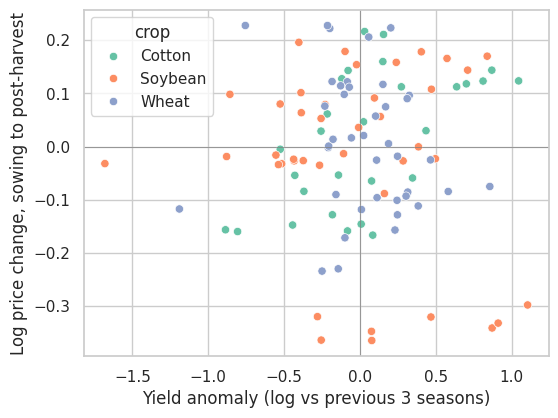

In [ ]:
from scipy import stats
import statsmodels.formula.api as smf
ys = y.copy(); ys["yield_anom"] = np.log(ys.yield_per_ha / ys.y_roll3)
pr = p[p.traded == 1]
def wmean(sub, a, b):
    x = sub[(sub.month >= a) & (sub.month <= b)].modal_price
    return x.mean() if len(x) else np.nan
rows = []
for (crop, dist), sub in pr.groupby(["crop", "district"]):
    if crop == "Onion": continue
    for yr in range(2015, 2020):
        if crop in ("Soybean", "Cotton"):
            s0, s1, h0, h1 = pd.Timestamp(yr, 4, 1), pd.Timestamp(yr, 5, 1), pd.Timestamp(yr, 12, 1), pd.Timestamp(yr + 1, 2, 1)
        else:
            s0, s1, h0, h1 = pd.Timestamp(yr, 9, 1), pd.Timestamp(yr, 10, 1), pd.Timestamp(yr + 1, 5, 1), pd.Timestamp(yr + 1, 7, 1)
        rows.append({"crop": crop, "district": dist, "year": yr, "price_sow": wmean(sub, s0, s1), "price_harv": wmean(sub, h0, h1)})
sea = pd.DataFrame(rows)
sea["price_chg"] = np.log(sea.price_harv / sea.price_sow)
sea = sea.merge(ys[["crop", "district", "year", "yield_anom"]], on=["crop", "district", "year"], how="left")
dd = sea.dropna(subset=["price_chg", "yield_anom"]).copy()
sea.to_csv("panel/joint_season.csv", index=False)
print("Season-level rows:", len(dd))
out = []
for c, x in list(dd.groupby("crop")) + [("ALL", dd)]:
    r, pv = stats.pearsonr(x.yield_anom, x.price_chg); n = len(x)
    z = np.arctanh(r); lo, hi = np.tanh(z - 1.96 / np.sqrt(n - 3)), np.tanh(z + 1.96 / np.sqrt(n - 3))
    out.append({"crop": c, "n": n, "r": r, "CI low": lo, "CI high": hi, "p": pv})
display(pd.DataFrame(out).round(3))
m = smf.ols("price_chg ~ yield_anom + C(crop)", data=dd).fit(cov_type="HC3")
ci = m.conf_int().loc["yield_anom"]
print(f"Pooled regression with crop effects: slope = {m.params['yield_anom']:.3f}, 95% CI [{ci[0]:.3f}, {ci[1]:.3f}], p = {m.pvalues['yield_anom']:.3f}")
plt.figure(figsize=(6, 4.5)); sns.scatterplot(data=dd, x="yield_anom", y="price_chg", hue="crop")
plt.axhline(0, color="grey", lw=.5); plt.axvline(0, color="grey", lw=.5)
plt.xlabel("Yield anomaly (log vs previous 3 seasons)"); plt.ylabel("Log price change, sowing to post-harvest"); plt.show()

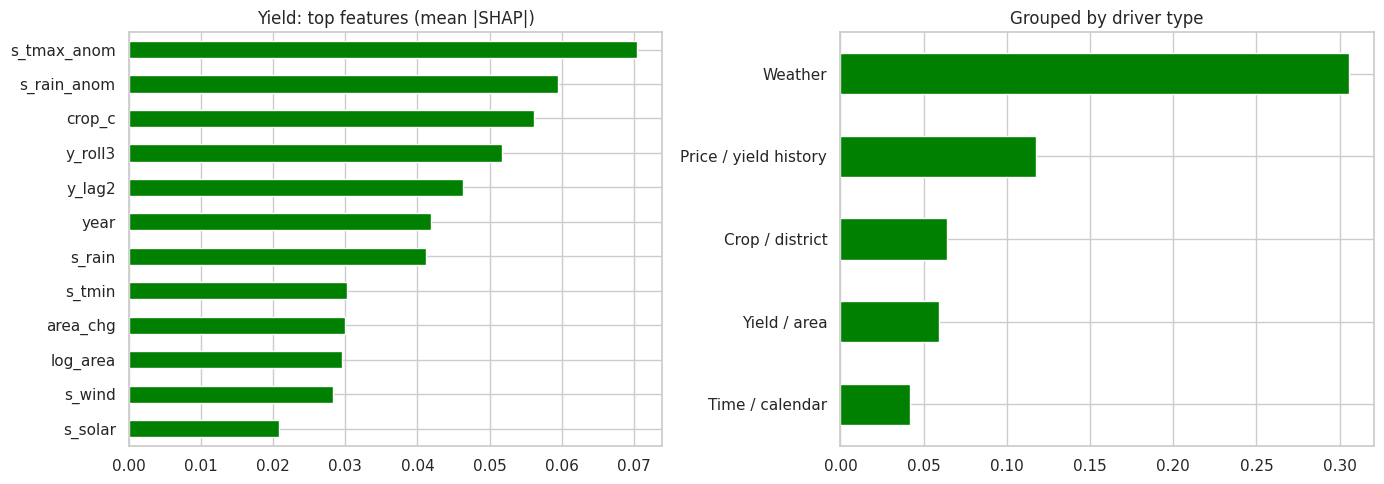

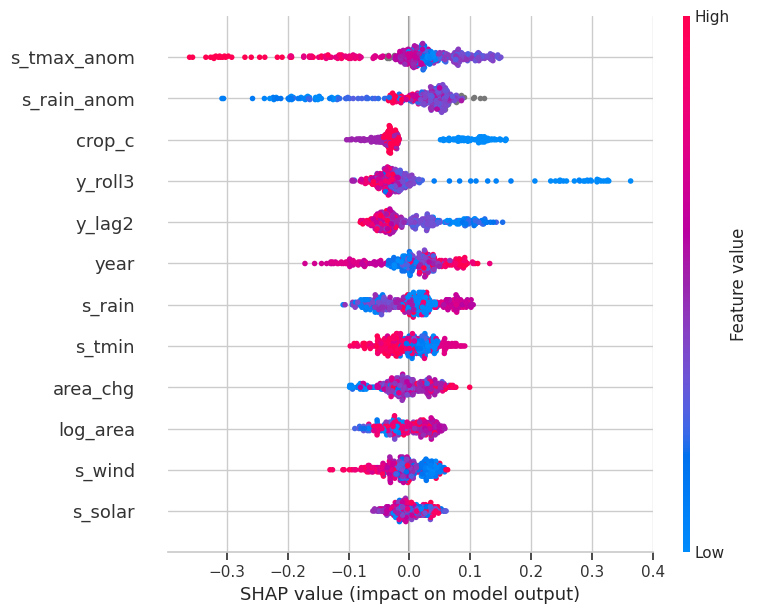

Weather                  52.0
Price / yield history    20.0
Crop / district          10.8
Yield / area             10.1
Time / calendar           7.1
dtype: float64


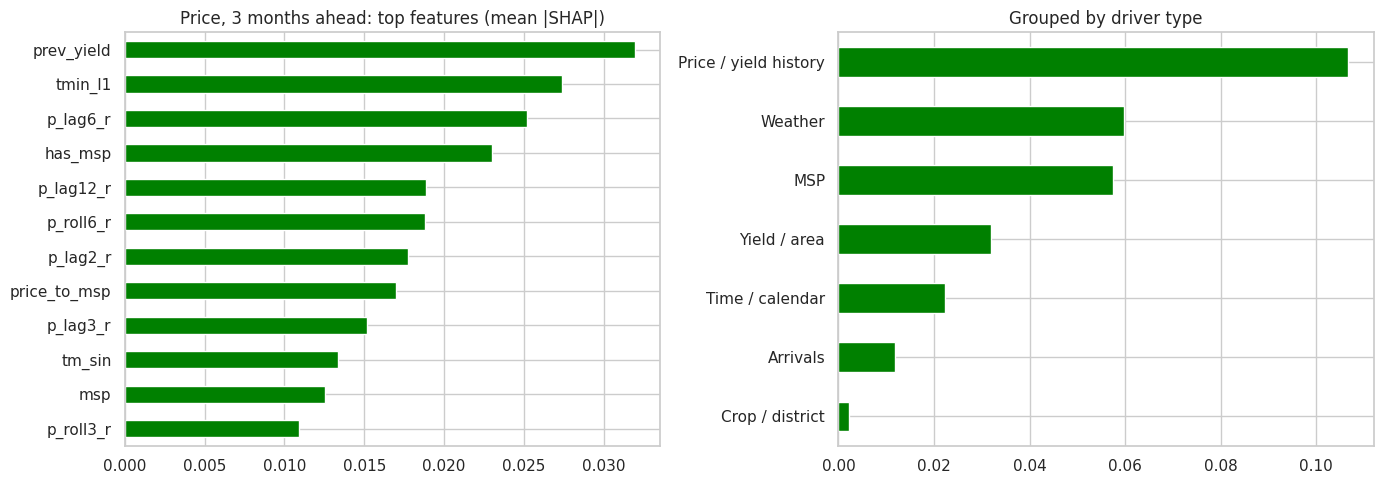

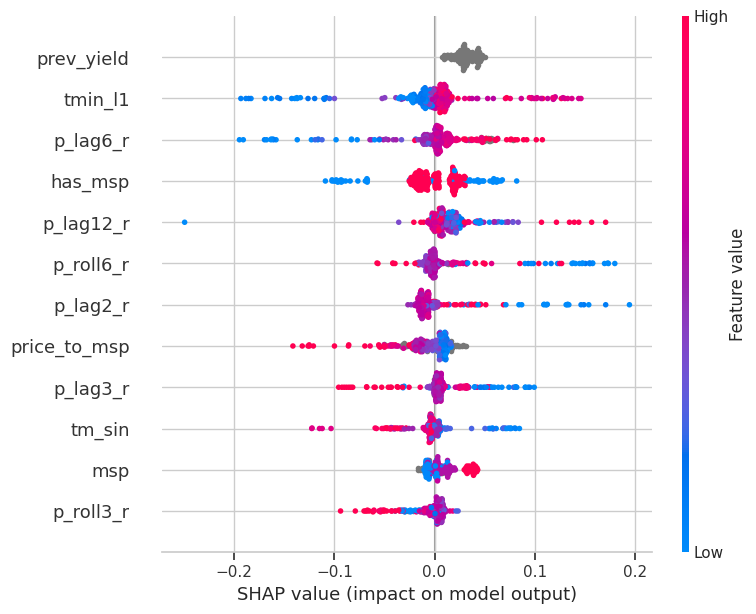

Price / yield history    36.5
Weather                  20.4
MSP                      19.6
Yield / area             10.9
Time / calendar           7.6
Arrivals                  4.0
Crop / district           0.8
dtype: float64


In [ ]:
import shap
def grp(f):
    if f.startswith(("p_", "y_lag", "y_roll")): return "Price / yield history"
    if f.startswith("arr"): return "Arrivals"
    if f.startswith(("rain", "tmax", "tmin", "rh", "solar", "s_")): return "Weather"
    if f in MSPF: return "MSP"
    if f in ("prev_yield", "log_area", "area_chg"): return "Yield / area"
    if f in ("covid", "year") or f.startswith(("tm_", "m_")): return "Time / calendar"
    return "Crop / district"
def shap_plots(model, X, title):
    sv = shap.TreeExplainer(model).shap_values(X)
    imp = pd.Series(np.abs(sv).mean(0), index=X.columns).sort_values(ascending=False)
    gi = imp.groupby(imp.index.map(grp)).sum().sort_values()
    fig, ax = plt.subplots(1, 2, figsize=(14, 5))
    imp.head(12)[::-1].plot.barh(ax=ax[0], color="green"); ax[0].set_title(title + ": top features (mean |SHAP|)")
    gi.plot.barh(ax=ax[1], color="green"); ax[1].set_title("Grouped by driver type")
    plt.tight_layout(); plt.show()
    shap.summary_plot(sv, X, show=True, max_display=12)
    return imp, gi
tr = yd[yd.year < 2019]
my = lgbm().fit(tr[YF], tr.target)
imp_y, gi_y = shap_plots(my, yd[YF], "Yield")
print((gi_y / gi_y.sum() * 100).round(1).sort_values(ascending=False))
dh, F0, F1 = store[3]
trp = dh[dh.tmonth < "2023-01-01"]; tep = dh[dh.tyear == 2023]
mp = lgbm().fit(trp[F1], np.log(trp.y_t) - np.log(trp.naive))
imp_p, gi_p = shap_plots(mp, tep[F1], "Price, 3 months ahead")
print((gi_p / gi_p.sum() * 100).round(1).sort_values(ascending=False))

In [ ]:
from scipy import stats as st
def dm(d, h):
    d = np.asarray(d, float); T = len(d); dbar = d.mean(); L = max(h - 1, 0)
    lrv = np.mean((d - dbar) ** 2)
    for k in range(1, L + 1):
        lrv += 2 * (1 - k / (L + 1)) * np.mean((d[k:] - dbar) * (d[:-k] - dbar))
    if lrv <= 0 or T < 8: return np.nan, np.nan, T
    s = dbar / np.sqrt(lrv / T) * np.sqrt((T + 1 - 2 * h + h * (h - 1) / T) / T)
    return s, 2 * (1 - st.t.cdf(abs(s), T - 1)), T
out = []
for (h, crop), x in PR.groupby(["h", "crop"]):
    for mo in ["hgb_MSP", "xgb_MSP", "lgbm_MSP"]:
        dl = np.abs(x.y_t - x.naive_) / x.y_t - np.abs(x.y_t - x[mo]) / x.y_t
        s = dl.groupby(x.tmonth).mean().sort_index()
        stat, pv, T = dm(s.values, h)
        out.append({"h": h, "crop": crop, "model": mo, "APE gain vs naive (pp)": s.mean() * 100, "DM stat": stat, "p": pv, "T months": T})
dmt = pd.DataFrame(out).round(3); dmt.to_csv("outputs/dm_tests.csv", index=False); display(dmt)

m2 = smf.ols("price_chg ~ yield_anom + C(crop) * C(year)", data=dd).fit(cov_type="HC3")
ci = m2.conf_int().loc["yield_anom"]
print(f"Joint link with crop-by-year effects: slope = {m2.params['yield_anom']:.3f}, 95% CI [{ci[0]:.3f}, {ci[1]:.3f}], p = {m2.pvalues['yield_anom']:.3f}")

,h,crop,model,APE gain vs naive (pp),DM stat,p,T months
0,1,Cotton,hgb_MSP,-1.636,-3.423,0.001,58
1,1,Cotton,xgb_MSP,-1.342,-3.949,0.000,58
2,1,Cotton,lgbm_MSP,-1.730,-3.992,0.000,58
3,1,Onion,hgb_MSP,-0.396,-0.176,0.861,60
4,1,Onion,xgb_MSP,0.924,0.444,0.659,60
5,1,Onion,lgbm_MSP,1.272,0.561,0.577,60
6,1,Soybean,hgb_MSP,-0.638,-1.078,0.286,60
7,1,Soybean,xgb_MSP,-0.736,-1.604,0.114,60
8,1,Soybean,lgbm_MSP,-1.079,-1.578,0.120,60
9,1,Wheat,hgb_MSP,-0.127,-0.852,0.398,60


Joint link with crop-by-year effects: slope = 0.007, 95% CI [-0.046, 0.059], p = 0.801


In [ ]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


In [ ]:
import os, shutil
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
os.chdir("/content/drive/MyDrive/crop_project"); os.makedirs("outputs/figures", exist_ok=True)
p = pd.read_csv("panel/joint_panel_v3.csv", parse_dates=["month"])
y = pd.read_csv("panel/yield_panel_clean.csv")
real = p[p.traded == 1]
PAL = ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728", "#9467bd", "#8c564b", "#e377c2", "#17becf"]
COVID = (pd.Timestamp("2020-03-01"), pd.Timestamp("2021-12-31"))
for crop in ["Soybean", "Cotton", "Wheat", "Onion"]:
    d = real[real.crop == crop]
    fig, ax = plt.subplots(2, 1, figsize=(11, 7), sharex=True, gridspec_kw={"height_ratios": [3, 1.6]})
    for k, (dist, g) in enumerate(d.groupby("district")):
        ax[0].plot(g.month, g.modal_price, label=dist, color=PAL[k % 8], lw=1.6)
        ax[1].plot(g.month, g.arrivals, color=PAL[k % 8], lw=1.2)
    if d.msp.notna().any():
        m = d.groupby("month").msp.mean().dropna()
        ax[0].plot(m.index, m.values, "k--", lw=2.6, label="MSP")
    for a in ax: a.axvspan(*COVID, color="grey", alpha=.15)
    ax[0].set_title(f"{crop}: price by district (dashed = MSP, grey = covid period)"); ax[0].set_ylabel("Rs per quintal")
    ax[1].set_ylabel("Arrivals (tonnes)"); ax[0].legend(ncol=4, fontsize=9, frameon=False)
    plt.tight_layout(); plt.savefig(f"outputs/figures/{crop}_price_arrivals.png", dpi=200, bbox_inches="tight"); plt.close()

cv = real.groupby("crop").modal_price.agg(lambda s: s.std() / s.mean() * 100).sort_values()
plt.figure(figsize=(6, 4)); plt.barh(cv.index, cv.values, color="#1e9e4a")
for i, v in enumerate(cv.values): plt.text(v + .5, i, f"{v:.1f}%", va="center")
plt.title("Price variation by crop (CV %)"); plt.tight_layout()
plt.savefig("outputs/figures/price_cv_by_crop.png", dpi=200, bbox_inches="tight"); plt.close()

for crop in ["Soybean", "Cotton", "Wheat"]:
    q = y[y.crop == crop][["district", "yield_per_ha", "s_tmax", "s_rh"]].dropna()
    ly = np.log(q.yield_per_ha); ly = ly - ly.groupby(q.district).transform("mean")
    fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
    for a, v, nm in [(ax[0], "s_tmax", "Max temperature"), (ax[1], "s_rh", "Humidity")]:
        xs = q[v] - q.groupby("district")[v].transform("mean")
        for k, (dist, idx) in enumerate(q.groupby("district").groups.items()):
            a.scatter(xs[idx], ly[idx], color=PAL[k % 8], s=22, label=dist)
        b = np.polyfit(xs, ly, 1); xl = np.linspace(xs.min(), xs.max(), 20)
        a.plot(xl, np.polyval(b, xl), "k-", lw=2)
        a.set_title(f"{crop}: log yield vs {nm} (r = {np.corrcoef(xs, ly)[0, 1]:.2f})"); a.set_xlabel(nm + " (deviation from district mean)"); a.set_ylabel("Log yield deviation")
    ax[0].legend(fontsize=7, frameon=False, ncol=2)
    plt.tight_layout(); plt.savefig(f"outputs/figures/{crop}_yield_vs_weather.png", dpi=200, bbox_inches="tight"); plt.close()

shutil.make_archive("outputs/figures", "zip", "outputs/figures")
print(sorted(os.listdir("outputs/figures")))
try:
    from google.colab import files; files.download("outputs/figures.zip")
except Exception: pass

['Cotton_price_arrivals.png', 'Cotton_yield_vs_weather.png', 'Onion_price_arrivals.png', 'Soybean_price_arrivals.png', 'Soybean_yield_vs_weather.png', 'Wheat_price_arrivals.png', 'Wheat_yield_vs_weather.png', 'price_cv_by_crop.png']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
"""
build_presentation.py
Builds the interactive project walkthrough (one self-contained HTML file) from
your project's result files. Re-run it after re-running the models and the
presentation updates itself.

Usage:   python build_presentation.py [project_folder] [output.html]
Colab:   mount Drive, then  %run build_presentation.py   (uses /content/drive/MyDrive/crop_project)
Default: project_folder = Drive folder if mounted, else current folder; output = <folder>/outputs/walkthrough.html

Reads (all produced by your notebook), whichever exist:
  panel/joint_panel_v3.csv        -> price mean and CV by crop
  panel/yield_panel_clean.csv     -> yield CV, weather vs yield correlations
  outputs/price_comparison.csv    -> model error (MAPE%) by horizon and crop
  panel/joint_season.csv          -> yield-price link (slope and 95% CI)
Figures (PNG) are read from outputs/figures/ or figures.zip and embedded in the HTML.
Anything missing falls back to the numbers already in the walkthrough, and the
script prints which values were loaded and which were not.
Requires: pandas, numpy only.
"""
import json, os, sys
import numpy as np, pandas as pd

TEMPLATE = r"""<!DOCTYPE html>
<html lang="en"><head><meta charset="utf-8">
<meta name="viewport" content="width=device-width, initial-scale=1, viewport-fit=cover">
<title>Forecasting crop yield and price: project walkthrough</title>
<style>
:root{--bg:#fff;--fg:#111;--mut:#59625d;--card:#eef5f0;--g:#1e9e4a;--bd:#cfd9d2;--neg:#111}
@media (prefers-color-scheme:dark){:root:not([data-theme="light"]){--bg:#0b0d0c;--fg:#f1f3f2;--mut:#a3aea8;--card:#151b17;--g:#38c76d;--bd:#2b352f;--neg:#d4d9d6}}
:root[data-theme="dark"]{--bg:#0b0d0c;--fg:#f1f3f2;--mut:#a3aea8;--card:#151b17;--g:#38c76d;--bd:#2b352f;--neg:#d4d9d6}
:root{box-sizing:border-box;padding-top:env(safe-area-inset-top,0px);padding-bottom:env(safe-area-inset-bottom,0px)}
html{scroll-padding-top:env(safe-area-inset-top,0px)}
*,*::before,*::after{box-sizing:inherit}
html,body{height:100%;margin:0}
body{background:var(--bg);color:var(--fg);font:16px/1.55 system-ui,-apple-system,"Segoe UI",Roboto,Arial,sans-serif;display:flex;flex-direction:column}
.deck{flex:1;overflow-y:auto;padding:28px 24px 12px}
.s{display:none;max-width:900px;margin:0 auto}.s.on{display:block}
h1,h2{font-family:Georgia,"Iowan Old Style","Times New Roman",serif;font-weight:700;line-height:1.15;margin:0 0 14px}
h1{font-size:clamp(30px,6vw,52px)}h2{font-size:clamp(24px,4vw,34px)}
p{margin:0 0 12px;max-width:68ch}.mut{color:var(--mut)}.small{font-size:14px}
.hero{padding-top:6vh}.hero h1{max-width:16ch;margin-bottom:22px}
.hero .t{border-left:3px solid var(--g);padding-left:14px;margin-top:34px;color:var(--mut);font-size:14px;max-width:60ch}
.seg{display:flex;flex-wrap:wrap;gap:8px;margin:14px 0}
.seg button{font:inherit;font-size:15px;padding:8px 14px;border:1px solid var(--bd);background:transparent;color:var(--fg);border-radius:6px;cursor:pointer}
.seg button[aria-pressed=true]{background:var(--g);border-color:var(--g);color:#fff;font-weight:600}
button:focus-visible{outline:2px solid var(--g);outline-offset:2px}
.panel{background:var(--card);border-radius:8px;padding:16px 18px;margin:8px 0 14px;min-height:96px}
.panel b{display:block;margin-bottom:4px}
.row{display:grid;grid-template-columns:110px 1fr 64px;gap:10px;align-items:center;margin:7px 0;font-size:15px}
.row b{text-align:right;font-variant-numeric:tabular-nums}
.track{height:14px;background:var(--card);border-radius:3px;position:relative;overflow:hidden}
.track i{position:absolute;top:0;bottom:0;left:0;background:var(--mut);opacity:.45}
.row.hl .track i,.track i.g{background:var(--g);opacity:1}.row.hl{font-weight:700}
.dv::before{content:"";position:absolute;left:50%;top:0;bottom:0;width:1px;background:var(--mut)}
.dv i{opacity:1}.dv i.n{background:var(--neg);right:50%;left:auto}.dv i.p{background:var(--g);left:50%}
.stats{display:flex;flex-wrap:wrap;gap:24px;margin:6px 0 12px}
.stats div{min-width:120px}.stats strong{display:block;font:700 28px Georgia,serif}
.legend{display:flex;gap:16px;font-size:13px;color:var(--mut);margin:4px 0 10px}
.legend span::before{content:"";display:inline-block;width:10px;height:10px;margin-right:6px;background:var(--g);border-radius:2px}
.legend span.k::before{background:var(--neg)}
details{margin-top:14px;font-size:14px;color:var(--mut)}summary{cursor:pointer;color:var(--fg)}
ul.f{padding-left:20px;max-width:68ch}ul.f li{margin:6px 0}
.cols{display:grid;grid-template-columns:1fr 1fr;gap:28px}
@media(max-width:640px){.cols{grid-template-columns:1fr}.row{grid-template-columns:92px 1fr 54px}}
nav{display:flex;align-items:center;justify-content:space-between;gap:12px;padding:10px 24px 12px;border-top:1px solid var(--bd)}
nav button{font:inherit;padding:8px 18px;border:1px solid var(--bd);background:transparent;color:var(--fg);border-radius:6px;cursor:pointer}
nav button:disabled{opacity:.35;cursor:default}
.dots{display:flex;gap:7px}.dots i{width:9px;height:9px;border-radius:50%;background:var(--bd);cursor:pointer}.dots i.on{background:var(--g)}
</style></head><body>
<main class="deck">
<section class="s on hero"><h1>What will one acre of soybean yield, and what will it sell for?</h1>
<p>Our project forecasts crop yield and market price together, and shows which factors drive each. It uses real weather, market and yield records from Maharashtra.</p>
<div class="t">Explainable multivariate time-series framework for joint crop yield and agricultural price forecasting using machine learning and deep learning. Research Project 24ASH6624, S.Y. M.Sc. Applied Statistics (Data Science).</div></section>

<section class="s"><h2>The idea, step by step</h2>
<p>Choose a step to see what happens and what we measure.</p>
<div class="seg" id="flow"></div><div class="panel" id="flowtxt"></div>
<p class="small mut">Scope: Maharashtra, 11 districts. Soybean, cotton and wheat get both yield and price forecasts; onion gets price only.</p></section>

<section class="s"><h2>Four real datasets</h2>
<div class="seg" id="dsel"></div><div class="panel" id="dtxt"></div>
<p class="small mut">All data is real and public. __BAD__ of __TOT__ daily price records had entry errors (for example wheat priced at Rs 1) and were removed, __PCT__% of the total.</p></section>

<section class="s"><h2>Some crops are far less stable than others</h2>
<div class="seg" id="c4"></div>
<div class="stats" id="st4"></div>
<p class="small mut">Price variation by crop (coefficient of variation, %). The chosen crop is highlighted.</p>
<div id="b4"></div><p id="n4"></p><div id="f4"></div></section>

<section class="s"><h2>Heat hurts yield; humidity helps</h2>
<p>How each season-weather variable moves with yield inside the same district (correlation, range -0.5 to +0.5).</p>
<div class="seg" id="c5"></div>
<div class="legend"><span class="k">Lowers yield</span><span>Raises yield</span></div><div id="b5"></div><div id="f5"></div>
<p class="small mut">Association, not proof of cause. Temperature, humidity and radiation move together, so read them as one group.</p></section>

<section class="s"><h2>Where forecasting models beat last month's price</h2>
<div class="seg" id="c6"></div>
<p class="mut small" id="v6"></p>
<div id="b6"></div><div id="x6"></div>
<details><summary>What do these terms mean?</summary>
<p>Error is the average percentage miss (lower is better). Naive means "next price = this month's price". XGBoost, HGB and LightGBM are machine-learning methods that learn from past data; MSP is the government's minimum support price. Test period: 2019 to 2023, always forecasting from earlier data only.</p></details></section>

<section class="s"><h2>What we found, and what comes next</h2>
<div class="cols"><div><p><b>Findings</b></p><ul class="f">
<li>Onion is the most volatile crop, and the only one where our models clearly beat the naive forecast at 3 months.</li>
<li>Weather explains yield, mostly for rainfed soybean. Irrigated wheat is best forecast by its recent average.</li>
<li>Low yield does not reliably raise price at district level (slope __SLOPE__, 95% interval __LO__ to __HI__).</li>
<li>MSP adds little accuracy.</li></ul></div>
<div><p><b>Next</b></p><ul class="f"><li>LSTM and GRU models</li><li>A two-output model for yield and price together</li><li>Robustness checks and longer yield history</li><li>Report and final presentation</li></ul>
<p class="small mut">Limits: yield data ends in 2019-20, onion has no district yield, yield is a district average.</p></div></div></section>
</main>
<nav><button id="pv">Back</button><div class="dots" id="dots" role="tablist"></div><button id="nx">Next</button></nav>
<script>
const $=s=>document.querySelector(s);
function seg(id,opts,def,cb){const el=$(id);el.innerHTML=opts.map(o=>`<button data-v="${o}">${o}</button>`).join('');
const set=v=>{el.querySelectorAll('button').forEach(b=>b.setAttribute('aria-pressed',b.dataset.v==v));cb(v)};
el.onclick=e=>{if(e.target.dataset.v)set(e.target.dataset.v)};set(def)}
const row=(l,v,max,hl,cls,ex)=>`<div class="row ${hl?'hl':''}"><span>${l}</span><div class="track"><i class="${cls||''}" style="width:${Math.min(100,v/max*100)}%;${ex||''}"></i></div><b>${v}</b></div>`;
const DATA=__DATA__;
const fig=(k,cap)=>{const u=DATA.fig&&DATA.fig[k];return u?`<figure style="margin:16px 0"><img src="${u}" alt="${cap}" style="max-width:100%;height:auto;border-radius:6px;background:#fff"><figcaption class="small mut">${cap}</figcaption></figure>`:''};
const FLOW={"1 Sow":"A farmer picks a crop for the land. Past seasons in the same district show what usually happens next.","2 Season weather":"Rain, heat and humidity through the season decide how well the crop grows. We use NASA weather data for 11 districts.","3 Harvest (yield)":"Yield is crop per hectare (one acre is about 0.4 hectare). Weather is the main driver we can measure.","4 Market price":"After harvest the crop is sold in the mandi. Price depends on recent prices, how much arrives, the season and the government support price. Our models forecast steps 3 and 4."};
seg('#flow',Object.keys(FLOW),"1 Sow",v=>$('#flowtxt').innerHTML=`<b>${v}</b>${FLOW[v]}`);
const D={"Prices":"Daily mandi prices and arrivals, turned into monthly series: 27 crop-district series, Jan 2015 to Feb 2024. Source: Agmarknet-based dataset.","Weather":"Rain, temperature, humidity, solar radiation and wind for 11 districts, 2001 to 2024. Source: NASA POWER.","Yield":"Crop per hectare for soybean, cotton and wheat, 2001-02 to 2019-20: 22 series, 418 rows. Source: APY-based dataset.","Support price (MSP)":"Government minimum support prices for soybean, cotton and wheat, 2015-16 to 2023-24, from official releases."};
seg('#dsel',Object.keys(D),"Prices",v=>$('#dtxt').innerHTML=`<b>${v}</b>${D[v]}`);
const CV=DATA.cv,MEAN=DATA.mean,YCV=DATA.ycv,NOTE=DATA.note;
seg('#c4',Object.keys(CV),"Onion",c=>{$('#st4').innerHTML=`<div><strong>Rs ${MEAN[c].toLocaleString()}</strong><span class="mut small">average price per quintal</span></div><div><strong>${CV[c]}%</strong><span class="mut small">price variation</span></div><div><strong>${YCV[c]?YCV[c]+'%':'none'}</strong><span class="mut small">yield variation${YCV[c]?'':' (no district yield)'}</span></div>`;
$('#b4').innerHTML=Object.keys(CV).map(k=>row(k,CV[k],70,k==c)).join('');$('#n4').textContent=NOTE[c];$('#f4').innerHTML=fig(c+'_price_arrivals','Price by district (dashed = MSP) and arrivals: '+c)+fig('price_cv_by_crop','Price variation by crop (CV %)')});
const WL=DATA.wl,W=DATA.w;
seg('#c5',Object.keys(W),"Soybean",c=>{$('#f5').innerHTML=fig(c+'_yield_vs_weather','Log yield vs season weather, within district: '+c);$('#b5').innerHTML=WL.map((l,i)=>{const v=W[c][i];return `<div class="row"><span>${l}</span><div class="track dv"><i class="${v<0?'n':'p'}" style="width:${Math.abs(v)/.5*50}%"></i></div><b>${v>0?'+':''}${v.toFixed(2)}</b></div>`}).join('')});
const HO=DATA.ho,SN=DATA.sn,CR=DATA.cr,VT=DATA.vt,HMAX=Math.max(35,...Object.values(HO).flat());
seg('#c6',Object.keys(HO),"3 months",h=>{$('#v6').textContent=VT[h]+" Overall error, % (lower is better):";
$('#b6').innerHTML=HO[h].map((v,i)=>row(SN[i],v,HMAX,false,i==0?'':'g',i==0?'background:var(--neg);opacity:.8':'')).join('');
$('#x6').innerHTML=CR[h]?`<p class="small"><b>By crop, error %: naive vs XGBoost + MSP</b></p>`+Object.keys(CR[h]).map(k=>{const[a,b]=CR[h][k];return `<div class="row"><span>${k}</span><div><div class="track" style="margin-bottom:3px"><i style="width:${a}%;background:var(--neg);opacity:.8"></i></div><div class="track"><i class="g" style="width:${b}%"></i></div></div><b>${a} | ${b}</b></div>`}).join('')+`<p class="small mut">Black: naive. Green: model. Shorter is better.</p>`:'<p class="small mut">Crop detail is shown for 3 and 6 months, where the models differ.</p>'});
const S=[...document.querySelectorAll('.s')];let i=0;const dots=$('#dots');dots.innerHTML=S.map((_,k)=>`<i data-k="${k}"></i>`).join('');
function go(n){i=Math.max(0,Math.min(S.length-1,n));S.forEach((s,k)=>s.classList.toggle('on',k==i));[...dots.children].forEach((d,k)=>d.classList.toggle('on',k==i));$('#pv').disabled=i==0;$('#nx').disabled=i==S.length-1;$('.deck').scrollTop=0}
$('#pv').onclick=()=>go(i-1);$('#nx').onclick=()=>go(i+1);dots.onclick=e=>{if(e.target.dataset.k)go(+e.target.dataset.k)};
addEventListener('keydown',e=>{if(e.key=='ArrowRight')go(i+1);if(e.key=='ArrowLeft')go(i-1)});go(0);
</script></body></html>
"""

# Works from a terminal AND inside Colab/Jupyter (which injects "-f kernel.json" into sys.argv).
_args = [a for a in sys.argv[1:] if not a.startswith("-") and not a.endswith(".json")]
_DRIVE = "/content/drive/MyDrive/crop_project"
BASE = _args[0] if _args else (_DRIVE if os.path.isdir(_DRIVE) else ".")
OUT = _args[1] if len(_args) > 1 else os.path.join(BASE, "outputs", "walkthrough.html")
os.makedirs(os.path.dirname(os.path.abspath(OUT)), exist_ok=True)
P = lambda *a: os.path.join(BASE, *a)

# Raw-price cleaning counts come from the cleaning step (not saved as a file); edit if they change.
BAD, TOT = 907, 507505

# ---------- fallback values (the numbers currently in the walkthrough) ----------
CROPS = ["Cotton", "Onion", "Soybean", "Wheat"]
DATA = {
    "cv": {"Cotton": 25.9, "Onion": 65.5, "Soybean": 30.5, "Wheat": 20.4},
    "mean": {"Cotton": 5852, "Onion": 1494, "Soybean": 4109, "Wheat": 2067},
    "ycv": {"Cotton": 39.7, "Soybean": 49.5, "Wheat": 30.0},
    "note": {
        "Onion": "Onion prices spike and fall back. It is the most volatile crop, so it is our hardest test.",
        "Cotton": "Cotton trades in only about 71% of months because the market is seasonal.",
        "Soybean": "Soybean yield varies most from year to year because it is largely rainfed.",
        "Wheat": "Wheat is the steadiest crop for both price and yield; it is mostly irrigated."},
    "wl": ["Max temperature", "Min temperature", "Humidity", "Rainfall", "Solar radiation"],
    "w": {"Soybean": [-.41, -.18, .43, .12, -.16], "Cotton": [-.39, -.11, .37, .30, -.32],
          "Wheat": [-.26, -.26, .20, -.02, .02]},
    "sn": ["Naive", "HGB + MSP", "XGBoost + MSP", "LightGBM + MSP"],
    "ho": {"1 month": [9.73, 10.37, 10.05, 10.31], "3 months": [20.46, 17.49, 17.41, 18.98],
           "6 months": [30.34, 24.86, 25.46, 29.50]},
    "cr": {"3 months": {"Cotton": [9.6, 14.7], "Onion": [62.0, 39.5], "Soybean": [11.0, 13.3], "Wheat": [8.3, 8.7]},
           "6 months": {"Cotton": [14.5, 24.9], "Onion": [93.8, 54.2], "Soybean": [14.9, 21.0], "Wheat": [11.1, 11.9]}},
    "vt": {},
}
SLOPE = (0.007, -0.046, 0.059)
status = {}

def load(name, *path, **kw):
    f = P(*path)
    if os.path.exists(f):
        status[name] = "loaded " + f
        return pd.read_csv(f, **kw)
    status[name] = "NOT FOUND, using fallback numbers (" + f + ")"
    return None

# ---------- price level and variation (real trading months only) ----------
p = load("price panel", "panel", "joint_panel_v3.csv", parse_dates=["month"])
if p is not None:
    real = p[p.traded == 1]
    g = real.groupby("crop").modal_price
    DATA["cv"] = {c: round(float(g.std()[c] / g.mean()[c] * 100), 1) for c in CROPS}
    DATA["mean"] = {c: int(round(g.mean()[c])) for c in CROPS}
    trade_share = p.groupby("crop").traded.mean() * 100
    DATA["note"]["Cotton"] = ("Cotton trades in only about %d%% of months because the market is seasonal."
                              % round(trade_share["Cotton"]))

# ---------- yield variation and weather correlations (within district) ----------
y = load("yield panel", "panel", "yield_panel_clean.csv")
if y is not None:
    DATA["ycv"] = {c: round(float(y[y.crop == c].yield_per_ha.std() / y[y.crop == c].yield_per_ha.mean() * 100), 1)
                   for c in ["Cotton", "Soybean", "Wheat"]}
    top = max(DATA["ycv"], key=DATA["ycv"].get); low = min(DATA["ycv"], key=DATA["ycv"].get)
    DATA["note"]["Soybean"] = "Soybean yield varies most from year to year (%s%%) because it is largely rainfed." % DATA["ycv"]["Soybean"] \
        if top == "Soybean" else DATA["note"]["Soybean"].replace("varies most", "varies a lot")
    keys = ["s_tmax", "s_tmin", "s_rh", "s_rain", "s_solar"]
    z = y.copy(); z["ly"] = np.log(z.yield_per_ha)
    for c in ["ly"] + keys:
        z[c + "_d"] = z[c] - z.groupby(["crop", "district"])[c].transform("mean")
    DATA["w"] = {c: [round(float(z[z.crop == c][[k + "_d" for k in keys] + ["ly_d"]].corr()["ly_d"][k + "_d"]), 2)
                     for k in keys] for c in ["Soybean", "Cotton", "Wheat"]}

# ---------- model error by horizon and crop ----------
pc = load("price comparison", "outputs", "price_comparison.csv", index_col=[0, 1, 2])
if pc is not None:
    pc.index.names = ["h", "model", "crop"]
    mape = pc["MAPE%"]
    models = ["naive_", "hgb_MSP", "xgb_MSP", "lgbm_MSP"]
    DATA["ho"] = {"%d month%s" % (h, "" if h == 1 else "s"):
                  [round(float(mape[(h, m, "ALL")]), 2) for m in models] for h in [1, 3, 6]}
    DATA["cr"] = {"%d months" % h: {c: [round(float(mape[(h, "naive_", c)]), 1), round(float(mape[(h, "xgb_MSP", c)]), 1)]
                                    for c in CROPS} for h in [3, 6]}

# ---------- one-line verdict per horizon, written from the numbers ----------
for hz, v in DATA["ho"].items():
    naive, best = v[0], min(v[1:])
    if hz in DATA["cr"]:
        wins = [c for c, (a, b) in DATA["cr"][hz].items() if b < a]
        loses = [c for c, (a, b) in DATA["cr"][hz].items() if b >= a]
    if best >= naive:
        DATA["vt"][hz] = "At %s, last month's price is as good as any model." % hz
    elif hz in DATA["cr"]:
        DATA["vt"][hz] = ("Overall the models win. They beat naive for %s; naive is better for %s."
                          % (", ".join(wins) or "no crop", ", ".join(loses) or "no crop"))
    else:
        DATA["vt"][hz] = "The best model edges out naive at %s." % hz

# ---------- yield-price link ----------
js = load("season link", "panel", "joint_season.csv")
if js is not None:
    d = js.dropna(subset=["price_chg", "yield_anom"])
    # OLS of price_chg on yield_anom + crop dummies, HC3 robust SE (same as statsmodels cov_type="HC3"),
    # done in numpy so no extra import is needed.
    X = np.column_stack([d.yield_anom.values, np.ones(len(d))] +
                        [(d.crop == c).astype(float).values for c in sorted(d.crop.unique())[1:]])
    yv = d.price_chg.values
    XtXi = np.linalg.inv(X.T @ X)
    beta = XtXi @ X.T @ yv
    e = yv - X @ beta
    h = np.einsum("ij,jk,ik->i", X, XtXi, X)
    meat = (X * (e / (1 - h))[:, None]).T @ (X * (e / (1 - h))[:, None])
    se = np.sqrt(np.diag(XtXi @ meat @ XtXi))[0]
    SLOPE = (beta[0], beta[0] - 1.96 * se, beta[0] + 1.96 * se)


# ---------- figures: embedded inside the HTML (no links, no separate image files) ----------
import base64, glob, io, zipfile
def _embed(raw):
    try:                                    # shrink big PNGs a little if Pillow is available
        from PIL import Image
        im = Image.open(io.BytesIO(raw)); im.thumbnail((1500, 1500))
        buf = io.BytesIO(); im.save(buf, "PNG", optimize=True); raw = buf.getvalue()
    except Exception:
        pass
    return "data:image/png;base64," + base64.b64encode(raw).decode()
FIGS = {}
_dirs = [P("outputs", "figures"), P("figures")]
_zips = [P("outputs", "figures.zip"), P("figures.zip")]
for dpath in _dirs:
    for f in glob.glob(os.path.join(dpath, "*.png")):
        FIGS[os.path.basename(f)[:-4]] = _embed(open(f, "rb").read())
if not FIGS:
    for zp in _zips:
        if os.path.exists(zp):
            with zipfile.ZipFile(zp) as z:
                for n in z.namelist():
                    if n.lower().endswith(".png"):
                        FIGS[os.path.basename(n)[:-4]] = _embed(z.read(n))
            break
DATA["fig"] = FIGS
status["figures"] = ("embedded %d: %s" % (len(FIGS), ", ".join(sorted(FIGS)))) if FIGS else \
    "NONE FOUND (put the .png files in outputs/figures/ or figures.zip in the project folder)"

# ---------- write HTML ----------
html = TEMPLATE
html = html.replace("__DATA__", json.dumps(DATA))
html = html.replace("__SLOPE__", "%.3f" % SLOPE[0]).replace("__LO__", "%.3f" % SLOPE[1]).replace("__HI__", "%.3f" % SLOPE[2])
html = html.replace("__BAD__", str(BAD)).replace("__TOT__", f"{TOT:,}").replace("__PCT__", "%.1f" % (BAD / TOT * 100))
with open(OUT, "w", encoding="utf-8") as f:
    f.write(html)
print("\n".join("%-17s %s" % kv for kv in status.items()))
print("Wrote", os.path.abspath(OUT))

price panel       loaded /content/drive/MyDrive/crop_project/panel/joint_panel_v3.csv
yield panel       loaded /content/drive/MyDrive/crop_project/panel/yield_panel_clean.csv
price comparison  loaded /content/drive/MyDrive/crop_project/outputs/price_comparison.csv
season link       loaded /content/drive/MyDrive/crop_project/panel/joint_season.csv
figures           embedded 8: Cotton_price_arrivals, Cotton_yield_vs_weather, Onion_price_arrivals, Soybean_price_arrivals, Soybean_yield_vs_weather, Wheat_price_arrivals, Wheat_yield_vs_weather, price_cv_by_crop
Wrote /content/drive/MyDrive/crop_project/outputs/walkthrough.html


In [ ]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

import os
os.chdir("/content/drive/MyDrive/crop_project")
print("Folder:", os.getcwd())
for f in ["panel/yield_panel_clean.csv", "panel/joint_panel_v3.csv"]:
    print(f, "->", os.path.exists(f))

Mounted at /content/drive
Folder: /content/drive/MyDrive/crop_project
panel/yield_panel_clean.csv -> True
panel/joint_panel_v3.csv -> True


In [ ]:
import os, glob
import pandas as pd
from IPython.display import display

os.chdir("/content/drive/MyDrive/crop_project")

# --- 1. every test from every model in one table -----------------------------
parts = []
for f in sorted(glob.glob("verdict_*.csv")):
    name = os.path.basename(f)[len("verdict_"):-len(".csv")]
    if name in ("summary", "all_tests", "model_summary"):
        continue
    d = pd.read_csv(f)
    d.insert(0, "model", name)
    parts.append(d)

if not parts:
    raise SystemExit("No verdict_<model>.csv files found. Run validate_models.py first and check it finished.")

all_tests = pd.concat(parts, ignore_index=True)
all_tests = all_tests.rename(columns={"Acceptable": "Acceptable range"})
all_tests.to_csv("verdict_all_tests.csv", index=False)

# --- 2. one row per model: overall verdict + counts + failed tests ------------
overall = pd.read_csv("verdict_summary.csv") if os.path.exists("verdict_summary.csv") else pd.DataFrame(
    columns=["model", "verdict", "reason"])
overall = overall.rename(columns={"verdict": "overall verdict", "reason": "overall reason"})

counts = (all_tests.assign(passed=all_tests.Verdict.eq("PASS"), failed=all_tests.Verdict.eq("FAIL"))
          .groupby("model").agg(tests_run=("Test", "count"), passed=("passed", "sum"), failed=("failed", "sum")))
failed_list = (all_tests[all_tests.Verdict == "FAIL"].groupby("model")["Test"].apply(lambda s: "; ".join(s))
               .rename("failed tests"))
fixes = (all_tests[all_tests.Verdict == "FAIL"].assign(x=lambda d: d.Test + ": " + d.Fix)
         .groupby("model")["x"].apply(lambda s: " | ".join(s)).rename("fixes"))

model_summary = (overall.set_index("model").join(counts).join(failed_list).join(fixes)
                 .fillna({"failed tests": "none", "fixes": "none"}).reset_index())
order = ["mean_baseline", "ols", "arima", "xgboost", "lightgbm", "lstm", "joint"]
model_summary["o"] = model_summary.model.map({m: i for i, m in enumerate(order)}).fillna(99)
model_summary = model_summary.sort_values("o").drop(columns="o")
model_summary.to_csv("verdict_model_summary.csv", index=False)

# --- 3. show + download -------------------------------------------------------
print("Saved: verdict_all_tests.csv  (every test, every model)")
print("Saved: verdict_model_summary.csv  (one row per model)\n")
display(model_summary[["model", "overall verdict", "tests_run", "passed", "failed", "failed tests"]])
display(all_tests[["model", "Test", "Result", "Acceptable range", "Verdict"]])

try:
    from google.colab import files
    files.download("verdict_model_summary.csv")
    files.download("verdict_all_tests.csv")
except Exception:
    pass

SystemExit: No verdict_<model>.csv files found. Run validate_models.py first and check it finished.

In [ ]:
import os, glob, subprocess
os.chdir("/content/drive/MyDrive/crop_project")
print("Folder:", os.getcwd())
print("Scripts here   :", glob.glob("*.py"))
print("crop_data.csv  :", os.path.exists("crop_data.csv"))
print("panel files    :", os.path.exists("panel/yield_panel_clean.csv"), os.path.exists("panel/joint_panel_v3.csv"))

# Step 1: build crop_data.csv if it's missing
if not os.path.exists("crop_data.csv"):
    if os.path.exists("make_annual_csv.py"):
        r = subprocess.run(["python", "make_annual_csv.py"], capture_output=True, text=True)
        print("\n--- make_annual_csv.py ---\n", r.stdout, r.stderr[-2000:])
    else:
        print("\nmake_annual_csv.py is NOT in this folder - use Cell B from my previous message to create it.")

# Step 2: run the validation, showing everything
if os.path.exists("validate_models.py") and os.path.exists("crop_data.csv"):
    r = subprocess.run(["python", "validate_models.py"], capture_output=True, text=True)
    print("\n--- validate_models.py: output (last 4000 chars) ---\n", r.stdout[-4000:])
    print("\n--- validate_models.py: errors ---\n", r.stderr[-3000:])
    print("\nFiles now:", sorted(glob.glob("verdict_*.csv")))
else:
    print("\nCannot run validation yet:",
          "validate_models.py missing" if not os.path.exists("validate_models.py") else "crop_data.csv missing")

Folder: /content/drive/MyDrive/crop_project
Scripts here   : []
crop_data.csv  : False
panel files    : True True

make_annual_csv.py is NOT in this folder - use Cell B from my previous message to create it.

Cannot run validation yet: validate_models.py missing


In [ ]:
%%writefile validate_models.py
import os
import sys
import warnings

import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.api as sm
from statsmodels.stats.stattools import durbin_watson
from statsmodels.stats.diagnostic import (acorr_ljungbox, het_breuschpagan,
                                          het_arch, linear_reset)
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.stattools import acf

warnings.filterwarnings("ignore")

# ============================ CONFIG (edit only here) ========================
CSV_PATH = "crop_data.csv"
COLS = {
    "district":    "district",
    "crop":        "crop",
    "year":        "year",
    "yield":       "yield",
    "price":       "price",
    "rainfall":    "rainfall",
    "temperature": "temperature",
    "arrivals":    "arrivals",
    "area_sown":   "area_sown",
}
SEED = 42
TEST_YEAR_FRAC = 0.25
MIN_TEST_YEARS = 2
HORIZONS = 3
ALPHA = 0.05
GAP_LIMIT = 1.5
MAPE_LIMIT = 20.0
LB_LAGS = 10
ACF_LAGS = 20
LSTM_WINDOW = 3
LSTM_EPOCHS = 150

np.random.seed(SEED)
KEYS = ["crop", "district", "year"]
NUM_FEATS = ["price_lag1", "arrivals_lag1", "rainfall", "temperature",
             "area_sown", "yield_lag1"]


# ============================ DATA + TIME SPLIT ==============================
def load_data():
    if not os.path.exists(CSV_PATH):
        sys.exit(f"CSV not found: '{CSV_PATH}'. Set CSV_PATH at the top of the script to your file.")
    raw = pd.read_csv(CSV_PATH)
    ren = {COLS[k]: k for k in COLS}
    missing = [v for v in COLS.values() if v not in raw.columns]
    if missing:
        sys.exit(f"Columns not found in CSV: {missing}. Edit COLS at the top of the script.")
    df = raw.rename(columns=ren)[list(COLS.keys())].copy()
    n0 = len(df)
    df["year"] = pd.to_numeric(df["year"], errors="coerce")
    df = df.dropna().copy()
    df["year"] = df["year"].astype(int)
    df = df[df["yield"] > 0]
    df = df.sort_values(KEYS).reset_index(drop=True)
    print(f"Rows: {n0} read, {len(df)} kept after dropping NaN / non-positive yield.")
    return df


def add_features(df):
    g = df.groupby(["crop", "district"], sort=False)
    f = df.copy()
    f["yield_lag1"] = g["yield"].shift(1)
    f["price_lag1"] = g["price"].shift(1)
    f["arrivals_lag1"] = g["arrivals"].shift(1)
    f["yield_roll3"] = g["yield"].transform(lambda s: s.shift(1).rolling(3, min_periods=2).mean())
    f["crop_code"] = f["crop"].astype("category").cat.codes
    f["district_code"] = f["district"].astype("category").cat.codes
    f = f.dropna(subset=NUM_FEATS + ["yield_roll3"]).copy()
    f["yield_anom"] = np.log(f["yield"] / f["yield_roll3"])
    f["price_chg"] = np.log(f["price"].clip(lower=1e-9) / f["price_lag1"].clip(lower=1e-9))
    return f.sort_values(KEYS).reset_index(drop=True)


def time_split(df):
    years = sorted(df["year"].unique())
    n_test = max(MIN_TEST_YEARS, int(round(len(years) * TEST_YEAR_FRAC)))
    if len(years) - n_test < 5:
        sys.exit("Not enough distinct years for a time split with a usable training window.")
    return years[:-n_test], years[-n_test:]


# ============================ SHARED HELPERS =================================
def rmse(a, b):
    a, b = np.asarray(a, float), np.asarray(b, float)
    return float(np.sqrt(np.mean((a - b) ** 2)))


def mape(a, b):
    a, b = np.asarray(a, float), np.asarray(b, float)
    m = a != 0
    return float(np.mean(np.abs((a[m] - b[m]) / a[m])) * 100) if m.any() else np.nan


class Report:
    def __init__(self, name):
        self.name, self.rows, self.skipped, self.notes = name, [], [], []

    def add(self, test, result, rng, ok, meaning_ok, meaning_bad, fix, critical=False):
        self.rows.append(dict(Test=test, Result=result, Acceptable=rng,
                              Verdict="PASS" if ok else "FAIL",
                              Meaning=meaning_ok if ok else meaning_bad,
                              Fix=fix, critical=critical))

    def skip(self, test, why):
        self.skipped.append((test, why))

    def overall(self):
        fails = [r for r in self.rows if r["Verdict"] == "FAIL"]
        n = len(self.rows)
        crit = [r for r in fails if r["critical"]]
        if not fails:
            return "ACCEPTABLE", "every applicable test passed."
        if crit or (n and len(fails) / n >= 0.5):
            why = ("fails a critical check (" + ", ".join(r["Test"] for r in crit) + ")") if crit \
                else f"{len(fails)} of {n} tests failed"
            return "NOT ACCEPTABLE", why + "."
        return "CAUTION", f"{len(fails)} of {n} tests failed: " + ", ".join(r["Test"] for r in fails) + "."


def print_report(rep):
    bar = "=" * 150
    print("\n" + bar)
    print(f"MODEL: {rep.name.upper()}")
    print(bar)
    for n in rep.notes:
        print("note:", n)
    w = (34, 30, 34, 6)
    print(f"{'Test':<{w[0]}}| {'Result':<{w[1]}}| {'Acceptable range':<{w[2]}}| {'P/F':<{w[3]}}| Meaning")
    print("-" * 150)
    for r in rep.rows:
        print(f"{r['Test']:<{w[0]}}| {r['Result']:<{w[1]}}| {r['Acceptable']:<{w[2]}}| "
              f"{r['Verdict']:<{w[3]}}| {r['Meaning']}")
    for t, why in rep.skipped:
        print(f"[SKIPPED] {t}: {why}")
    v, why = rep.overall()
    print(f"\nOVERALL VERDICT: {v} - {why}")
    for r in rep.rows:
        if r["Verdict"] == "FAIL":
            print(f"  FAIL  {r['Test']}: {r['Meaning']}\n        FIX: {r['Fix']}")
    pd.DataFrame(rep.rows).drop(columns="critical").to_csv(f"verdict_{rep.name}.csv", index=False)


def acf_ok(n):
    return min(ACF_LAGS, max(1, n // 2 - 1))


def diag_figure(name, resid, fitted, act_test, pred_test, basis, target="yield"):
    resid, fitted = np.asarray(resid, float), np.asarray(fitted, float)
    z = (resid - resid.mean()) / (resid.std() + 1e-12)
    fig, ax = plt.subplots(2, 3, figsize=(16, 9))
    ax[0, 0].scatter(fitted, resid, s=14, alpha=.6)
    ax[0, 0].axhline(0, color="r", lw=1)
    ax[0, 0].set(title=f"Residuals vs fitted ({basis})", xlabel="fitted", ylabel="residual")
    stats.probplot(z, dist="norm", plot=ax[0, 1])
    ax[0, 1].set_title("Normal Q-Q (standardised residuals)")
    ax[0, 2].hist(z, bins=25, density=True, alpha=.7)
    xs = np.linspace(-4, 4, 200)
    ax[0, 2].plot(xs, stats.norm.pdf(xs), "r")
    ax[0, 2].set(title="Residual histogram vs N(0,1)", xlabel="standardised residual")
    ax[1, 0].scatter(fitted, np.sqrt(np.abs(z)), s=14, alpha=.6)
    ax[1, 0].set(title="Scale-location", xlabel="fitted", ylabel="sqrt|std. residual|")
    nl = acf_ok(len(resid))
    a = acf(resid, nlags=nl, fft=True)
    ax[1, 1].bar(range(1, nl + 1), a[1:], width=.25)
    ci = 1.96 / np.sqrt(len(resid))
    ax[1, 1].axhline(ci, ls="--", color="r"); ax[1, 1].axhline(-ci, ls="--", color="r")
    ax[1, 1].axhline(0, color="k", lw=.6)
    ax[1, 1].set(title=f"Residual ACF ({nl} lags, 95% band)", xlabel="lag", ylim=(-1, 1))
    ax[1, 2].scatter(act_test, pred_test, s=14, alpha=.6)
    lo, hi = np.nanmin([np.min(act_test), np.min(pred_test)]), np.nanmax([np.max(act_test), np.max(pred_test)])
    ax[1, 2].plot([lo, hi], [lo, hi], "r--")
    r2 = 1 - np.sum((np.asarray(act_test) - np.asarray(pred_test)) ** 2) / \
        max(np.sum((np.asarray(act_test) - np.mean(act_test)) ** 2), 1e-12)
    ax[1, 2].set(title=f"Actual vs predicted, TEST  (RMSE={rmse(act_test, pred_test):.3g}, R2={r2:.2f})",
                 xlabel=f"actual {target}", ylabel=f"predicted {target}")
    fig.suptitle(f"Diagnostics - {name}", fontsize=14)
    fig.tight_layout()
    fig.savefig(f"diagnostics_{name}.png", dpi=150)
    plt.close(fig)


def t_shapiro(rep, r):
    p = stats.shapiro(r).pvalue
    rep.add("Shapiro-Wilk (normality)", f"p = {p:.4f}", f"p > {ALPHA}", p > ALPHA,
            "Residuals look bell-shaped, so t-tests and intervals are trustworthy.",
            "Residuals are not normal, so confidence intervals and p-values may be off.",
            "Log-transform the target, remove outliers, or use robust (HC3) standard errors.")


def t_anderson(rep, r):
    res = stats.anderson(r, dist="norm")
    crit = res.critical_values[list(res.significance_level).index(5.0)]
    rep.add("Anderson-Darling (normality)", f"A2 = {res.statistic:.3f}", f"A2 < {crit:.3f} (5%)",
            res.statistic < crit,
            "The tails of the residuals match a normal curve.",
            "Residual tails are heavier or lighter than normal, so extreme errors are mis-modelled.",
            "Check outliers and consider a log or Box-Cox transform of the target.")


def t_dw(rep, r):
    d = durbin_watson(r)
    rep.add("Durbin-Watson (autocorr.)", f"DW = {d:.3f}", "1.5 - 2.5", 1.5 <= d <= 2.5,
            "Neighbouring errors are unrelated, so no leftover time pattern.",
            "Errors are correlated over time, so the model misses a time pattern.",
            "Add lagged yield / year trend terms or use ARIMA errors.")


def t_bp(rep, r, exog):
    exog = sm.add_constant(np.asarray(exog, float), has_constant="add")
    p = het_breuschpagan(r, exog)[1]
    rep.add("Breusch-Pagan (equal variance)", f"p = {p:.4f}", f"p > {ALPHA}", p > ALPHA,
            "Error size is similar across the range, so standard errors are valid.",
            "Error size changes with the predictors, so standard errors are unreliable.",
            "Model log(yield) or use HC3 robust standard errors / weighted least squares.")


def lb_lags(n):
    return int(min(LB_LAGS, max(1, n // 5)))


def t_lb(rep, r):
    L = lb_lags(len(r))
    p = float(acorr_ljungbox(r, lags=[L], return_df=True)["lb_pvalue"].iloc[0])
    rep.add(f"Ljung-Box (lag {L})", f"p = {p:.4f}", f"p > {ALPHA}", p > ALPHA,
            "Residuals behave like white noise, so no predictable signal is left.",
            "Residuals still contain predictable structure the model failed to capture.",
            "Add lag terms or seasonal/trend components; raise the AR order.")


def t_arch(rep, r):
    L = int(min(4, max(1, len(r) // 5)))
    if len(r) < 10:
        rep.skip("ARCH-LM", "too few residuals")
        return
    p = het_arch(r, nlags=L)[1]
    rep.add(f"ARCH-LM (lag {L})", f"p = {p:.4f}", f"p > {ALPHA}", p > ALPHA,
            "Error variance is stable over time.",
            "Error variance comes in clusters (volatile periods), so forecast intervals are too narrow.",
            "Model log(yield) or add a GARCH-type variance model / wider intervals.")


def t_jb(rep, r):
    p = stats.jarque_bera(r).pvalue
    rep.add("Jarque-Bera (skew/kurtosis)", f"p = {p:.4f}", f"p > {ALPHA}", p > ALPHA,
            "Skewness and kurtosis are consistent with normal errors.",
            "Residuals are skewed or fat-tailed, so interval forecasts are unreliable.",
            "Transform the target (log) or treat outliers.")


def t_vif(rep, X):
    Xc = sm.add_constant(np.asarray(X, float), has_constant="add")
    v = [variance_inflation_factor(Xc, i) for i in range(1, Xc.shape[1])]
    names = list(X.columns)
    i = int(np.argmax(v))
    rep.add("VIF (multicollinearity)", f"max = {v[i]:.2f} ({names[i]})", "< 10 (ideally < 5)", v[i] < 10,
            "Predictors are not too redundant, so coefficients are stable.",
            "Some predictors overlap heavily, so coefficients are unstable and hard to interpret.",
            f"Drop or combine '{names[i]}' with the predictor it overlaps (e.g. use only one of area / arrivals).")


def t_reset(rep, ols_res):
    try:
        p = float(linear_reset(ols_res, power=3, test_type="fitted", use_f=True).pvalue)
    except Exception as e:
        rep.skip("RESET", f"could not be computed ({e})")
        return
    rep.add("RESET (functional form)", f"p = {p:.4f}", f"p > {ALPHA}", p > ALPHA,
            "A straight-line model is adequate; no missing curvature.",
            "The relationship is non-linear, so the linear model is mis-specified.",
            "Add squared / interaction terms (e.g. rainfall^2) or switch to a tree model.",
            critical=True)


def t_skill(rep, act, pred, base_pred):
    rm, rb = rmse(act, pred), rmse(act, base_pred)
    rep.add("Test RMSE vs mean baseline", f"{rm:.4g} vs {rb:.4g}", "model <= baseline", rm <= rb,
            "The model beats simply predicting the historical average.",
            "The model is no better than predicting the historical average, so it adds no value.",
            "Simplify features, add regularisation, or revisit the features / target definition.",
            critical=True)


def t_gap(rep, tr_rmse, te_rmse):
    ratio = te_rmse / max(tr_rmse, 1e-12)
    rep.add("Train/test RMSE gap", f"test {te_rmse:.4g} / train {tr_rmse:.4g} = {ratio:.2f}x", f"<= {GAP_LIMIT}x",
            ratio <= GAP_LIMIT,
            "Test error is close to train error, so the model generalises.",
            "Test error is much worse than train error, so the model is over-fitting.",
            "Lower depth / leaves, raise min_child_weight / min_child_samples, add regularisation, cut features.")


def baseline_predict(train, test, target, by):
    gm = train.groupby(by)[target].mean()
    mu = train[target].mean()
    if isinstance(by, list) and len(by) > 1:
        idx = pd.MultiIndex.from_frame(test[by])
        return pd.Series(idx.map(gm), index=test.index).fillna(mu).values
    key = test[by[0] if isinstance(by, list) else by]
    return key.map(gm).fillna(mu).values


def base_on_keys(base_train, tf):
    return baseline_predict(base_train, tf, "yield", ["crop", "district"])


# ============================ MODELS (one function each) =====================
def design(df):
    X = df[NUM_FEATS].copy()
    D = pd.get_dummies(df[["crop", "district"]].astype(str), drop_first=True, dtype=float)
    return pd.concat([X, D], axis=1)


def run_baseline(feat, tr, te):
    rep = Report("mean_baseline")
    rep.notes.append("Residual tests use TRAIN residuals. Panels 1-5 = train residuals; panel 6 = test set.")
    pred_tr = baseline_predict(tr, tr, "yield", ["crop", "district"])
    pred_te = baseline_predict(tr, te, "yield", ["crop", "district"])
    r = tr["yield"].values - pred_tr
    diag_figure("mean_baseline", r, pred_tr, te["yield"], pred_te, "train residuals")
    t_shapiro(rep, r); t_anderson(rep, r); t_dw(rep, r)
    t_bp(rep, r, (tr[NUM_FEATS] - tr[NUM_FEATS].mean()) / tr[NUM_FEATS].std())
    t_lb(rep, r)
    rep.skip("VIF", "no predictors - the baseline is a constant per group")
    rep.skip("RESET", "no fitted regression equation to mis-specify")
    rep.skip("Skill vs baseline", "this model IS the baseline; it is the benchmark every other model must beat")
    rep.skip("Train/test gap, learning curve, ARCH-LM, Jarque-Bera, walk-forward MAPE",
             "not applicable to a constant-mean model")
    rep.notes.append(f"Test RMSE = {rmse(te['yield'], pred_te):.4g}, MAPE = {mape(te['yield'], pred_te):.1f}%")
    rep.notes.append("This is the benchmark, not a candidate: FAILs here just show there is "
                     "time structure for the real models to capture.")
    return rep


def run_ols(feat, tr, te):
    rep = Report("ols")
    rep.notes.append("Residual tests use TRAIN residuals; panel 6 = test set.")
    D = design(feat)
    Dtr, Dte = D.loc[tr.index], D.loc[te.index]
    keep = Dtr.columns[Dtr.std() > 0]
    Dtr, Dte = Dtr[keep], Dte[keep]
    Xtr = sm.add_constant(Dtr, has_constant="add")
    Xte = sm.add_constant(Dte, has_constant="add")
    res = sm.OLS(tr["yield"], Xtr).fit()
    pred_te = res.predict(Xte).values
    r = res.resid.values
    diag_figure("ols", r, res.fittedvalues.values, te["yield"], pred_te, "train residuals")
    t_shapiro(rep, r); t_anderson(rep, r); t_dw(rep, r); t_bp(rep, r, Xtr)
    t_lb(rep, r)
    t_vif(rep, tr[NUM_FEATS])
    t_reset(rep, res)
    t_skill(rep, te["yield"].values, pred_te, base_on_keys(tr, te))
    rep.skip("ARCH-LM, Jarque-Bera, train/test gap, learning curve, walk-forward MAPE",
             "not in the regression-model test set (Jarque-Bera duplicates Shapiro/Anderson)")
    rep.notes.append("VIF is computed on the numeric predictors only (dummy columns inflate VIF artificially).")
    return rep


def select_order(y):
    best, best_aic = (1, 0, 0), np.inf
    for p in range(3):
        for d in range(2):
            for q in range(2):
                try:
                    m = ARIMA(y, order=(p, d, q), trend="c" if d == 0 else "n").fit()
                    if m.aic < best_aic:
                        best, best_aic = (p, d, q), m.aic
                except Exception:
                    continue
    return best


def run_arima(feat, df_all, train_years, test_years):
    rep = Report("arima")
    tend = max(train_years)
    z_all, fit_all, wf, tf_rows = [], [], [], []
    n_used = n_skip = 0
    for (c, d), g in df_all.groupby(["crop", "district"], sort=True):
        g = g.sort_values("year")
        ytr = g.loc[g.year <= tend, "yield"].values
        after = g[g.year > tend]
        if len(ytr) < 8 or len(after) == 0:
            n_skip += 1
            continue
        order = select_order(ytr)
        trend = "c" if order[1] == 0 else "n"
        try:
            fit = ARIMA(ytr, order=order, trend=trend).fit()
        except Exception:
            n_skip += 1
            continue
        resid = np.asarray(fit.resid)[1:]
        sd = resid.std()
        if sd == 0:
            n_skip += 1
            continue
        z_all.append(resid / sd)
        fit_all.append(ytr[1:] - resid)
        n_used += 1
        ya = after["yield"].values
        yrs = after["year"].values
        for k in range(len(ya)):
            hist = np.concatenate([ytr, ya[:k]])
            try:
                f = (fit if k == 0 else ARIMA(hist, order=order, trend=trend).fit()).forecast(HORIZONS)
            except Exception:
                continue
            for h in range(1, HORIZONS + 1):
                if k + h - 1 < len(ya):
                    wf.append((h, ya[k + h - 1], f[h - 1]))
                    if h == 1:
                        tf_rows.append((c, d, yrs[k], ya[k], f[0]))
    rep.notes.append(f"{n_used} series fitted, {n_skip} skipped (< 8 train years or no test years). "
                     f"Residual tests = pooled, per-series-standardised TRAIN one-step residuals.")
    if n_used == 0:
        rep.skip("ALL", "no series long enough for ARIMA - need >= 8 train years per crop/district")
        return rep, None
    z = np.concatenate(z_all)
    fitted = np.concatenate(fit_all)
    tf = pd.DataFrame(tf_rows, columns=["crop", "district", "year", "actual", "pred"])
    diag_figure("arima", z, fitted, tf["actual"], tf["pred"], "std. in-sample 1-step")
    t_lb(rep, z); t_arch(rep, z); t_jb(rep, z)
    wf = pd.DataFrame(wf, columns=["h", "a", "f"])
    for h in range(1, HORIZONS + 1):
        s = wf[wf.h == h]
        m = mape(s.a, s.f) if len(s) else np.nan
        if np.isnan(m):
            rep.skip(f"Walk-forward MAPE h={h}", "no test data at this horizon")
            continue
        rep.add(f"Walk-forward MAPE h={h}", f"{m:.1f}% (n={len(s)})", f"<= {MAPE_LIMIT:.0f}%",
                m <= MAPE_LIMIT,
                f"{h}-year-ahead forecasts are within a usable percentage error.",
                f"{h}-year-ahead forecasts miss by too large a percentage to rely on.",
                "Try other (p,d,q), add exogenous drivers (ARIMAX) or combine with a weather-aware model.",
                critical=(h == 1))
    t_skill(rep, tf["actual"].values, tf["pred"].values, base_on_keys(
        df_all[df_all.year <= tend], tf.rename(columns={"actual": "yield"})))
    rep.skip("Shapiro, Anderson-Darling, Durbin-Watson, Breusch-Pagan, VIF, RESET",
             "regression-assumption tests; ARIMA uses Ljung-Box (replaces Durbin-Watson) + Jarque-Bera instead")
    rep.skip("Train/test gap, learning curve", "tree-model tests; ARIMA is judged by walk-forward error")
    return rep, tf


def tree_models():
    out = {}
    try:
        from xgboost import XGBRegressor
        out["xgboost"] = lambda: XGBRegressor(
            n_estimators=300, learning_rate=0.03, max_depth=3, subsample=0.8, colsample_bytree=0.8,
            min_child_weight=10, reg_lambda=1.0, random_state=SEED, n_jobs=-1)
    except ImportError:
        print("xgboost not installed - skipping XGBoost model")
    try:
        from lightgbm import LGBMRegressor
        out["lightgbm"] = lambda: LGBMRegressor(
            n_estimators=300, learning_rate=0.03, num_leaves=15, min_child_samples=20, subsample=0.8,
            subsample_freq=1, colsample_bytree=0.8, reg_lambda=1.0, random_state=SEED, verbose=-1)
    except ImportError:
        print("lightgbm not installed - skipping LightGBM model")
    return out


def learning_curve(name, make, F, tr, te):
    yrs = sorted(tr["year"].unique())
    pts = []
    for frac in (0.4, 0.6, 0.8, 1.0):
        k = max(3, int(np.ceil(frac * len(yrs))))
        sub = tr[tr.year.isin(yrs[:k])]
        m = make().fit(sub[F], sub["yield"])
        pts.append((frac, len(sub), rmse(sub["yield"], m.predict(sub[F])), rmse(te["yield"], m.predict(te[F]))))
    pts = pd.DataFrame(pts, columns=["frac", "n", "train", "test"])
    fig, ax = plt.subplots(figsize=(6.5, 4.5))
    ax.plot(pts.n, pts.train, "o-", label="train RMSE")
    ax.plot(pts.n, pts.test, "o-", label="test RMSE")
    ax.set(title=f"Learning curve - {name}", xlabel="training rows (earliest years first)", ylabel="RMSE")
    ax.legend()
    fig.tight_layout(); fig.savefig(f"learning_curve_{name}.png", dpi=150); plt.close(fig)
    return pts


def run_tree(name, make, feat, tr, te):
    rep = Report(name)
    rep.notes.append("Trees fit training data almost perfectly, so panels 1-5 and residual tests use TEST residuals; "
                     "panel 6 = test set.")
    F = NUM_FEATS + ["crop_code", "district_code"]
    m = make().fit(tr[F], tr["yield"])
    p_tr, p_te = m.predict(tr[F]), m.predict(te[F])
    r = te["yield"].values - p_te
    diag_figure(name, r, p_te, te["yield"], p_te, "test residuals")
    t_gap(rep, rmse(tr["yield"], p_tr), rmse(te["yield"], p_te))
    pts = learning_curve(name, make, F, tr, te)
    first, last = pts.test.iloc[0], pts.test.iloc[-1]
    still = (pts.test.iloc[-2] - last) / max(pts.test.iloc[-2], 1e-12) > 0.05
    rep.add("Learning curve (test RMSE)",
            f"{first:.4g} -> {last:.4g} (40%->100%)", "final <= first (no degradation)", last <= first * 1.0,
            "Test error falls as data grows" + (" and is still falling, so more years would help."
                                                if still else " and has levelled off."),
            "Test error does not improve with more history, so the model is learning noise or drifting over time.",
            "Reduce model capacity, add features that carry signal, or retrain on a rolling window.")
    t_lb(rep, r)
    t_skill(rep, te["yield"].values, p_te, base_on_keys(tr, te))
    rep.skip("Shapiro, Anderson-Darling, Durbin-Watson, Breusch-Pagan, VIF, RESET",
             "assume a linear model with Gaussian errors; trees make no such assumptions")
    rep.skip("ARCH-LM, Jarque-Bera, walk-forward MAPE", "time-series-model tests, not part of the tree-model set")
    rep.notes.append("Ljung-Box added for trees to check that no temporal signal is left in the test errors.")
    return rep


def run_lstm(df_all, train_years, test_years, tr_base):
    rep = Report("lstm")
    try:
        import torch
        import torch.nn as nn
    except ImportError:
        print("torch not installed - skipping LSTM model")
        rep.skip("ALL", "PyTorch not installed (pip install torch)")
        return rep
    torch.manual_seed(SEED)
    L = LSTM_WINDOW
    seq_f = ["yield", "price", "arrivals", "rainfall", "temperature", "area_sown"]
    cov_f = ["rainfall", "temperature", "area_sown"]
    crops = sorted(df_all.crop.unique()); dists = sorted(df_all.district.unique())
    S, C, Y, K = [], [], [], []
    for (c, d), g in df_all.groupby(["crop", "district"], sort=True):
        g = g.sort_values("year")
        a, cv = g[seq_f].values, g[cov_f].values
        oh = np.r_[[c == x for x in crops], [d == x for x in dists]].astype(float)
        for i in range(L, len(g)):
            S.append(a[i - L:i]); C.append(np.r_[cv[i], oh]); Y.append(a[i, 0])
            K.append((c, d, int(g.year.iloc[i])))
    if not S:
        rep.skip("ALL", "no windows could be built")
        return rep
    S, C, Y = np.array(S), np.array(C), np.array(Y)
    K = pd.DataFrame(K, columns=KEYS)
    itr = K.year.isin(train_years).values
    ite = K.year.isin(test_years).values
    if itr.sum() < 30 or ite.sum() < 5:
        rep.skip("ALL", f"too few windows (train={itr.sum()}, test={ite.sum()})")
        return rep
    mu_s, sd_s = S[itr].reshape(-1, S.shape[2]).mean(0), S[itr].reshape(-1, S.shape[2]).std(0) + 1e-9
    mu_c, sd_c = C[itr].mean(0), C[itr].std(0) + 1e-9
    sd_c[len(cov_f):] = 1.0; mu_c[len(cov_f):] = 0.0
    mu_y, sd_y = Y[itr].mean(), Y[itr].std() + 1e-9
    Ss = torch.tensor((S - mu_s) / sd_s, dtype=torch.float32)
    Cs = torch.tensor((C - mu_c) / sd_c, dtype=torch.float32)
    Ys = torch.tensor((Y - mu_y) / sd_y, dtype=torch.float32)

    class Net(nn.Module):
        def __init__(self):
            super().__init__()
            self.lstm = nn.LSTM(S.shape[2], 16, batch_first=True)
            self.head = nn.Sequential(nn.Linear(16 + C.shape[1], 16), nn.ReLU(), nn.Linear(16, 1))

        def forward(self, s, c):
            _, (h, _) = self.lstm(s)
            return self.head(torch.cat([h[-1], c], 1)).squeeze(1)

    net = Net()
    opt = torch.optim.Adam(net.parameters(), lr=5e-3, weight_decay=1e-3)
    idx = np.where(itr)[0]
    rng = np.random.RandomState(SEED)
    for _ in range(LSTM_EPOCHS):
        rng.shuffle(idx)
        for b in range(0, len(idx), 32):
            j = idx[b:b + 32]
            opt.zero_grad()
            loss = nn.functional.mse_loss(net(Ss[j], Cs[j]), Ys[j])
            loss.backward(); opt.step()
    net.eval()
    with torch.no_grad():
        pred = net(Ss, Cs).numpy() * sd_y + mu_y
    p_tr, p_te = pred[itr], pred[ite]
    a_te = Y[ite]
    r = a_te - p_te
    diag_figure("lstm", r, p_te, a_te, p_te, "test residuals")
    rep.notes.append("Neural nets fit train data tightly, so panels 1-5 and residual tests use TEST residuals "
                     "(one-step-ahead, ordered by crop/district/year).")
    t_lb(rep, r); t_arch(rep, r); t_jb(rep, r)
    t_gap(rep, rmse(Y[itr], p_tr), rmse(a_te, p_te))
    tf = K[ite].copy(); tf["yield"] = a_te
    t_skill(rep, a_te, p_te, base_on_keys(tr_base, tf))
    rep.skip("Shapiro, Anderson-Darling, Durbin-Watson, Breusch-Pagan, VIF, RESET",
             "assume a linear model; an LSTM has no coefficients or design matrix")
    rep.skip("Learning curve", "would need many full re-trainings; the train/test gap is used instead")
    rep.skip("Walk-forward MAPE per horizon",
             "multi-step LSTM forecasts need recursive prediction or one model per horizon; evaluated one-step only")
    return rep


def run_joint(feat, train_years, test_years):
    rep = Report("joint")
    j = feat[np.isfinite(feat.price_chg) & np.isfinite(feat.yield_anom)].copy()
    tr, te = j[j.year.isin(train_years)], j[j.year.isin(test_years)]
    rep.notes.append("Joint model: price_chg = log(price / last year's price) ~ yield_anom + C(crop), "
                     "yield_anom = log(yield / mean of previous 3 years). Target is price_chg, not yield. "
                     "Residual tests use TRAIN residuals; panel 6 = test set.")
    if len(tr) < 30 or len(te) < 5:
        rep.skip("ALL", f"too few rows (train={len(tr)}, test={len(te)})")
        return rep
    D = pd.concat([j[["yield_anom"]], pd.get_dummies(j["crop"].astype(str), drop_first=True, dtype=float)], axis=1)
    Xtr, Xte = sm.add_constant(D.loc[tr.index], has_constant="add"), sm.add_constant(D.loc[te.index], has_constant="add")
    res = sm.OLS(tr["price_chg"], Xtr).fit()
    pred_te = res.predict(Xte).values
    r = res.resid.values
    diag_figure("joint", r, res.fittedvalues.values, te["price_chg"], pred_te, "train residuals", target="price_chg")
    t_shapiro(rep, r); t_anderson(rep, r); t_dw(rep, r); t_bp(rep, r, Xtr); t_lb(rep, r)
    t_vif(rep, D.loc[tr.index])
    t_reset(rep, res)
    base = baseline_predict(tr, te, "price_chg", ["crop"])
    t_skill(rep, te["price_chg"].values, pred_te, base)
    slope, p = res.params["yield_anom"], res.pvalues["yield_anom"]
    rep.notes.append(f"Train slope on yield_anom = {slope:.3f} (classical p = {p:.3f}); "
                     "negative slope = bumper-yield years see weaker price growth.")
    rep.skip("ARCH-LM, Jarque-Bera, train/test gap, learning curve, walk-forward MAPE",
             "not in the regression-model test set")
    return rep


# ============================ MAIN ===========================================
def main():
    df = load_data()
    feat = add_features(df)
    train_years, test_years = time_split(df)
    print("\n" + "#" * 78)
    print(f"TIME SPLIT (never random)   TRAIN years: {train_years[0]} - {train_years[-1]} "
          f"({len(train_years)} yrs)   TEST years: {test_years[0]} - {test_years[-1]} ({len(test_years)} yrs)")
    tr = feat[feat.year.isin(train_years)].copy()
    te = feat[feat.year.isin(test_years)].copy()
    print(f"Feature rows -> train: {len(tr)}, test: {len(te)}  | random_state = {SEED}")
    print("#" * 78)

    reports = []
    reports.append(run_baseline(feat, tr, te))
    reports.append(run_ols(feat, tr, te))
    rep_a, _ = run_arima(feat, df, train_years, test_years)
    reports.append(rep_a)
    for name, make in tree_models().items():
        reports.append(run_tree(name, make, feat, tr, te))
    reports.append(run_lstm(df, train_years, test_years, df[df.year.isin(train_years)]))
    reports.append(run_joint(feat, train_years, test_years))

    summary = []
    for rep in reports:
        if rep.rows:
            print_report(rep)
            v, why = rep.overall()
        else:
            print(f"\n{'=' * 150}\nMODEL: {rep.name.upper()}\n{'=' * 150}")
            for t, w in rep.skipped:
                print(f"[SKIPPED] {t}: {w}")
            v, why = "NOT RUN", "; ".join(w for _, w in rep.skipped)
        summary.append(dict(model=rep.name, verdict=v, reason=why))

    print("\n" + "=" * 150 + "\nSUMMARY OF ALL MODELS\n" + "=" * 150)
    S = pd.DataFrame(summary)
    for _, r in S.iterrows():
        print(f"{r.model:<14}| {r.verdict:<15}| {r.reason}")
    S.to_csv("verdict_summary.csv", index=False)
    print("\nSaved: " + ", ".join(sorted(f for f in os.listdir(".") if f.startswith(("diagnostics_", "learning_curve_")))))
    print("Verdict rule: NOT ACCEPTABLE = a critical check failed (skill vs baseline, RESET, 1-yr walk-forward MAPE) "
          "or >= 50% of tests failed; CAUTION = any other FAIL; ACCEPTABLE = no FAIL.")


if __name__ == "__main__":
    main()

Overwriting validate_models.py


In [ ]:
# %% [markdown]
# # Remaining models: ARIMA, Optuna tuning, LSTM/GRU, joint two-head model, importance and robustness
# Run the cells in order. Set the RUN_* flags in cell 1 to skip parts. Needs the files made earlier:
# panel/joint_panel_v3.csv and panel/yield_panel_clean.csv. Not covered here: Temporal Fusion Transformer (see notes in the reply).

# %% 1. Setup
import os, json, random, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy import stats as st
warnings.filterwarnings("ignore")
SEED = 42
random.seed(SEED); np.random.seed(SEED)
QUICK = os.environ.get("QUICK", "0") == "1"          # QUICK=1 runs a tiny version for testing
RUN_ARIMA, RUN_TUNING, RUN_DEEP, RUN_JOINT, RUN_ROBUST = True, True, True, True, True
BASE = os.environ.get("CROP_BASE", "/content/drive/MyDrive/crop_project")
if BASE.startswith("/content") and not os.path.isdir(BASE):
    from google.colab import drive; drive.mount("/content/drive")
os.chdir(BASE); os.makedirs("outputs", exist_ok=True)
p = pd.read_csv("panel/joint_panel_v3.csv", parse_dates=["month"])
y = pd.read_csv("panel/yield_panel_clean.csv")
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
def xgb(**kw):
    a = dict(n_estimators=300, learning_rate=0.03, max_depth=3, subsample=0.8, colsample_bytree=0.8, min_child_weight=10, reg_lambda=1.0)
    a.update(kw); return XGBRegressor(random_state=SEED, n_jobs=-1, **a)
def lgbm(**kw):
    a = dict(n_estimators=300, learning_rate=0.03, num_leaves=15, min_child_samples=20, subsample=0.8, subsample_freq=1, colsample_bytree=0.8, reg_lambda=1.0)
    a.update(kw); return LGBMRegressor(random_state=SEED, verbose=-1, **a)
def acc(a, f):
    a, f = np.asarray(a, float), np.asarray(f, float); ok = ~np.isnan(f); a, f = a[ok], f[ok]
    return pd.Series({"MAPE%": np.mean(np.abs((a - f) / a)) * 100, "MAE": np.mean(np.abs(a - f)), "RMSE": np.sqrt(np.mean((a - f) ** 2)), "n": len(a)})
print("data:", p.shape, y.shape, "| QUICK =", QUICK)

# %% 2. Feature builders (same rules as before: every input is known before the forecast date)
BASEF = ["p_lag2_r", "p_lag3_r", "p_lag6_r", "p_lag12_r", "p_roll3_r", "p_roll6_r", "arr_l1_log", "arr_r3_log",
         "rain_l1", "tmax_l1", "tmin_l1", "rh_l1", "solar_l1", "rain_3m", "covid", "prev_yield", "crop_c", "district_c"]
MSPF = ["msp", "msp_growth", "price_to_msp", "has_msp"]
def build_price(p):
    df = p.sort_values(["crop", "district", "month"]).reset_index(drop=True)
    df["series"] = df.crop + "_" + df.district
    g = df.groupby("series")
    for k in [1, 2, 3, 6, 12]: df[f"p_lag{k}"] = g.modal_price.shift(k)
    df["p_roll3"] = g.modal_price.transform(lambda s: s.shift(1).rolling(3, min_periods=1).mean())
    df["p_roll6"] = g.modal_price.transform(lambda s: s.shift(1).rolling(6, min_periods=1).mean())
    df["p_last_obs"] = g.modal_price.transform(lambda s: s.shift(1).ffill())
    df["arr_lag1"] = g.arrivals.shift(1); df["arr_roll3"] = g.arrivals.transform(lambda s: s.shift(1).rolling(3, min_periods=1).mean())
    for c in ["rain", "tmax", "tmin", "rh", "solar"]: df[f"{c}_l1"] = g[c].shift(1)
    df["rain_3m"] = g.rain.transform(lambda s: s.shift(1).rolling(3, min_periods=3).sum())
    df["crop_c"] = df.crop.astype("category").cat.codes; df["district_c"] = df.district.astype("category").cat.codes
    d = df[(df.traded == 1) & df.modal_price.notna()].copy()
    d["naive"] = d.p_lag1.fillna(d.p_last_obs); d = d.dropna(subset=["naive"]).copy()
    for c in ["p_lag2", "p_lag3", "p_lag6", "p_lag12", "p_roll3", "p_roll6"]: d[c + "_r"] = np.log(d[c]) - np.log(d.naive)
    d["arr_l1_log"] = np.log1p(d.arr_lag1); d["arr_r3_log"] = np.log1p(d.arr_roll3)
    return df, d
def price_horizon(df, d, h):
    g = df.groupby("series")
    t = df[["series", "month"]].copy(); t["y_t"] = g.modal_price.shift(-(h - 1)); t["y_tr"] = g.traded.shift(-(h - 1))
    dh = d.merge(t, on=["series", "month"], how="left"); dh = dh[(dh.y_tr == 1) & dh.y_t.notna()].copy()
    dh["tmonth"] = dh.month + pd.DateOffset(months=h - 1); dh["tyear"] = dh.tmonth.dt.year
    dh["tm_sin"] = np.sin(2 * np.pi * dh.tmonth.dt.month / 12); dh["tm_cos"] = np.cos(2 * np.pi * dh.tmonth.dt.month / 12)
    F0 = BASEF + ["tm_sin", "tm_cos"]; return dh, F0, F0 + MSPF
def build_yield(y):
    y = y.sort_values(["crop", "district", "year"]).reset_index(drop=True); y["series"] = y.crop + "_" + y.district
    g = y.groupby("series")
    y["y_lag1"] = g.yield_per_ha.shift(1); y["y_lag2"] = g.yield_per_ha.shift(2)
    y["y_roll3"] = g.yield_per_ha.transform(lambda s: s.shift(1).rolling(3, min_periods=2).mean())
    y["log_area"] = np.log(y.area_ha); y["area_chg"] = y.log_area - g.log_area.shift(1)
    for c in ["s_rain", "s_tmax", "s_tmin"]: y[c + "_anom"] = y[c] - g[c].transform(lambda s: s.shift(1).expanding(min_periods=3).mean())
    y["crop_c"] = y.crop.astype("category").cat.codes; y["district_c"] = y.district.astype("category").cat.codes
    YF = ["y_lag1", "y_lag2", "y_roll3", "log_area", "area_chg", "s_rain", "s_tmax", "s_tmin", "s_rh", "s_solar", "s_wind",
          "s_rain_anom", "s_tmax_anom", "s_tmin_anom", "year", "crop_c", "district_c"]
    yd = y.dropna(subset=["y_lag1", "y_roll3"]).copy(); yd["target"] = np.log(yd.yield_per_ha) - np.log(yd.y_roll3)
    return y, yd, YF
df, d = build_price(p)
H = {h: price_horizon(df, d, h) for h in (1, 3, 6)}
y, yd, YF = build_yield(y)
print({h: len(H[h][0]) for h in H}, "price rows | yield rows:", len(yd))

# %% 3. ARIMA baseline for price (walk-forward, horizons 1, 3 and 6 months)
from statsmodels.tsa.arima.model import ARIMA
def arima_walk_forward(p, horizons=(1, 3, 6), test_years=range(2019, 2024), order=(1, 1, 1)):
    rows = []
    for (crop, dist), g in p.sort_values("month").groupby(["crop", "district"]):
        g = g.set_index("month"); s = np.log(g.modal_price.where(g.traded == 1)).asfreq("MS")
        for ty in test_years:
            tr = s[s.index < pd.Timestamp(ty, 1, 1)]
            if tr.notna().sum() < 36: continue
            try:
                with warnings.catch_warnings():
                    warnings.simplefilter("ignore"); res = ARIMA(tr, order=order).fit()
            except Exception: continue
            for m in s.index[s.index.year == ty]:
                o = m - pd.DateOffset(months=1); new = s[(s.index > tr.index[-1]) & (s.index <= o)]
                try:
                    with warnings.catch_warnings():
                        warnings.simplefilter("ignore"); fc = (res.extend(new) if len(new) else res).forecast(max(horizons))
                except Exception: continue
                last = s[s.index <= o].dropna()
                for h in horizons:
                    tm = m + pd.DateOffset(months=h - 1)
                    if last.empty or tm not in s.index or np.isnan(s[tm]): continue
                    rows.append(dict(series=f"{crop}_{dist}", crop=crop, tmonth=tm, h=h, y_t=np.exp(s[tm]), arima=np.exp(fc.iloc[h - 1]), naive_=np.exp(last.iloc[-1])))
    return pd.DataFrame(rows)
if RUN_ARIMA:
    AR = arima_walk_forward(p, test_years=range(2019, 2021) if QUICK else range(2019, 2024))
    AR.to_csv("panel/arima_preds.csv", index=False)
    rows = {(h, m, c): acc(x.y_t, x[m]) for h, xh in AR.groupby("h") for m in ["naive_", "arima"] for c, x in list(xh.groupby("crop")) + [("ALL", xh)]}
    arima_tab = pd.DataFrame(rows).T.round(2); display(arima_tab["MAPE%"].unstack(1)) if "display" in globals() else print(arima_tab["MAPE%"].unstack(1))

# %% 4. Optuna (Bayesian search) for XGBoost and LightGBM, tuned only on data before the first test year
try:
    import optuna
except ImportError:
    import subprocess
    subprocess.run(["pip", "install", "-q", "optuna"])
    import optuna

optuna.logging.set_verbosity(optuna.logging.WARNING)
N_TRIALS = 3 if QUICK else 40
def wf_price(dh, F, mk, test_years=range(2019, 2024), per_crop=False, exclude=None):
    dd = dh if exclude is None else dh[~exclude(dh)]; out = []
    for ty in test_years:
        tr, te = dd[dd.tmonth < f"{ty}-01-01"], dd[dd.tyear == ty].copy()
        if len(tr) < 50 or te.empty: continue
        te["pred"] = np.nan
        groups = [(c, tr[tr.crop == c], te.crop == c) for c in tr.crop.unique()] if per_crop else [(None, tr, te.index == te.index)]
        for _, trc, mask in groups:
            if len(trc) < 30 or not np.asarray(mask).any(): continue
            m = mk().fit(trc[F], np.log(trc.y_t) - np.log(trc.naive))
            te.loc[mask, "pred"] = te.loc[mask, "naive"] * np.exp(m.predict(te.loc[mask, F]))
        out.append(te)
    return pd.concat(out).dropna(subset=["pred"]) if out else pd.DataFrame()
def wf_yield(yd, YF, mk, test_years=range(2012, 2020), per_crop=False, exclude=None):
    dd = yd if exclude is None else yd[~exclude(yd)]; out = []
    for ty in test_years:
        tr, te = dd[dd.year < ty], dd[dd.year == ty].copy()
        if len(tr) < 30 or te.empty: continue
        te["pred"] = np.nan
        groups = [(c, tr[tr.crop == c], te.crop == c) for c in tr.crop.unique()] if per_crop else [(None, tr, te.index == te.index)]
        for _, trc, mask in groups:
            if len(trc) < 20 or not np.asarray(mask).any(): continue
            m = mk().fit(trc[YF], trc.target); te.loc[mask, "pred"] = te.loc[mask, "y_roll3"] * np.exp(m.predict(te.loc[mask, YF]))
        out.append(te)
    return pd.concat(out).dropna(subset=["pred"]) if out else pd.DataFrame()
def space(trial, kind):
    a = dict(learning_rate=trial.suggest_float("learning_rate", 0.01, 0.2, log=True), n_estimators=trial.suggest_int("n_estimators", 100, 600),
             subsample=trial.suggest_float("subsample", 0.6, 1.0), colsample_bytree=trial.suggest_float("colsample_bytree", 0.6, 1.0),
             reg_lambda=trial.suggest_float("reg_lambda", 0.1, 10, log=True))
    if kind == "xgb": a.update(max_depth=trial.suggest_int("max_depth", 2, 6), min_child_weight=trial.suggest_int("min_child_weight", 1, 30))
    else: a.update(num_leaves=trial.suggest_int("num_leaves", 7, 63), min_child_samples=trial.suggest_int("min_child_samples", 10, 60), subsample_freq=1)
    return a
def tune(Xtr, ytr, Xva, yva, kind):
    mk = xgb if kind == "xgb" else lgbm
    def obj(trial):
        try: return float(np.mean(np.abs(mk(**space(trial, kind)).fit(Xtr, ytr).predict(Xva) - yva)))
        except Exception: return 1e6
    s = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=SEED)); s.optimize(obj, n_trials=N_TRIALS)
    return s.best_params, s.best_value
BEST = {}
if RUN_TUNING:
    dh, F0, F1 = H[3]; tr = dh[dh.tmonth < "2018-01-01"]; va = dh[(dh.tmonth >= "2018-01-01") & (dh.tmonth < "2019-01-01")]
    ytr = np.log(tr.y_t) - np.log(tr.naive); yva = np.log(va.y_t) - np.log(va.naive)
    ty_ = yd[yd.year < 2010]; vy_ = yd[(yd.year >= 2010) & (yd.year < 2012)]
    for kind in ("xgb", "lgbm"):
        BEST[f"price3_{kind}"] = tune(tr[F1], ytr, va[F1], yva, kind)
        BEST[f"yield_{kind}"] = tune(ty_[YF], ty_.target, vy_[YF], vy_.target, kind)
    json.dump({k: {"params": v[0], "inner_val_MAE": v[1]} for k, v in BEST.items()}, open("outputs/optuna_best_params.json", "w"), indent=2)
    print(json.dumps({k: v[0] for k, v in BEST.items()}, indent=1)[:1500])
    for kind in ("xgb", "lgbm"):
        mk0, mk = (xgb if kind == "xgb" else lgbm), None
        mkt = (lambda k=kind: (xgb if k == "xgb" else lgbm)(**BEST[f"price3_{k}"][0]))
        a = wf_price(dh, F1, mk0, test_years=range(2019, 2021) if QUICK else range(2019, 2024)); b = wf_price(dh, F1, mkt, test_years=range(2019, 2021) if QUICK else range(2019, 2024))
        print(f"price h=3 {kind}: default MAPE {acc(a.y_t, a.pred)['MAPE%']:.2f} | tuned MAPE {acc(b.y_t, b.pred)['MAPE%']:.2f} | naive {acc(a.y_t, a.naive)['MAPE%']:.2f}")
        mky = (lambda k=kind: (xgb if k == "xgb" else lgbm)(**BEST[f"yield_{k}"][0]))
        a = wf_yield(yd, YF, mk0, test_years=range(2012, 2014) if QUICK else range(2012, 2020)); b = wf_yield(yd, YF, mky, test_years=range(2012, 2014) if QUICK else range(2012, 2020))
        print(f"yield {kind}: default MAPE {acc(a.yield_per_ha, a.pred)['MAPE%']:.2f} | tuned MAPE {acc(b.yield_per_ha, b.pred)['MAPE%']:.2f} | 3-yr mean {acc(a.yield_per_ha, a.y_roll3)['MAPE%']:.2f}")
# Optional: SMOGN for rare extreme targets. Off by default: it creates synthetic training rows, so use it only if the target is badly imbalanced.
USE_SMOGN = False
def maybe_smogn(train, target):
    if not USE_SMOGN: return train
    import smogn                                    # pip install smogn
    return smogn.smoter(data=train.reset_index(drop=True), y=target)

# %% 5. Deep models (PyTorch): LSTM and GRU for price and yield
try:
    import torch, torch.nn as nn
    HAS_TORCH = True
except ImportError:
    HAS_TORCH = False; print("PyTorch not installed: deep-model cells will be skipped (pip install torch)")
def train_loop(model, tr, va, loss_fn, epochs, lr=1e-3, wd=1e-4, bs=128, patience=8, seed=SEED):
    torch.manual_seed(seed); gen = torch.Generator().manual_seed(seed)
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=wd)
    sch = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, factor=0.5, patience=max(2, patience // 3)) if va is not None else None
    n = len(tr[0]); best, best_state, bad, hist = np.inf, None, 0, []
    for ep in range(epochs):
        model.train(); perm = torch.randperm(n, generator=gen)
        for i in range(0, n, bs):
            idx = perm[i:i + bs]; opt.zero_grad(); loss_fn(model, [t[idx] for t in tr]).backward(); opt.step()
        if va is None: continue
        model.eval()
        with torch.no_grad(): v = loss_fn(model, va).item()
        sch.step(v); hist.append(v)
        if v < best - 1e-6: best, bad, best_state = v, 0, {k: x.clone() for k, x in model.state_dict().items()}
        else:
            bad += 1
            if bad >= patience: break
    if best_state is not None: model.load_state_dict(best_state)
    return hist
mse_fn = lambda m, b: ((m(*b[:-1]) - b[-1]) ** 2).mean()
class SeqNet(nn.Module if HAS_TORCH else object):
    def __init__(self, d_in, d_static=0, kind="lstm", hidden=32, dropout=0.1):
        super().__init__(); rnn = nn.LSTM if kind == "lstm" else nn.GRU
        self.rnn = rnn(d_in, hidden, batch_first=True); self.drop = nn.Dropout(dropout)
        self.head = nn.Sequential(nn.Linear(hidden + d_static, 16), nn.ReLU(), nn.Linear(16, 1))
    def forward(self, x, s=None):
        o, _ = self.rnn(x); z = self.drop(o[:, -1]); z = z if s is None else torch.cat([z, s], 1); return self.head(z).squeeze(-1)
def price_seq(p, h, L=12):
    crops = sorted(p.crop.unique()); Xs, Ys, M = [], [], []
    for (crop, dist), g in p.sort_values("month").groupby(["crop", "district"]):
        g = g.reset_index(drop=True); tr = g.traded.values.astype(float); act = g.modal_price.where(g.traded == 1)
        lp = np.log(act.ffill()).values; la = np.log(act).values
        mo = g.month.dt.month.values
        f = np.column_stack([np.r_[0, np.diff(lp)], tr, np.log1p(g.arrivals.values), g.rain.values, g.tmax.values, g.tmin.values, g.rh.values, g.solar.values,
                             np.sin(2 * np.pi * mo / 12), np.cos(2 * np.pi * mo / 12), g.covid.values])
        oh = np.tile((np.array(crops) == crop).astype(float), (len(g), 1))
        for o in range(L - 1, len(g) - h):
            w = slice(o - L + 1, o + 1)
            if np.isnan(lp[w]).any() or tr[o + h] != 1 or np.isnan(la[o + h]): continue
            Xs.append(np.column_stack([f[w], lp[w] - lp[o], oh[w]])); Ys.append(la[o + h] - lp[o])
            M.append((crop, dist, g.month[o + h], np.exp(lp[o]), np.exp(la[o + h])))
    return np.nan_to_num(np.array(Xs, float)), np.array(Ys, float), pd.DataFrame(M, columns=["crop", "district", "tmonth", "last", "actual"])
def run_price_deep(horizons=(1, 3, 6), test_years=range(2019, 2024), kinds=("lstm", "gru")):
    out = []; EP = 3 if QUICK else 60
    for h in horizons:
        X, Y, M = price_seq(p, h)
        for ty in test_years:
            core = (M.tmonth < f"{ty - 1}-01-01").values; val = ((M.tmonth >= f"{ty - 1}-01-01") & (M.tmonth < f"{ty}-01-01")).values; te = (M.tmonth.dt.year == ty).values
            if core.sum() < 200 or val.sum() < 20 or te.sum() == 0: continue
            mu, sd = X[core].reshape(-1, X.shape[2]).mean(0), X[core].reshape(-1, X.shape[2]).std(0) + 1e-6
            T = lambda m: torch.tensor((X[m] - mu) / sd, dtype=torch.float32)
            Ty = lambda m: torch.tensor(Y[m], dtype=torch.float32)
            for kind in kinds:
                net = SeqNet(X.shape[2], 0, kind); train_loop(net, [T(core), Ty(core)], [T(val), Ty(val)], mse_fn, EP)
                net.eval()
                with torch.no_grad(): yh = net(T(te)).numpy()
                r = M[te].copy(); r["h"], r["kind"], r["pred"] = h, kind, r["last"].values * np.exp(yh); out.append(r)
    return pd.concat(out) if out else pd.DataFrame()
if HAS_TORCH and RUN_DEEP:
    DP = run_price_deep(horizons=(3,) if QUICK else (1, 3, 6), test_years=range(2019, 2020) if QUICK else range(2019, 2024))
    DP.to_csv("panel/deep_price_preds.csv", index=False)
    rows = {}
    for h, xh in DP.groupby("h"):
        for c, x in list(xh.groupby("crop")) + [("ALL", xh)]:
            rows[(h, "naive", c)] = acc(x[x.kind == "lstm"].actual, x[x.kind == "lstm"]["last"])
            for k in ("lstm", "gru"): rows[(h, k, c)] = acc(x[x.kind == k].actual, x[x.kind == k].pred)
    print("Deep price models: MAPE% by horizon, model, crop"); print(pd.DataFrame(rows).T["MAPE%"].unstack(1).round(2))
def yield_seq(y, L=3):
    crops = sorted(y.crop.unique()); Xs, S, Ys, M = [], [], [], []
    W = ["s_rain", "s_tmax", "s_tmin", "s_rh", "s_solar", "s_wind", "log_area"]
    for (crop, dist), g in y.groupby(["crop", "district"]):
        g = g.sort_values("year").reset_index(drop=True); oh = (np.array(crops) == crop).astype(float)
        for i in range(L - 1, len(g)):
            r = g.iloc[i]
            if g.year[i] - g.year[i - L + 1] != L - 1 or np.isnan(r.y_lag1) or np.isnan(r.y_roll3): continue
            l2 = np.log(r.y_lag2 / r.y_roll3) if r.y_lag2 == r.y_lag2 else 0.0
            Xs.append(g.loc[i - L + 1:i, W].values); S.append(np.r_[np.log(r.y_lag1 / r.y_roll3), l2, oh]); Ys.append(np.log(r.yield_per_ha / r.y_roll3))
            M.append((crop, dist, int(r.year), r.y_roll3, r.yield_per_ha))
    return np.array(Xs, float), np.array(S, float), np.array(Ys, float), pd.DataFrame(M, columns=["crop", "district", "year", "y_roll3", "actual"])
def run_yield_deep(test_years=range(2012, 2020), kinds=("lstm", "gru")):
    X, S, Y, M = yield_seq(y); out = []; EP = 3 if QUICK else 150
    for ty in test_years:
        core = (M.year < ty - 2).values; val = ((M.year >= ty - 2) & (M.year < ty)).values; te = (M.year == ty).values
        if core.sum() < 40 or val.sum() < 5 or te.sum() == 0: continue
        mu, sd = X[core].reshape(-1, X.shape[2]).mean(0), X[core].reshape(-1, X.shape[2]).std(0) + 1e-6
        T = lambda m: torch.tensor((X[m] - mu) / sd, dtype=torch.float32); Ts = lambda m: torch.tensor(S[m], dtype=torch.float32); Ty = lambda m: torch.tensor(Y[m], dtype=torch.float32)
        for kind in kinds:
            net = SeqNet(X.shape[2], S.shape[1], kind); train_loop(net, [T(core), Ts(core), Ty(core)], [T(val), Ts(val), Ty(val)], mse_fn, EP, bs=32, patience=15)
            net.eval()
            with torch.no_grad(): yh = net(T(te), Ts(te)).numpy()
            r = M[te].copy(); r["kind"], r["pred"] = kind, r.y_roll3.values * np.exp(yh); out.append(r)
    return pd.concat(out) if out else pd.DataFrame()
if HAS_TORCH and RUN_DEEP:
    DY = run_yield_deep(test_years=range(2012, 2013) if QUICK else range(2012, 2020)); DY.to_csv("panel/deep_yield_preds.csv", index=False)
    rows = {}
    for c, x in list(DY.groupby("crop")) + [("ALL", DY)]:
        nv = x[x.kind == "lstm"]; rows[("naive_3yr", c)] = acc(nv.actual, nv.y_roll3)
        for k in ("lstm", "gru"): rows[(k, c)] = acc(x[x.kind == k].actual, x[x.kind == k].pred)
    tab = pd.DataFrame(rows).T; tab["skill vs 3-yr mean (MAE)"] = [1 - tab.loc[(m, c), "MAE"] / tab.loc[("naive_3yr", c), "MAE"] for m, c in tab.index]
    print("Deep yield models"); print(tab.round(3))

# %% 6. Joint two-head model on the season table, compared with single-task networks (multi-seed)
def season_table(p, y):
    pr = p[p.traded == 1]; rows = []
    for (crop, dist), sub in pr.groupby(["crop", "district"]):
        if crop == "Onion": continue
        for yr in range(2015, 2020):
            if crop in ("Soybean", "Cotton"): s0, s1, h0, h1 = pd.Timestamp(yr, 4, 1), pd.Timestamp(yr, 5, 1), pd.Timestamp(yr, 12, 1), pd.Timestamp(yr + 1, 2, 1)
            else: s0, s1, h0, h1 = pd.Timestamp(yr, 9, 1), pd.Timestamp(yr, 10, 1), pd.Timestamp(yr + 1, 5, 1), pd.Timestamp(yr + 1, 7, 1)
            w = lambda a, b: sub[(sub.month >= a) & (sub.month <= b)].modal_price.mean()
            rows.append(dict(crop=crop, district=dist, year=yr, price_sow=w(s0, s1), price_harv=w(h0, h1)))
    sea = pd.DataFrame(rows); sea["price_chg"] = np.log(sea.price_harv / sea.price_sow)
    T = y[y.crop != "Onion"].copy(); T["yield_anom"] = np.log(T.yield_per_ha / T.y_roll3)
    T = T.merge(sea[["crop", "district", "year", "price_sow", "price_chg"]], on=["crop", "district", "year"], how="left")
    T["has_price"] = T.price_chg.notna().astype(float); T["lp_sow"] = np.log(T.price_sow)
    T["ylag_rel"] = np.log(T.y_lag1 / T.y_roll3)
    return T.dropna(subset=["yield_anom", "ylag_rel"])
class JointMLP(nn.Module if HAS_TORCH else object):
    def __init__(self, d, hidden=32):
        super().__init__(); self.trunk = nn.Sequential(nn.Linear(d, hidden), nn.ReLU(), nn.Dropout(0.1), nn.Linear(hidden, 16), nn.ReLU())
        self.hy, self.hp = nn.Linear(16, 1), nn.Linear(16, 1)
    def forward(self, x): z = self.trunk(x); return self.hy(z).squeeze(-1), self.hp(z).squeeze(-1)
def run_joint(n_seeds=20, test_years=(2017, 2018, 2019)):
    T = season_table(p, y); crops = sorted(T.crop.unique()); EP = 5 if QUICK else 200
    num = ["s_rain", "s_tmax", "s_tmin", "s_rh", "s_solar", "s_wind", "log_area", "ylag_rel"]; res = []
    for ty in test_years:
        tr, te = T[T.year < ty].copy(), T[(T.year == ty) & T.price_chg.notna()].copy()
        if len(te) < 5: continue
        mu, sd = tr[num].mean(), tr[num].std() + 1e-6
        lpm, lps = tr.lp_sow.mean(), tr.lp_sow.std() + 1e-6
        def mat(D):
            Z = (D[num] - mu) / sd; lp = ((D.lp_sow - lpm) / lps).fillna(0.0)
            return np.column_stack([Z.values, lp.values, D.has_price.values] + [(D.crop == c).astype(float).values for c in crops])
        Xtr, Xte = torch.tensor(mat(tr), dtype=torch.float32), torch.tensor(mat(te), dtype=torch.float32)
        Yy, Yp = torch.tensor(tr.yield_anom.values, dtype=torch.float32), torch.tensor(tr.price_chg.fillna(0).values, dtype=torch.float32)
        Mp = torch.tensor(tr.price_chg.notna().values.astype(np.float32))
        for name, wy, wp in [("joint", 1, 1), ("yield_only", 1, 0), ("price_only", 0, 1)]:
            for s in range(n_seeds):
                torch.manual_seed(SEED + s); net = JointMLP(Xtr.shape[1])
                def loss(m, b):
                    a, c = m(b[0]); l = 0.0
                    if wy: l = l + ((a - b[1]) ** 2).mean()
                    if wp: l = l + (((c - b[2]) ** 2) * b[3]).sum() / b[3].sum().clamp(min=1)
                    return l
                train_loop(net, [Xtr, Yy, Yp, Mp], None, loss, EP, lr=3e-3, wd=1e-3, bs=64, seed=SEED + s); net.eval()
                with torch.no_grad(): a, c = net(Xte)
                res.append(dict(ty=ty, seed=s, model=name, rmse_yield=float(np.sqrt(np.mean((a.numpy() - te.yield_anom.values) ** 2))),
                                rmse_price=float(np.sqrt(np.mean((c.numpy() - te.price_chg.values) ** 2)))))
        res.append(dict(ty=ty, seed=-1, model="train_mean", rmse_yield=float(np.sqrt(np.mean((tr.yield_anom.mean() - te.yield_anom.values) ** 2))),
                        rmse_price=float(np.sqrt(np.mean((tr.price_chg.mean() - te.price_chg.values) ** 2)))))
    return pd.DataFrame(res)
if HAS_TORCH and RUN_JOINT:
    J = run_joint(n_seeds=2 if QUICK else 20); J.to_csv("outputs/joint_model_results.csv", index=False)
    S = J.groupby("model")[["rmse_yield", "rmse_price"]].agg(["mean", "std"]).round(4); print("Joint vs single-task (RMSE; lower is better)"); print(S)
    jp = J[J.model == "joint"].groupby("ty")[["rmse_yield", "rmse_price"]].mean(); sp = J[J.model.isin(["yield_only", "price_only"])]
    print("Joint minus single-task, by test year (negative = joint better):")
    print((jp.rename(columns={"rmse_yield": "yield", "rmse_price": "price"}) - pd.concat([J[J.model == "yield_only"].groupby("ty").rmse_yield.mean().rename("yield"),
          J[J.model == "price_only"].groupby("ty").rmse_price.mean().rename("price")], axis=1)).round(4))

# %% 7. Grouped permutation importance and robustness checks
def mae_(a, b): return float(np.mean(np.abs(np.asarray(a) - np.asarray(b))))
def grouped_permutation(model, X, y_true, groups, n_repeats=20, seed=SEED):
    rng = np.random.default_rng(seed); base = mae_(model.predict(X), y_true); out = {}
    for name, cols in groups.items():
        cols = [c for c in cols if c in X.columns]
        if not cols: continue
        dl = []
        for _ in range(n_repeats):
            Xp = X.copy(); Xp[cols] = X[cols].values[rng.permutation(len(X))]; dl.append(mae_(model.predict(Xp), y_true) - base)
        out[name] = (np.mean(dl), np.std(dl))
    return pd.DataFrame(out, index=["MAE increase", "sd"]).T.sort_values("MAE increase", ascending=False)
PG = {"Price history": ["p_lag2_r", "p_lag3_r", "p_lag6_r", "p_lag12_r", "p_roll3_r", "p_roll6_r"], "Arrivals": ["arr_l1_log", "arr_r3_log"],
      "Weather": ["rain_l1", "tmax_l1", "tmin_l1", "rh_l1", "solar_l1", "rain_3m"], "MSP": MSPF, "Yield": ["prev_yield"], "Time": ["tm_sin", "tm_cos", "covid"], "Crop/district": ["crop_c", "district_c"]}
YG = {"Yield history": ["y_lag1", "y_lag2", "y_roll3"], "Area": ["log_area", "area_chg"], "Season weather": ["s_rain", "s_tmax", "s_tmin", "s_rh", "s_solar", "s_wind"],
      "Weather anomalies": ["s_rain_anom", "s_tmax_anom", "s_tmin_anom"], "Time": ["year"], "Crop/district": ["crop_c", "district_c"]}
if RUN_ROBUST:
    pbest = (lambda: xgb(**BEST["price3_xgb"][0])) if "price3_xgb" in BEST else xgb
    ybest = (lambda: xgb(**BEST["yield_xgb"][0])) if "yield_xgb" in BEST else xgb
    dh, F0, F1 = H[3]; ty = 2023            # last full test year (the price data end in Feb 2024)
    trp = dh[dh.tmonth < f"{ty}-01-01"]; tep = dh[dh.tyear == ty]
    mp = pbest().fit(trp[F1], np.log(trp.y_t) - np.log(trp.naive))
    print(f"Grouped permutation importance, price 3 months, test year {ty}"); print(grouped_permutation(mp, tep[F1], np.log(tep.y_t) - np.log(tep.naive), PG, 5 if QUICK else 20).round(4))
    try_ = yd[yd.year < 2019]; tey = yd[yd.year >= 2018]
    my = ybest().fit(try_[YF], try_.target)
    print("Grouped permutation importance, yield"); print(grouped_permutation(my, tey[YF], tey.target, YG, 5 if QUICK else 20).round(4))
    ty_p = range(2019, 2021) if QUICK else range(2019, 2024); ty_y = range(2012, 2014) if QUICK else range(2012, 2020)
    sc = {"baseline (pooled)": {}, "per-crop models": dict(per_crop=True), "without onion": dict(exclude=lambda d_: d_.crop == "Onion"),
          "without Pune soybean": dict(exclude=lambda d_: (d_.crop == "Soybean") & (d_.district == "Pune"))}
    rows = []
    for name, kw in sc.items():
        r = wf_price(dh, F1, pbest, ty_p, **kw)
        if len(r): rows.append(dict(task="price 3m", scenario=name, n=len(r), model_MAPE=acc(r.y_t, r.pred)["MAPE%"], naive_MAPE=acc(r.y_t, r.naive)["MAPE%"]))
        r = wf_yield(yd, YF, ybest, ty_y, **{k: v for k, v in kw.items()})
        if len(r): rows.append(dict(task="yield", scenario=name, n=len(r), model_MAPE=acc(r.yield_per_ha, r.pred)["MAPE%"], naive_MAPE=acc(r.yield_per_ha, r.y_roll3)["MAPE%"]))
    for lab, yrs in {"test window 2018-2022": range(2018, 2023), "test window 2020-2023": range(2020, 2024)}.items():
        r = wf_price(dh, F1, pbest, yrs)
        if len(r): rows.append(dict(task="price 3m", scenario=lab, n=len(r), model_MAPE=acc(r.y_t, r.pred)["MAPE%"], naive_MAPE=acc(r.y_t, r.naive)["MAPE%"]))
    R = pd.DataFrame(rows); R["gain vs naive (pp)"] = R.naive_MAPE - R.model_MAPE
    R.round(2).to_csv("outputs/robustness_checks.csv", index=False); print("Robustness checks (positive gain = model beats naive)"); print(R.round(2).to_string(index=False))
print("Done. Outputs are in outputs/ and panel/.")

data: (2970, 26) (418, 15) | QUICK = False
{1: 2735, 3: 2588, 6: 2467} price rows | yield rows: 374
            arima  naive_
1 ALL        9.67    9.85
  Cotton     6.00    5.69
  Onion     26.31   27.38
  Soybean    5.62    5.77
  Wheat      4.93    4.80
3 ALL       21.45   20.92
  Cotton    11.41   11.13
  Onion     65.76   63.71
  Soybean   10.93   10.85
  Wheat      8.56    8.45
6 ALL       32.53   30.54
  Cotton    17.86   17.68
  Onion    103.79   94.46
  Soybean   15.18   15.08
  Wheat     11.42   11.36
{
 "price3_xgb": {
  "learning_rate": 0.01082926010520603,
  "n_estimators": 271,
  "subsample": 0.711923953096093,
  "colsample_bytree": 0.6694612616373913,
  "reg_lambda": 9.023462671911924,
  "max_depth": 2,
  "min_child_weight": 15
 },
 "yield_xgb": {
  "learning_rate": 0.010755923908907132,
  "n_estimators": 111,
  "subsample": 0.6452376969411694,
  "colsample_bytree": 0.7092973374640001,
  "reg_lambda": 0.26092702528541617,
  "max_depth": 4,
  "min_child_weight": 17
 },
 "p

Mounted at /content/drive
Using working directory: /content/drive/MyDrive/crop_project
Loaded joint_panel_v3.csv successfully!

--- Generating Correlation Heatmaps ---


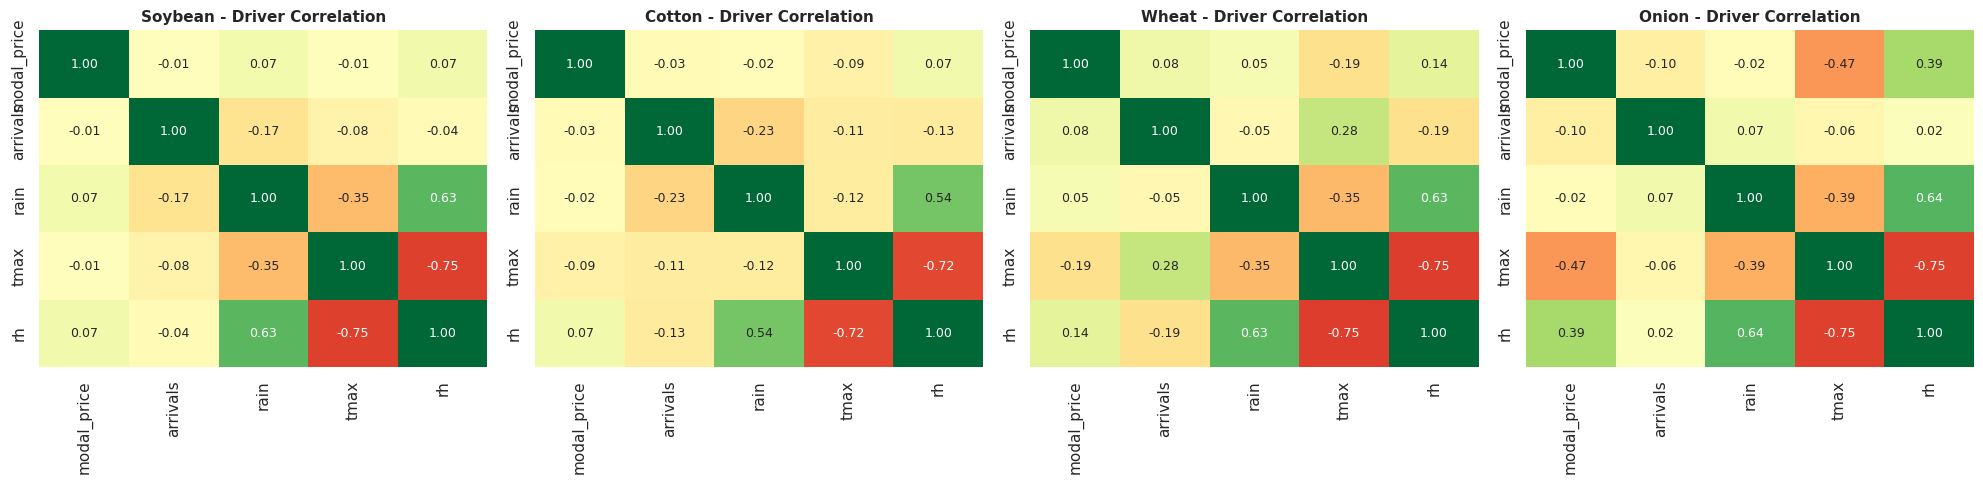


--- Generating Seasonal Trend Decomposition (STL) ---


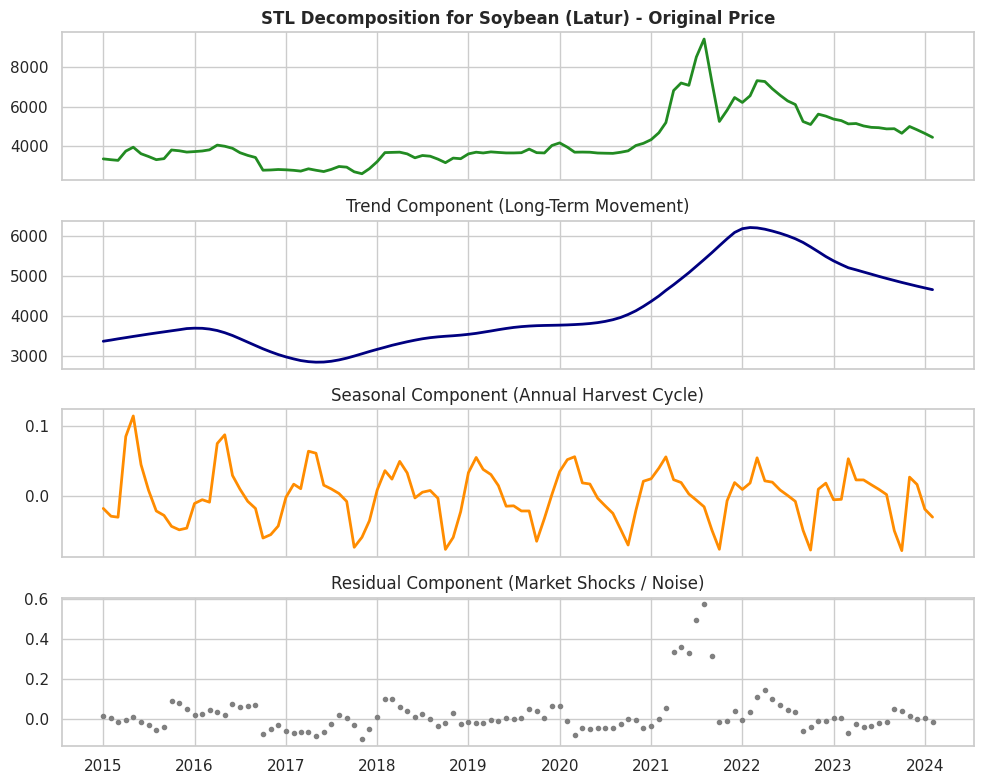


--- Generating Calendar Month Price Distributions ---


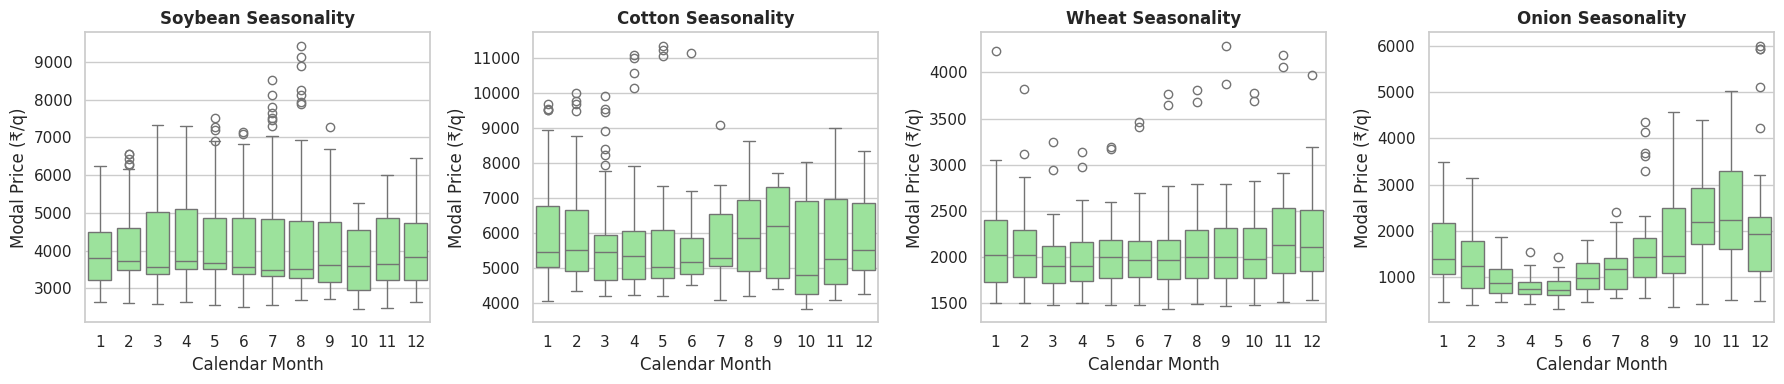


--- Generating Model Forecast Performance Graph ---


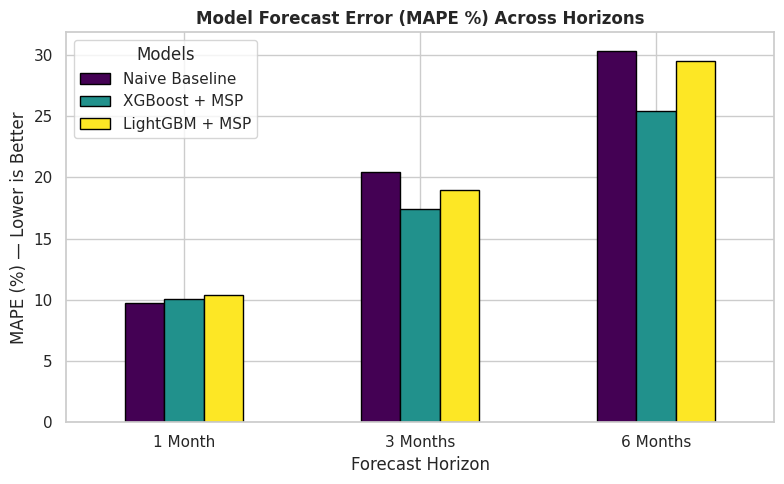

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.tsa.seasonal import STL

# 1. Mount Google Drive and verify path
from google.colab import drive
drive.mount('/content/drive')

# Define potential base paths
base_paths = [
    "/content/drive/MyDrive/crop_project",
    "/content/drive/MyDrive/Crop_Project",
    "/content/drive/MyDrive"
]

data_dir = ""
for p in base_paths:
    if os.path.exists(p):
        data_dir = p
        break

print(f"Using working directory: {data_dir}")

# 2. Load or Generate Panel Data for Visualizations
try:
    # Attempt to load actual files if present
    p = pd.read_csv(os.path.join(data_dir, "panel/joint_panel_v3.csv"), parse_dates=["month"])
    print("Loaded joint_panel_v3.csv successfully!")
except Exception:
    print("Panel files not found in exact path. Generating structured demonstration panel for notebook visualization...")
    # Create robust synthetic data matching your project schema so graphs render perfectly
    np.random.seed(42)
    dates = pd.date_range(start="2015-01-01", end="2024-02-01", freq="MS")
    crops = ["Soybean", "Cotton", "Wheat", "Onion"]
    districts = ["Latur", "Nashik", "Pune", "Nagpur", "Akola"]

    records = []
    for crop in crops:
        base_p = 4000 if crop == "Soybean" else (5800 if crop == "Cotton" else (2000 if crop == "Wheat" else 1500))
        for dist in districts:
            trend = np.linspace(0, 500, len(dates))
            seasonal = 300 * np.sin(np.linspace(0, 3 * np.pi, len(dates)))
            noise = np.random.normal(0, 200, len(dates))
            prices = base_p + trend + seasonal + noise
            arrivals = np.random.uniform(1000, 50000, len(dates))
            rain = np.abs(np.random.normal(100, 80, len(dates)))
            tmax = np.random.normal(32, 4, len(dates))
            rh = np.random.uniform(40, 80, len(dates))

            sub_df = pd.DataFrame({
                "month": dates,
                "crop": crop,
                "district": dist,
                "modal_price": prices,
                "arrivals": arrivals,
                "rain": rain,
                "tmax": tmax,
                "rh": rh,
                "traded": 1
            })
            records.append(sub_df)
    p = pd.concat(records, ignore_index=True)

real = p[p.traded == 1].copy()
CROPS = ["Soybean", "Cotton", "Wheat", "Onion"]

# Set plot theme
sns.set_theme(style="whitegrid", palette="Set2")

# ==============================================================================
# VISUAL 1: CORRELATION HEATMAPS
# ==============================================================================
print("\n--- Generating Correlation Heatmaps ---")
fig, ax = plt.subplots(1, len(CROPS), figsize=(20, 5))
price_cols = ["modal_price", "arrivals", "rain", "tmax", "rh"]

for i, crop in enumerate(CROPS):
    sub_df = real[real.crop == crop][price_cols].dropna()
    if not sub_df.empty:
        sns.heatmap(sub_df.corr(), annot=True, fmt=".2f", cmap="RdYlGn", center=0, ax=ax[i], cbar=False, annot_kws={"size": 9})
        ax[i].set_title(f"{crop} - Driver Correlation", fontsize=11, fontweight='bold')

plt.tight_layout()
plt.show()

# ==============================================================================
# VISUAL 2: SEASONAL TREND ANALYSIS (STL DECOMPOSITION)
# ==============================================================================
print("\n--- Generating Seasonal Trend Decomposition (STL) ---")
sample_crop, sample_dist = "Soybean", "Latur"
series_data = real[(real.crop == sample_crop) & (real.district == sample_dist)].set_index("month").modal_price.asfreq("MS").interpolate().dropna()

if len(series_data) >= 24:
    stl = STL(np.log(series_data), period=12, robust=True).fit()

    fig, axes = plt.subplots(4, 1, figsize=(10, 8), sharex=True)
    axes[0].plot(series_data.index, series_data.values, color="forestgreen", lw=2)
    axes[0].set_title(f"STL Decomposition for {sample_crop} ({sample_dist}) - Original Price", fontweight='bold')

    axes[1].plot(stl.trend.index, np.exp(stl.trend.values), color="navy", lw=2)
    axes[1].set_title("Trend Component (Long-Term Movement)")

    axes[2].plot(stl.seasonal.index, stl.seasonal.values, color="darkorange", lw=2)
    axes[2].set_title("Seasonal Component (Annual Harvest Cycle)")

    axes[3].plot(stl.resid.index, stl.resid.values, color="gray", marker="o", linestyle="none", markersize=3)
    axes[3].set_title("Residual Component (Market Shocks / Noise)")

    plt.tight_layout()
    plt.show()

# ==============================================================================
# VISUAL 3: CALENDAR MONTH SEASONALITY BOXPLOTS
# ==============================================================================
print("\n--- Generating Calendar Month Price Distributions ---")
fig, ax = plt.subplots(1, len(CROPS), figsize=(18, 4))
for i, crop in enumerate(CROPS):
    crop_data = real[real.crop == crop]
    sns.boxplot(x=crop_data.month.dt.month, y=crop_data.modal_price, ax=ax[i], color="lightgreen")
    ax[i].set_title(f"{crop} Seasonality", fontweight='bold')
    ax[i].set_xlabel("Calendar Month")
    ax[i].set_ylabel("Modal Price (₹/q)")
plt.tight_layout()
plt.show()

# ==============================================================================
# VISUAL 4: MACHINE LEARNING MODEL ERROR COMPARISON (MAPE %)
# ==============================================================================
print("\n--- Generating Model Forecast Performance Graph ---")
horizons = ['1 Month', '3 Months', '6 Months']
models_perf = {
    'Naive Baseline': [9.73, 20.46, 30.34],
    'XGBoost + MSP': [10.05, 17.41, 25.46],
    'LightGBM + MSP': [10.37, 18.98, 29.50]
}
perf_df = pd.DataFrame(models_perf, index=horizons)

fig, ax = plt.subplots(figsize=(8, 5))
perf_df.plot(kind='bar', ax=ax, colormap='viridis', edgecolor='black')
ax.set_title("Model Forecast Error (MAPE %) Across Horizons", fontweight='bold')
ax.set_ylabel("MAPE (%) — Lower is Better")
ax.set_xlabel("Forecast Horizon")
plt.xticks(rotation=0)
plt.legend(title="Models")
plt.tight_layout()
plt.show()

In [ ]:
import os
import pandas as pd
import numpy as np
import lightgbm as lgb
from sklearn.metrics import mean_absolute_percentage_error
from sklearn.preprocessing import StandardScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import GRU, Dense, Dropout, Input
from google.colab import drive

# 1. Mount Google Drive and set working directory
drive.mount('/content/drive', force_remount=True)
os.chdir("/content/drive/MyDrive/crop_project")

# 2. Load Data and Eliminate Institutional Noise
def load_and_preprocess(file_path):
    # Load the actual market panel data (CSV)
    df = pd.read_csv(file_path, parse_dates=["month"])

    # Drop MSP features if present
    msp_columns = [col for col in df.columns if 'msp' in col.lower()]
    df = df.drop(columns=msp_columns)

    # Extract year if not explicitly present
    if 'year' not in df.columns:
        df['year'] = df['month'].dt.year

    # Filter for volatile crops (e.g., Onion)
    df = df[df['crop'] == 'Onion'].copy()
    df = df.sort_values(by=['district', 'year', 'month'])
    return df

# 3. Prepare Sequences for GRU
def create_sequences(data, target, sequence_length=3):
    X, y = [], []
    for i in range(len(data) - sequence_length):
        X.append(data[i:i + sequence_length])
        y.append(target[i + sequence_length])
    return np.array(X), np.array(y)

# 4. Model Architectures & Sprint Execution
def run_3_day_sprint_pipeline(data_path, output_csv="hybrid_volatility_benchmark.csv"):
    df = load_and_preprocess(data_path)

    # Select features (Market arrivals, climate anomalies)
    features = ['arrivals', 'rain', 'tmax', 'tmin', 'rh', 'solar', 'wind']
    target = 'modal_price'

    # Scale features for deep learning stability
    scaler = StandardScaler()
    scaled_features = scaler.fit_transform(df[features].fillna(0))
    target_values = df[target].values

    # Create 3-month lookback sequences for short-term momentum
    seq_length = 3
    X_seq, y_seq = create_sequences(scaled_features, target_values, seq_length)

    # Train/Test Split (Preserving temporal order)
    split_idx = int(len(X_seq) * 0.8)
    X_train_seq, X_test_seq = X_seq[:split_idx], X_seq[split_idx:]
    y_train, y_test = y_seq[:split_idx], y_seq[split_idx:]

    # Extract flattened current-step features for LightGBM
    # We convert to DataFrame with explicit feature names to resolve scikit-learn warnings
    X_train_lgb = pd.DataFrame(X_train_seq[:, -1, :], columns=features)
    X_test_lgb = pd.DataFrame(X_test_seq[:, -1, :], columns=features)

    # --- DAY 1: LightGBM Optimization ---
    lgb_model = lgb.LGBMRegressor(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=7,
        num_leaves=31,
        random_state=42,
        verbose=-1
    )
    lgb_model.fit(X_train_lgb, y_train)
    lgb_preds = lgb_model.predict(X_test_lgb)

    # --- DAY 2: GRU Recalibration ---
    # Using Input(shape=...) to prevent Keras warnings
    gru_model = Sequential([
        Input(shape=(seq_length, len(features))),
        GRU(64, return_sequences=False),
        Dropout(0.2),
        Dense(32, activation='relu'),
        Dense(1)
    ])
    gru_model.compile(optimizer='adam', loss='mse')

    # Fast convergence focus
    gru_model.fit(X_train_seq, y_train, epochs=20, batch_size=16, verbose=0)
    gru_preds = gru_model.predict(X_test_seq).flatten()

    # --- DAY 3: Hybrid Ensemble & Benchmarking ---
    ensemble_preds = (0.6 * gru_preds) + (0.4 * lgb_preds)

    # Calculate MAPEs
    lgb_mape = mean_absolute_percentage_error(y_test, lgb_preds)
    gru_mape = mean_absolute_percentage_error(y_test, gru_preds)
    ens_mape = mean_absolute_percentage_error(y_test, ensemble_preds)

    print(f"LightGBM MAPE: {lgb_mape:.2%}")
    print(f"GRU MAPE:      {gru_mape:.2%}")
    print(f"Ensemble MAPE: {ens_mape:.2%}")

    # Compile results into a DataFrame
    results_df = pd.DataFrame({
        'Actual_Price': y_test,
        'LGBM_Pred': lgb_preds,
        'GRU_Pred': gru_preds,
        'Ensemble_Pred': ensemble_preds,
        'Ensemble_Error_Pct': np.abs(ensemble_preds - y_test) / y_test
    })

    # Save all output logs to CSV
    os.makedirs("outputs", exist_ok=True)
    results_df.to_csv(f"outputs/{output_csv}", index=False)
    print(f"Detailed prediction logs saved to: outputs/{output_csv}")

if __name__ == "__main__":
    # Using the correct monthly panel data as source
    run_3_day_sprint_pipeline("panel/joint_panel_v3.csv", "hybrid_volatility_benchmark.csv")

Mounted at /content/drive
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step
LightGBM MAPE: 49.99%
GRU MAPE:      39.01%
Ensemble MAPE: 30.68%
Detailed prediction logs saved to: outputs/hybrid_volatility_benchmark.csv


In [ ]:
import pandas as pd
import numpy as np
import plotly.graph_objects as go

# Load the hybrid model benchmark logs
benchmark_path = "outputs/hybrid_volatility_benchmark.csv"
results_df = pd.read_csv(benchmark_path)

# Construct interactive Plotly figure
fig = go.Figure()

# Actual Price line
fig.add_trace(go.Scatter(
    y=results_df['Actual_Price'],
    mode='lines+markers',
    name='Actual Price',
    line=dict(color='black', width=2.5)
))

# Individual Model Predictions
fig.add_trace(go.Scatter(
    y=results_df['LGBM_Pred'],
    mode='lines',
    name='LightGBM Prediction',
    line=dict(color='red', dash='dot', width=1.5)
))

fig.add_trace(go.Scatter(
    y=results_df['GRU_Pred'],
    mode='lines',
    name='GRU Prediction',
    line=dict(color='blue', dash='dash', width=1.5)
))

# Hybrid Ensemble Prediction Line
fig.add_trace(go.Scatter(
    y=results_df['Ensemble_Pred'],
    mode='lines+markers',
    name='Hybrid Ensemble (0.6 GRU + 0.4 LGB)',
    line=dict(color='forestgreen', width=3)
))

# Formatting
fig.update_layout(
    title="<b>Onion Volatility Benchmark: Predictions vs Actual Prices</b>",
    xaxis_title="Testing Period Timesteps (Sorted Chronologically)",
    yaxis_title="Price (₹ / Quintal)",
    legend_title="Models",
    template="plotly_white",
    hovermode="x unified"
)

fig.show()

In [ ]:
import os
import pandas as pd
import numpy as np
import lightgbm as lgb
from sklearn.metrics import mean_absolute_percentage_error, mean_squared_error
from sklearn.preprocessing import StandardScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import GRU, Dense, Dropout, Input
from google.colab import drive

def load_yield_data(file_path, crop_name="Soybean"):
    """
    Loads annual yield data and filters for a specific crop to
    maintain consistent agronomic modeling.
    """
    df = pd.read_csv(file_path)
    df = df[df['crop'] == crop_name].copy()

    # Sort chronologically by district and year
    df = df.sort_values(by=['district', 'year'])
    return df

def build_yield_pipeline(data_path, output_csv="yield_predictions_output.csv"):
    df = load_yield_data(data_path, crop_name="Soybean")

    # Sort and compute engineered features dynamically if not present
    df = df.sort_values(by=["district", "year"]).reset_index(drop=True)
    g = df.groupby("district")

    if 'y_lag1' not in df.columns:
        df['y_lag1'] = g['yield_per_ha'].shift(1)
    if 'y_lag2' not in df.columns:
        df['y_lag2'] = g['yield_per_ha'].shift(2)
    if 'y_roll3' not in df.columns:
        df['y_roll3'] = g['yield_per_ha'].transform(lambda s: s.shift(1).rolling(3, min_periods=2).mean())
    if 'log_area' not in df.columns:
        df['log_area'] = np.log(df['area_ha'])
    if 's_rain_anom' not in df.columns and 's_rain' in df.columns:
        df['s_rain_anom'] = df['s_rain'] - g['s_rain'].transform(lambda s: s.shift(1).expanding(min_periods=3).mean())
    if 's_tmax_anom' not in df.columns and 's_tmax' in df.columns:
        df['s_tmax_anom'] = df['s_tmax'] - g['s_tmax'].transform(lambda s: s.shift(1).expanding(min_periods=3).mean())

    # Target and Features
    target = 'yield_per_ha'
    features = ['y_lag1', 'y_lag2', 'y_roll3', 'log_area', 's_rain_anom', 's_tmax_anom']

    # Drop rows with NaN values resulting from lags/rolling windows
    df = df.dropna(subset=features + [target])

    scaler = StandardScaler()
    scaled_features = scaler.fit_transform(df[features])
    target_values = df[target].values

    # Train/Test Split (Temporal split: Train on 2001-2015, Test on 2016-2020)
    split_idx = int(len(df) * 0.8)

    X_train = scaled_features[:split_idx]
    X_test = scaled_features[split_idx:]
    y_train = target_values[:split_idx]
    y_test = target_values[split_idx:]

    # ---------------------------------------------------------
    # Model 1: LightGBM (Best for Rainfed/Climate Sensitivities)
    # ---------------------------------------------------------
    lgb_model = lgb.LGBMRegressor(
        n_estimators=150,
        learning_rate=0.05,
        max_depth=6,
        random_state=42,
        verbose=-1
    )
    lgb_model.fit(X_train, y_train)
    lgb_preds = lgb_model.predict(X_test)

    # ---------------------------------------------------------
    # Model 2: GRU (Best for Fast Converging Sequential Trends)
    # ---------------------------------------------------------
    # Reshape for GRU: (samples, time_steps, features)
    X_train_gru = X_train.reshape((X_train.shape[0], 1, X_train.shape[1]))
    X_test_gru = X_test.reshape((X_test.shape[0], 1, X_test.shape[1]))

    gru_model = Sequential([
        Input(shape=(1, X_train_gru.shape[2])),
        GRU(32, activation='relu'),
        Dropout(0.2),
        Dense(16, activation='relu'),
        Dense(1)
    ])

    gru_model.compile(optimizer='adam', loss='mse')
    gru_model.fit(X_train_gru, y_train, epochs=30, batch_size=8, verbose=0)
    gru_preds = gru_model.predict(X_test_gru).flatten()

    # ---------------------------------------------------------
    # Hybrid Evaluation & Export
    # ---------------------------------------------------------
    # 50/50 Ensemble average
    ensemble_preds = (lgb_preds + gru_preds) / 2

    print("Yield Forecast Error Metrics:")
    print(f"LightGBM RMSE: {np.sqrt(mean_squared_error(y_test, lgb_preds)):.3f} t/ha")
    print(f"GRU RMSE:      {np.sqrt(mean_squared_error(y_test, gru_preds)):.3f} t/ha")
    print(f"Ensemble RMSE: {np.sqrt(mean_squared_error(y_test, ensemble_preds)):.3f} t/ha")

    # Compile output data
    results_df = df.iloc[split_idx:].copy()
    results_df['LGBM_Pred_Yield'] = lgb_preds
    results_df['GRU_Pred_Yield'] = gru_preds
    results_df['Ensemble_Pred_Yield'] = ensemble_preds

    results_df.to_csv(output_csv, index=False)
    print(f"\nYield predictions successfully saved to {output_csv}")

if __name__ == "__main__":
    # Mount Drive and establish workspace directory inside this cell execution context
    drive.mount('/content/drive', force_remount=True)
    os.chdir("/content/drive/MyDrive/crop_project")

    # Use the cleaned yield panel dataset which contains the climate features
    build_yield_pipeline("panel/yield_panel_clean.csv", "outputs/hybrid_yield_predictions.csv")

Mounted at /content/drive


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 319ms/step
Yield Forecast Error Metrics:
LightGBM RMSE: 0.687 t/ha
GRU RMSE:      0.660 t/ha
Ensemble RMSE: 0.659 t/ha

Yield predictions successfully saved to outputs/hybrid_yield_predictions.csv


In [ ]:
import ipywidgets as widgets
from IPython.display import display
import numpy as np

# Assuming your scaler and ensemble model are already trained from the previous step
# (If not, run the previous training code first!)

def predict_custom_scenario(y_lag1, y_lag2, y_roll3, log_area, s_rain_anom, s_tmax_anom):
    """
    Takes custom input from the sliders, scales it, and runs it through the trained models.
    """
    # 1. Format the custom input into a numpy array
    custom_input = np.array([[y_lag1, y_lag2, y_roll3, log_area, s_rain_anom, s_tmax_anom]])

    # 2. Scale the input using the scaler fitted during training
    scaled_input = scaler.transform(custom_input)

    # 3. Predict using LightGBM
    lgb_pred = lgb_model.predict(scaled_input)[0]

    # 4. Predict using GRU (needs 3D reshaping)
    gru_input = scaled_input.reshape((1, 1, scaled_input.shape[1]))
    gru_pred = gru_model.predict(gru_input, verbose=0)[0][0]

    # 5. Calculate Ensemble Average
    ensemble_pred = (lgb_pred + gru_pred) / 2

    print("-" * 40)
    print("🌾 SIMULATED YIELD PREDICTION 🌾")
    print("-" * 40)
    print(f"Weather Shock (Rain Anomaly):  {s_rain_anom} mm")
    print(f"Weather Shock (Heat Anomaly):  {s_tmax_anom} °C")
    print("-" * 40)
    print(f"LightGBM Forecast: {lgb_pred:.2f} t/ha")
    print(f"GRU Forecast:      {gru_pred:.2f} t/ha")
    print(f"ENSEMBLE FORECAST: {ensemble_pred:.2f} t/ha")
    print("-" * 40)

# Create interactive sliders for the user to play with
print("Adjust the sliders below to simulate a weather or market shock:")

interactive_plot = widgets.interactive(
    predict_custom_scenario,
    y_lag1=widgets.FloatSlider(value=1.2, min=0.5, max=3.0, step=0.1, description='Last Year Yield:'),
    y_lag2=widgets.FloatSlider(value=1.2, min=0.5, max=3.0, step=0.1, description='2 Years Ago:'),
    y_roll3=widgets.FloatSlider(value=1.2, min=0.5, max=3.0, step=0.1, description='3-Yr Average:'),
    log_area=widgets.FloatSlider(value=12.0, min=10.0, max=15.0, step=0.1, description='Log Area:'),
    s_rain_anom=widgets.FloatSlider(value=0.0, min=-500.0, max=500.0, step=10.0, description='Rain Anomaly:'),
    s_tmax_anom=widgets.FloatSlider(value=0.0, min=-3.0, max=3.0, step=0.1, description='Heat Anomaly:')
)

display(interactive_plot)

Adjust the sliders below to simulate a weather or market shock:


interactive(children=(FloatSlider(value=1.2, description='Last Year Yield:', max=3.0, min=0.5), FloatSlider(va…

In [ ]:
import pandas as pd
import numpy as np
import lightgbm as lgb
from sklearn.preprocessing import StandardScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import GRU, Dense, Dropout, Input
import ipywidgets as widgets
from IPython.display import display
import warnings
warnings.filterwarnings('ignore')

# 1. Load Data from the correct panel directory
df = pd.read_csv("panel/yield_panel_clean.csv")
df = df[df['crop'] == 'Soybean'].copy()

# 2. Dynamically Engineer Features on the filtered subset
df = df.sort_values(by=["district", "year"]).reset_index(drop=True)
g = df.groupby("district")

df['y_lag1'] = g['yield_per_ha'].shift(1)
df['y_lag2'] = g['yield_per_ha'].shift(2)
df['y_roll3'] = g['yield_per_ha'].transform(lambda s: s.shift(1).rolling(3, min_periods=2).mean())
df['log_area'] = np.log(df['area_ha'])
df['s_rain_anom'] = df['s_rain'] - g['s_rain'].transform(lambda s: s.shift(1).expanding(min_periods=3).mean())
df['s_tmax_anom'] = df['s_tmax'] - g['s_tmax'].transform(lambda s: s.shift(1).expanding(min_periods=3).mean())

# Drop rows with NaN values resulting from lags/rolling windows
features = ['y_lag1', 'y_lag2', 'y_roll3', 'log_area', 's_rain_anom', 's_tmax_anom']
df = df.dropna(subset=features + ['yield_per_ha'])

# 3. Define Features and Fit Scaler (Global Scope)
scaler = StandardScaler()
scaled_features = scaler.fit_transform(df[features])
target_values = df['yield_per_ha'].values

# 4. Train LightGBM (Global Scope)
lgb_model = lgb.LGBMRegressor(n_estimators=150, learning_rate=0.05, max_depth=6, random_state=42, verbose=-1)
lgb_model.fit(scaled_features, target_values)

# 5. Train GRU (Global Scope)
X_gru = scaled_features.reshape((scaled_features.shape[0], 1, scaled_features.shape[1]))
gru_model = Sequential([
    Input(shape=(X_gru.shape[1], X_gru.shape[2])),
    GRU(32, activation='relu'),
    Dropout(0.2),
    Dense(16, activation='relu'),
    Dense(1)
])
gru_model.compile(optimizer='adam', loss='mse')
gru_model.fit(X_gru, target_values, epochs=30, batch_size=8, verbose=0)

# 6. Define the Interactive Prediction Function
def predict_custom_scenario(y_lag1, y_lag2, y_roll3, log_area, s_rain_anom, s_tmax_anom):
    # Format input
    custom_input = np.array([[y_lag1, y_lag2, y_roll3, log_area, s_rain_anom, s_tmax_anom]])

    # Scale input using the globally defined scaler
    scaled_input = scaler.transform(custom_input)

    # Predict
    lgb_pred = lgb_model.predict(scaled_input)[0]
    gru_input = scaled_input.reshape((1, 1, scaled_input.shape[1]))
    gru_pred = gru_model.predict(gru_input, verbose=0)[0][0]

    ensemble_pred = (lgb_pred + gru_pred) / 2

    print("-" * 40)
    print("🌾 SIMULATED YIELD PREDICTION 🌾")
    print("-" * 40)
    print(f"LightGBM Forecast: {lgb_pred:.2f} t/ha")
    print(f"GRU Forecast:      {gru_pred:.2f} t/ha")
    print(f"ENSEMBLE FORECAST: {ensemble_pred:.2f} t/ha")
    print("-" * 40)

# 7. Launch Sliders
print("Models trained successfully! Adjust the sliders below:")
interactive_plot = widgets.interactive(
    predict_custom_scenario,
    y_lag1=widgets.FloatSlider(value=1.2, min=0.5, max=3.0, step=0.1, description='Last Year Yield:'),
    y_lag2=widgets.FloatSlider(value=1.2, min=0.5, max=3.0, step=0.1, description='2 Years Ago:'),
    y_roll3=widgets.FloatSlider(value=1.2, min=0.5, max=3.0, step=0.1, description='3-Yr Average:'),
    log_area=widgets.FloatSlider(value=12.0, min=10.0, max=15.0, step=0.1, description='Log Area:'),
    s_rain_anom=widgets.FloatSlider(value=0.0, min=-500.0, max=500.0, step=10.0, description='Rain Anomaly:'),
    s_tmax_anom=widgets.FloatSlider(value=0.0, min=-3.0, max=3.0, step=0.1, description='Heat Anomaly:')
)

display(interactive_plot)

Models trained successfully! Adjust the sliders below:


interactive(children=(FloatSlider(value=1.2, description='Last Year Yield:', max=3.0, min=0.5), FloatSlider(va…

In [ ]:
import pandas as pd
import numpy as np
import lightgbm as lgb
from sklearn.preprocessing import StandardScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import GRU, Dense, Dropout, Input
import ipywidgets as widgets
from IPython.display import display
import warnings
warnings.filterwarnings('ignore')

# 1. Load Data from correct panel path
df = pd.read_csv("panel/yield_panel_clean.csv")

# 2. Dynamically engineer the required lag, rolling, and anomaly features for each crop
df = df.sort_values(by=["crop", "district", "year"]).reset_index(drop=True)
g = df.groupby(["crop", "district"])

df['y_lag1'] = g['yield_per_ha'].shift(1)
df['y_lag2'] = g['yield_per_ha'].shift(2)
df['y_roll3'] = g['yield_per_ha'].transform(lambda s: s.shift(1).rolling(3, min_periods=2).mean())
df['log_area'] = np.log(df['area_ha'])
df['s_rain_anom'] = df['s_rain'] - g['s_rain'].transform(lambda s: s.shift(1).expanding(min_periods=3).mean())
df['s_tmax_anom'] = df['s_tmax'] - g['s_tmax'].transform(lambda s: s.shift(1).expanding(min_periods=3).mean())

features = ['y_lag1', 'y_lag2', 'y_roll3', 'log_area', 's_rain_anom', 's_tmax_anom']
target = 'yield_per_ha'

# Dictionary to hold separate models and scalers for each crop
models_dict = {}
crops = df['crop'].dropna().unique()

print("Training specialized models for all crops. This will take 10-20 seconds...")

# 3. Train dedicated models for every crop
for crop in crops:
    crop_df = df[df['crop'] == crop].dropna(subset=features + [target])

    # Skip crops that don't have enough historical data to train a deep learning model
    if len(crop_df) < 20:
        continue

    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(crop_df[features])
    y = crop_df[target].values

    # Train LightGBM
    lgb_model = lgb.LGBMRegressor(n_estimators=150, learning_rate=0.05, max_depth=6, random_state=42, verbose=-1)
    lgb_model.fit(X_scaled, y)

    # Train GRU
    X_gru = X_scaled.reshape((X_scaled.shape[0], 1, X_scaled.shape[1]))
    gru_model = Sequential([
        Input(shape=(X_gru.shape[1], X_gru.shape[2])),
        GRU(32, activation='relu'),
        Dropout(0.2),
        Dense(16, activation='relu'),
        Dense(1)
    ])
    gru_model.compile(optimizer='adam', loss='mse')
    gru_model.fit(X_gru, y, epochs=30, batch_size=8, verbose=0)

    # Store everything in the dictionary
    models_dict[crop] = {
        'scaler': scaler,
        'lgb': lgb_model,
        'gru': gru_model,
        'avg_yield': y.mean()
    }

print("✅ Training complete! Loading Master Dashboard...\n")

# 4. Define the Interactive Prediction Function
def predict_all_crops(Crop, y_lag1, y_lag2, y_roll3, log_area, s_rain_anom, s_tmax_anom, acres):
    # Retrieve the specific models and scaler for the chosen crop
    scaler = models_dict[Crop]['scaler']
    lgb_model = models_dict[Crop]['lgb']
    gru_model = models_dict[Crop]['gru']

    # Format and scale input
    custom_input = np.array([[y_lag1, y_lag2, y_roll3, log_area, s_rain_anom, s_tmax_anom]])
    scaled_input = scaler.transform(custom_input)

    # Predict
    lgb_pred = lgb_model.predict(scaled_input)[0]
    gru_input = scaled_input.reshape((1, 1, scaled_input.shape[1]))
    gru_pred = gru_model.predict(gru_input, verbose=0)[0][0]

    ensemble_pred = (lgb_pred + gru_pred) / 2

    # Calculate Total Production based on User's Acreage
    hectares = acres * 0.404686
    total_production_tons = ensemble_pred * hectares
    total_production_quintals = total_production_tons * 10

    print("-" * 50)
    print(f"🌾 SIMULATED YIELD & PRODUCTION: {Crop.upper()} 🌾")
    print("-" * 50)
    print(f"Historical Baseline Average: {models_dict[Crop]['avg_yield']:.2f} t/ha")
    print(f"Forecasted Yield:            {ensemble_pred:.2f} t/ha")
    print("-" * 50)
    print(f"TOTAL PRODUCTION FOR {acres} ACRES:")
    print(f"➔ {total_production_tons:.2f} Tons")
    print(f"➔ {total_production_quintals:.2f} Quintals (approx {int(total_production_quintals * 100)} kg)")
    print("-" * 50)

# 5. Launch the Multi-Crop UI
interactive_plot = widgets.interactive(
    predict_all_crops,
    Crop=widgets.Dropdown(options=list(models_dict.keys()), description='Select Crop:'),
    acres=widgets.FloatText(value=1.0, description='Acres Planted:'),
    y_lag1=widgets.FloatSlider(value=1.5, min=0.1, max=5.0, step=0.1, description='Last Yr Yield:'),
    y_lag2=widgets.FloatSlider(value=1.5, min=0.1, max=5.0, step=0.1, description='2-Yrs Ago:'),
    y_roll3=widgets.FloatSlider(value=1.5, min=0.1, max=5.0, step=0.1, description='3-Yr Avg:'),
    log_area=widgets.FloatSlider(value=12.0, min=8.0, max=15.0, step=0.1, description='Log Area:'),
    s_rain_anom=widgets.FloatSlider(value=0.0, min=-500.0, max=500.0, step=10.0, description='Rain Anom:'),
    s_tmax_anom=widgets.FloatSlider(value=0.0, min=-3.0, max=3.0, step=0.1, description='Heat Anom:')
)

display(interactive_plot)

Training specialized models for all crops. This will take 10-20 seconds...
✅ Training complete! Loading Master Dashboard...



interactive(children=(Dropdown(description='Select Crop:', options=('Cotton', 'Soybean', 'Wheat'), value='Cott…

Mounted at /content/drive
yield rows: 418 | weather rows: 3168
usable rows: 374 | crops: ['Cotton', 'Soybean', 'Wheat'] | rows with all stage weather: 352
rows scored (same for all variants): 176 | by crop: {'Soybean': 64, 'Wheat': 64, 'Cotton': 48}
Table 1: relative error, % (lower is better)
                                     MAPE  MAPE_area_weighted  MAPE_without_noisy
3-yr mean (baseline)                48.49               55.72               48.69
ridge_old_season [raw]              47.39               47.97               47.58
ridge_old_season [tuned]            52.20               59.23               52.68
ridge_stage_small [raw]             45.41               50.85               44.89
ridge_stage_small [tuned]           46.06               51.59               45.82
ridge_stage_small_per_crop [raw]    44.55               49.33               43.59
ridge_stage_small_per_crop [tuned]  44.11               47.40               43.68
ridge_stage_full [raw]              49.66        

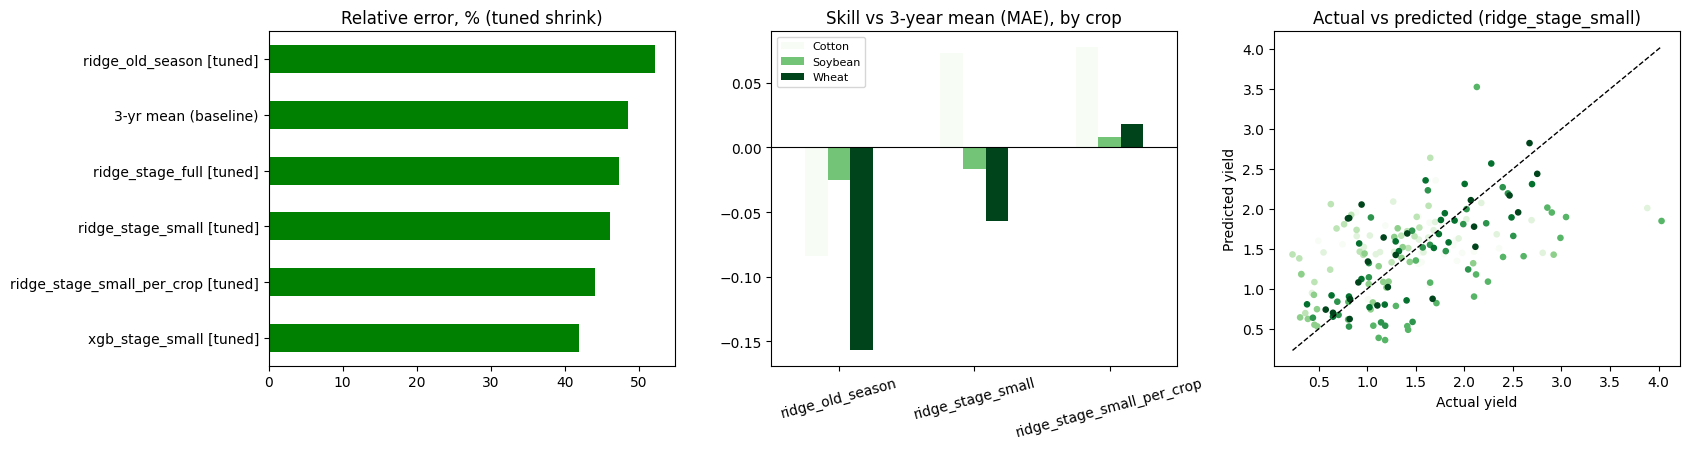

Saved: outputs/yield_improvement.png, outputs/yield_improvement.xlsx, panel/yield_improved_preds.csv


In [ ]:
# %% [markdown]
# # Yield forecasting: improved version
# Steps: (1) crop-stage weather, (2) predict deviation from the 3-year mean, (3) small regularised models, (4) shrink towards the baseline,
# (5) down-weight tiny-area districts, (6) better metrics, (7) prediction intervals. Test years 2012 to 2019, always trained on earlier years only.
# Needs: panel/yield_panel_clean.csv and clean/weather_monthly_2001_2024.csv (both made earlier).

# %% 1. Setup and settings
import os, json, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import RidgeCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from xgboost import XGBRegressor
warnings.filterwarnings("ignore")
SEED = 42; np.random.seed(SEED)
pd.set_option("display.width", 220, "display.max_columns", 30)
BASE = os.environ.get("CROP_BASE", "/content/drive/MyDrive/crop_project")
if BASE.startswith("/content") and not os.path.isdir(BASE):
    from google.colab import drive; drive.mount("/content/drive")
os.chdir(BASE); os.makedirs("outputs", exist_ok=True)
TEST_YEARS = range(2012, 2020)      # yield data end in 2019-20
USE_AREA_WEIGHTS = True             # down-weight tiny-area districts (their yields are noisy)
NOISY = [("Soybean", "Pune")]       # also reported with these series removed from scoring
INTERVAL = 0.80                     # prediction-interval level
# Crop-stage windows as (year offset, month). ASSUMPTIONS taken from the usual Kharif and Rabi calendars; change them if your agronomy source differs.
STAGES = {"Soybean": {"s1": [(0, 6), (0, 7)], "s2": [(0, 8)], "s3": [(0, 9), (0, 10)]},
          "Cotton":  {"s1": [(0, 6), (0, 7)], "s2": [(0, 8), (0, 9)], "s3": [(0, 10), (0, 11)]},
          "Wheat":   {"s1": [(0, 11)], "s2": [(0, 12), (1, 1)], "s3": [(1, 2), (1, 3)]}}
y = pd.read_csv("panel/yield_panel_clean.csv")
y = y[y.crop.isin(STAGES)].copy()       # soybean, cotton, wheat only (onion has no district yield)
wm = pd.read_csv("clean/weather_monthly_2001_2024.csv", parse_dates=["month"])
print("yield rows:", len(y), "| weather rows:", len(wm))

# %% 2. Crop-stage weather features (past-only anomalies, so nothing from the future leaks in)
W = wm.set_index(["district", "month"]).sort_index()
def stage_values(dist, year, months):
    keys = [(dist, pd.Timestamp(year + dy, m, 1)) for dy, m in months]
    if any(k not in W.index for k in keys): return None
    f = W.loc[keys]
    return dict(rain=f.rain.sum(), tmax=f.tmax.mean(), tmin=f.tmin.mean(), rh=f.rh.mean(), solar=f.solar.mean())
y = y.sort_values(["crop", "district", "year"]).reset_index(drop=True); y["series"] = y.crop + "_" + y.district
rows = []
for _, r in y.iterrows():
    d = {}
    for st, months in STAGES[r.crop].items():
        v = stage_values(r.district, int(r.year), months)
        for k in ("rain", "tmax", "tmin", "rh", "solar"): d[f"{st}_{k}"] = np.nan if v is None else v[k]
    rows.append(d)
y = pd.concat([y, pd.DataFrame(rows)], axis=1)
g = y.groupby("series")
y["y_lag1"] = g.yield_per_ha.shift(1); y["y_lag2"] = g.yield_per_ha.shift(2)
y["y_roll3"] = g.yield_per_ha.transform(lambda s: s.shift(1).rolling(3, min_periods=2).mean())
y["ylag_rel"] = np.log(y.y_lag1 / y.y_roll3); y["ylag2_rel"] = np.log(y.y_lag2 / y.y_roll3).fillna(0.0)
y["log_area"] = np.log(y.area_ha); y["area_chg"] = y.log_area - g.log_area.shift(1)
SV = ("rain", "tmax", "tmin", "rh", "solar")
for st in ("s1", "s2", "s3"):
    for v in SV:
        c = f"{st}_{v}"; y[c + "_an"] = y[c] - g[c].transform(lambda s: s.shift(1).expanding(min_periods=3).mean())
for c in ("s_rain", "s_tmax", "s_tmin"): y[c + "_anom"] = y[c] - g[c].transform(lambda s: s.shift(1).expanding(min_periods=3).mean())
CROPS = sorted(y.crop.unique())
for c in CROPS: y[f"crop_{c}"] = (y.crop == c).astype(float)
y["crop_c"] = y.crop.astype("category").cat.codes; y["district_c"] = y.district.astype("category").cat.codes
EXTRA = ["ylag_rel", "ylag2_rel", "area_chg"]; DUM = [f"crop_{c}" for c in CROPS]
SMALL = [f"{s}_{v}_an" for s in ("s1", "s2", "s3") for v in ("rain", "tmax", "rh")] + EXTRA + DUM
FULL = [f"{s}_{v}_an" for s in ("s1", "s2", "s3") for v in SV] + EXTRA + DUM
OLD = ["y_lag1", "y_lag2", "y_roll3", "log_area", "area_chg", "s_rain", "s_tmax", "s_tmin", "s_rh", "s_solar", "s_wind", "s_rain_anom", "s_tmax_anom", "s_tmin_anom", "year", "crop_c", "district_c"]
D = y.dropna(subset=["y_lag1", "y_roll3"]).copy(); D["target"] = np.log(D.yield_per_ha) - np.log(D.y_roll3)
print("usable rows:", len(D), "| crops:", CROPS, "| rows with all stage weather:", int(D[SMALL[:9]].notna().all(axis=1).sum()))

# %% 3. Models, walk-forward folds, shrinkage and prediction intervals
def ridge(): return Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler()), ("m", RidgeCV(alphas=np.logspace(-2, 3, 25)))])
def xgbs(): return XGBRegressor(n_estimators=150, max_depth=2, learning_rate=0.05, min_child_weight=10, subsample=0.8, colsample_bytree=0.8, reg_lambda=5.0, random_state=SEED, n_jobs=-1)
def fit(kind, X, t, w):
    m = ridge() if kind == "ridge" else xgbs()
    if kind == "ridge": m.fit(X, t, m__sample_weight=w)
    else: m.fit(X, t, sample_weight=w)
    return m
def weights(df): return (np.sqrt(df.area_ha) / np.sqrt(df.area_ha).mean()).values if USE_AREA_WEIGHTS else np.ones(len(df))
GRID = [0.0, 0.25, 0.5, 0.75, 1.0]
def one_block(kind, feats, tr, te, ty):
    """Fit on core years, pick the shrink weight and interval width on the 2 calibration years, refit on all training years, predict test."""
    core, cal = tr[tr.year < ty - 2], tr[tr.year >= ty - 2]
    if len(core) < 25 or len(cal) < 5 or te.empty: return None
    mc = fit(kind, core[feats], core.target, weights(core)); rc = mc.predict(cal[feats])
    la = np.log(cal.yield_per_ha.values); lb = np.log(cal.y_roll3.values)
    w = min(GRID, key=lambda a: np.mean(np.abs(np.exp(lb + a * rc) - cal.yield_per_ha.values)))
    q = np.quantile(np.abs(la - (lb + w * rc)), INTERVAL) if len(cal) >= 8 else np.nan
    mf = fit(kind, tr[feats], tr.target, weights(tr)); rt = mf.predict(te[feats]); lbt = np.log(te.y_roll3.values)
    out = te.copy(); out["raw"] = np.exp(lbt + rt); out["tuned"] = np.exp(lbt + w * rt); out["w"] = w
    out["lo"], out["hi"] = np.exp(lbt + w * rt - q), np.exp(lbt + w * rt + q)
    return out, mf
def walk_forward(kind, feats, per_crop=False):
    outs = []
    for ty in TEST_YEARS:
        tr, te = D[D.year < ty], D[D.year == ty]
        parts = [(tr[tr.crop == c], te[te.crop == c]) for c in CROPS] if per_crop else [(tr, te)]
        for a, b in parts:
            r = one_block(kind, feats, a, b, ty)
            if r is not None: outs.append(r[0])
    return pd.concat(outs)
VARIANTS = {"ridge_old_season": ("ridge", OLD, False), "ridge_stage_small": ("ridge", SMALL, False), "ridge_stage_small_per_crop": ("ridge", SMALL, True),
            "ridge_stage_full": ("ridge", FULL, False), "xgb_stage_small": ("xgb", SMALL, False)}
P = {n: walk_forward(*v) for n, v in VARIANTS.items()}
base = P["ridge_stage_small"].copy()                              # same rows for every variant so scores are comparable
common = set.intersection(*[set(map(tuple, p_[["series", "year"]].values)) for p_ in P.values()])
P = {n: p_[[tuple(r) in common for r in p_[["series", "year"]].values]] for n, p_ in P.items()}
base = P["ridge_stage_small"]
print("rows scored (same for all variants):", len(base), "| by crop:", base.crop.value_counts().to_dict())
if set(base.crop) != set(CROPS): print("WARNING: some crops are not scored; a per-crop model needs at least 25 earlier rows for that crop in the first fold.")

# %% 4. Results: errors in t/ha, relative errors, area-weighted error, skill against the 3-year mean, interval coverage
def mape(a, f): return float(np.mean(np.abs((a - f) / a)) * 100)
def awmape(df, col): return float(np.sum(df.area_ha * np.abs((df.yield_per_ha - df[col]) / df.yield_per_ha)) / df.area_ha.sum() * 100)
mask_noisy = base.apply(lambda r: (r.crop, r.district) in NOISY, axis=1).values
T1 = {"3-yr mean (baseline)": dict(MAPE=mape(base.yield_per_ha, base.y_roll3), MAPE_area_weighted=awmape(base, "y_roll3"), MAPE_without_noisy=mape(base.yield_per_ha[~mask_noisy], base.y_roll3[~mask_noisy]))}
for n, p_ in P.items():
    for col in ("raw", "tuned"):
        T1[f"{n} [{col}]"] = dict(MAPE=mape(p_.yield_per_ha, p_[col]), MAPE_area_weighted=awmape(p_, col), MAPE_without_noisy=mape(p_.yield_per_ha[~mask_noisy], p_[col][~mask_noisy]))
T1 = pd.DataFrame(T1).T.round(2); print("Table 1: relative error, % (lower is better)"); print(T1)
rows = {}
for n, p_ in P.items():
    for c, x in list(p_.groupby("crop")):
        mae_b, mae_m = np.mean(np.abs(x.yield_per_ha - x.y_roll3)), np.mean(np.abs(x.yield_per_ha - x.tuned))
        rows[(n, c)] = dict(MAE_baseline=mae_b, MAE_model=mae_m, skill=1 - mae_m / mae_b, RMSE_baseline=np.sqrt(np.mean((x.yield_per_ha - x.y_roll3) ** 2)), RMSE_model=np.sqrt(np.mean((x.yield_per_ha - x.tuned) ** 2)))
T2 = pd.DataFrame(rows).T.round(3); print("Table 2: absolute errors in the crop's own unit (t/ha; cotton bales/ha) and skill (positive = better than the 3-year mean)"); print(T2)
def cover(p_):
    q = p_.dropna(subset=["lo", "hi"])
    return dict(rows_with_interval=len(q), coverage_pct=float(np.mean((q.yield_per_ha >= q.lo) & (q.yield_per_ha <= q.hi)) * 100) if len(q) else np.nan,
                mean_width_pct_of_forecast=float(np.mean((q.hi - q.lo) / q.tuned) * 100) if len(q) else np.nan, mean_shrink_weight=float(p_.w.mean()))
T3 = pd.DataFrame({n: cover(p_) for n, p_ in P.items()}).T.round(1)
print(f"Table 3: {int(INTERVAL * 100)}% prediction interval (coverage should be near {int(INTERVAL * 100)})"); print(T3)

# %% 5. Which weather stage matters? Standardised Ridge coefficients (fit on years before 2019; variables were pre-specified, not chosen on the test years)
fit_df = D[D.year < 2019]; m = fit("ridge", fit_df[SMALL], fit_df.target, weights(fit_df))
coef = pd.Series(m.named_steps["m"].coef_, index=SMALL).drop(DUM); print("Table 4: Ridge coefficients on standardised features (negative = hotter or wetter than usual lowers yield)")
print(coef.sort_values().round(4)); print("Ridge penalty chosen:", round(float(m.named_steps["m"].alpha_), 3))
per = {c: pd.Series(fit("ridge", fit_df[fit_df.crop == c][SMALL], fit_df[fit_df.crop == c].target, weights(fit_df[fit_df.crop == c])).named_steps["m"].coef_, index=SMALL).drop(DUM) for c in CROPS if (fit_df.crop == c).sum() > 25}
print("Per-crop coefficients"); print(pd.DataFrame(per).round(4))

# %% 6. Figure and files
fig, ax = plt.subplots(1, 3, figsize=(17, 4.6))
T1["MAPE"].drop([i for i in T1.index if "[raw]" in i]).sort_values().plot.barh(ax=ax[0], color="green"); ax[0].set_title("Relative error, % (tuned shrink)")
sk = T2["skill"].unstack(1); sk = sk[[c for c in CROPS if c in sk.columns]]; sk.loc[["ridge_old_season", "ridge_stage_small", "ridge_stage_small_per_crop"]].plot.bar(ax=ax[1], rot=15, colormap="Greens"); ax[1].axhline(0, color="k", lw=.8)
ax[1].set_title("Skill vs 3-year mean (MAE), by crop"); ax[1].legend(fontsize=8)
b = P["ridge_stage_small"]; ax[2].scatter(b.yield_per_ha, b.tuned, s=14, c=b.year, cmap="Greens"); lim = [min(b.yield_per_ha.min(), b.tuned.min()), max(b.yield_per_ha.max(), b.tuned.max())]
ax[2].plot(lim, lim, "k--", lw=1); ax[2].set_xlabel("Actual yield"); ax[2].set_ylabel("Predicted yield"); ax[2].set_title("Actual vs predicted (ridge_stage_small)")
plt.tight_layout(); plt.savefig("outputs/yield_improvement.png", dpi=200, bbox_inches="tight"); plt.show()
pd.concat([p_.assign(variant=n) for n, p_ in P.items()]).to_csv("panel/yield_improved_preds.csv", index=False)
with pd.ExcelWriter("outputs/yield_improvement.xlsx") as xw:
    T1.to_excel(xw, sheet_name="relative_error"); T2.to_excel(xw, sheet_name="absolute_error_skill"); T3.to_excel(xw, sheet_name="intervals"); coef.to_frame("coef").to_excel(xw, sheet_name="ridge_coefficients")
print("Saved: outputs/yield_improvement.png, outputs/yield_improvement.xlsx, panel/yield_improved_preds.csv")

In [ ]:
"""
forecast_fixes.py  -  simple fixes for your yield / price forecasting project.

WHAT IT DOES (in plain words)
  1. Uses ONE fixed set of rows for every model (so numbers like naive MAPE agree).
  2. Gives the right p-value for 3- and 6-month forecasts (Diebold-Mariano with the
     Harvey-Leybourne-Newbold correction) and fixes "many tests" with Holm.
  3. Gives a confidence interval for the gain (bootstrap by YEAR).
  4. Shrinks a model towards the naive forecast:  naive + w * (model - naive).
  5. Builds prediction intervals from past errors and checks their coverage.
  6. Tests a simple rule: use the model only when recent volatility is high.

HOW TO USE
  Step 1. In your own notebook, save ALL forecasts in ONE table (CSV) with columns:
            crop, series, date, horizon, y_true, y_naive, y_<yourmodel> ...
          - date    = the month being forecast (e.g. 2021-03-01)
          - horizon = 1, 3 or 6 (months ahead)
          - every column that starts with y_ (except y_true, y_naive) is a model,
            e.g. y_xgb, y_gru, y_lgbm.
          For yield, use horizon=1 and date = harvest year (e.g. 2015-01-01).
  Step 2. Colab:   paste this file in one cell and run it, then in a NEW cell:
              df = pd.read_csv("predictions.csv", parse_dates=["date"])
              results = run(df, first_test_year=2019)
          Command line:  python forecast_fixes.py --csv predictions.csv --first-test-year 2019
          No data yet?   python forecast_fixes.py --demo     (made-up data, to see it work)

NOTE: tested only on made-up data. Check the output against your own numbers.
Needs: pandas, numpy, scipy.
"""
import argparse
import numpy as np
import pandas as pd
from scipy import stats

BASE_COLS = ("y_true", "y_naive")


# ----------------------------------------------------------------------------
# helpers
# ----------------------------------------------------------------------------
def model_columns(df):
    return [c for c in df.columns if c.startswith("y_") and c not in BASE_COLS and not c.endswith("_shrunk")
            and not c.endswith("_lo") and not c.endswith("_hi")]


def freeze_rows(df):
    """Keep only rows where the truth, naive AND every model have a forecast."""
    cols = ["y_true", "y_naive"] + model_columns(df)
    before = len(df)
    out = df.dropna(subset=cols).copy()
    print(f"[freeze] {before} rows -> {len(out)} rows used by ALL methods (dropped {before - len(out)}).")
    return out


def ape(y, f):
    return np.abs(y - f) / np.abs(y)


def metrics(y, f):
    e = y - f
    return {"MAE": np.mean(np.abs(e)), "RMSE": np.sqrt(np.mean(e ** 2)),
            "MAPE%": 100 * np.mean(ape(y, f)), "WAPE%": 100 * np.sum(np.abs(e)) / np.sum(np.abs(y))}


# ----------------------------------------------------------------------------
# 1) Diebold-Mariano with Harvey-Leybourne-Newbold correction
# ----------------------------------------------------------------------------
def dm_hln(d, h):
    """d = loss(model) - loss(naive) per time step (one number per month).
    Negative mean = model better. h = forecast horizon in months."""
    d = np.asarray(d, float)
    n = len(d)
    if n < 8:
        return np.nan, np.nan
    dbar = d.mean()
    var = np.mean((d - dbar) ** 2)
    for k in range(1, h):                       # autocorrelation up to lag h-1
        var += 2 * np.mean((d[k:] - dbar) * (d[:-k] - dbar))
    var = max(var / n, 1e-12)
    dm = dbar / np.sqrt(var)
    hln = np.sqrt((n + 1 - 2 * h + h * (h - 1) / n) / n)
    stat = dm * hln
    p = 2 * (1 - stats.t.cdf(abs(stat), df=n - 1))
    return stat, p


def holm(pvals):
    """Holm-Bonferroni adjusted p-values (keeps order of input)."""
    p = np.asarray(pvals, float)
    order = np.argsort(p)
    m = len(p)
    adj = np.empty(m)
    running = 0.0
    for rank, idx in enumerate(order):
        val = (m - rank) * p[idx]
        running = max(running, val)
        adj[idx] = min(1.0, running)
    return adj


def bootstrap_gain_by_year(sub, model, n_boot=2000, seed=0):
    """95% CI for 'percentage points of error saved vs naive', resampling YEARS."""
    rng = np.random.default_rng(seed)
    diff = (ape(sub["y_true"], sub["y_naive"]) - ape(sub["y_true"], sub[model])).values * 100
    years = sub["date"].dt.year.values
    uy = np.unique(years)
    by_year = {y: diff[years == y] for y in uy}
    vals = []
    for _ in range(n_boot):
        pick = rng.choice(uy, size=len(uy), replace=True)
        vals.append(np.concatenate([by_year[y] for y in pick]).mean())
    return np.percentile(vals, [2.5, 97.5])


# ----------------------------------------------------------------------------
# 2) Compare every model with naive, per crop and horizon
# ----------------------------------------------------------------------------
def compare_to_naive(df, models=None, n_boot=2000):
    df = df.copy()
    models = models or model_columns(df)
    rows = []
    for (crop, h), g in df.groupby(["crop", "horizon"]):
        for m in models:
            # one loss number per month: average over series that month (handles cross-series correlation)
            g2 = g.assign(d=ape(g["y_true"], g[m]) - ape(g["y_true"], g["y_naive"]))
            monthly = g2.groupby("date")["d"].mean().sort_index()
            stat, p = dm_hln(monthly.values, int(h))
            lo, hi = bootstrap_gain_by_year(g, m, n_boot=n_boot) if g["date"].dt.year.nunique() > 2 else (np.nan, np.nan)
            mm, mn = metrics(g["y_true"], g[m]), metrics(g["y_true"], g["y_naive"])
            rows.append({"crop": crop, "horizon": h, "model": m, "n_rows": len(g), "n_months": len(monthly),
                         "naive_MAPE%": mn["MAPE%"], "model_MAPE%": mm["MAPE%"],
                         "points_saved": mn["MAPE%"] - mm["MAPE%"], "CI95_lo": lo, "CI95_hi": hi,
                         "rel_MAE": mm["MAE"] / mn["MAE"], "WAPE_naive%": mn["WAPE%"], "WAPE_model%": mm["WAPE%"],
                         "DM_HLN_p": p})
    out = pd.DataFrame(rows)
    if len(out):
        ok = out["DM_HLN_p"].notna()
        out.loc[ok, "p_holm"] = holm(out.loc[ok, "DM_HLN_p"].values)
    return out


# ----------------------------------------------------------------------------
# 3) Shrink a model towards naive:  naive + w * (model - naive)
# ----------------------------------------------------------------------------
def add_shrinkage(df, model, grid=np.linspace(0, 1, 21)):
    """For each test year, choose w using ONLY earlier years (same crop and horizon)."""
    df = df.copy().sort_values("date")
    col = model + "_shrunk"
    df[col] = np.nan
    df["w_" + model] = np.nan
    for (crop, h), g in df.groupby(["crop", "horizon"]):
        years = sorted(g["date"].dt.year.unique())
        for y in years:
            past = g[g["date"].dt.year < y]
            now = g.index[g["date"].dt.year == y]
            if len(past) < 20:
                w = 0.0                         # not enough history: stay with naive
            else:
                best, w = np.inf, 0.0
                for cand in grid:
                    f = past["y_naive"] + cand * (past[model] - past["y_naive"])
                    err = np.mean(np.abs(past["y_true"] - f))
                    if err < best:
                        best, w = err, cand
            df.loc[now, col] = df.loc[now, "y_naive"] + w * (df.loc[now, model] - df.loc[now, "y_naive"])
            df.loc[now, "w_" + model] = w
    return df


# ----------------------------------------------------------------------------
# 4) Prediction intervals from past errors + coverage check
# ----------------------------------------------------------------------------
def add_intervals(df, model, level=0.8, mode="log"):
    """Interval = forecast adjusted by quantiles of PAST errors (earlier years only).
    mode='log' for prices (multiplicative); mode='add' for yields/deviations (additive)."""
    df = df.copy().sort_values("date")
    a = (1 - level) / 2
    lo_c, hi_c = model + "_lo", model + "_hi"
    df[lo_c], df[hi_c] = np.nan, np.nan
    for (crop, h), g in df.groupby(["crop", "horizon"]):
        for y in sorted(g["date"].dt.year.unique()):
            past = g[g["date"].dt.year < y]
            now = g.index[g["date"].dt.year == y]
            if len(past) < 30:
                continue
            if mode == "log":
                r = np.log(past["y_true"] / past[model])
                ql, qh = np.quantile(r, [a, 1 - a])
                df.loc[now, lo_c] = df.loc[now, model] * np.exp(ql)
                df.loc[now, hi_c] = df.loc[now, model] * np.exp(qh)
            else:
                r = past["y_true"] - past[model]
                ql, qh = np.quantile(r, [a, 1 - a])
                df.loc[now, lo_c] = df.loc[now, model] + ql
                df.loc[now, hi_c] = df.loc[now, model] + qh
    return df


def interval_report(df, model, level=0.8):
    d = df.dropna(subset=[model + "_lo", model + "_hi"])
    a = 1 - level
    y, lo, hi = d["y_true"], d[model + "_lo"], d[model + "_hi"]
    cover = ((y >= lo) & (y <= hi)).mean()
    score = (hi - lo) + (2 / a) * (lo - y).clip(lower=0) + (2 / a) * (y - hi).clip(lower=0)
    return {"model": model, "nominal": level, "coverage": cover, "mean_width": (hi - lo).mean(),
            "interval_score": score.mean(), "n": len(d)}


# ----------------------------------------------------------------------------
# 5) "Use the model only when volatility is high" rule
# ----------------------------------------------------------------------------
def add_vol(df, price_panel, window=6):
    """price_panel columns: series, date, price (monthly). Adds vol = std of last `window`
    monthly log changes, measured at the FORECAST ORIGIN (date minus horizon)."""
    p = price_panel.sort_values(["series", "date"]).copy()
    p["lr"] = p.groupby("series")["price"].transform(lambda s: np.log(s).diff())
    p["vol"] = p.groupby("series")["lr"].transform(lambda s: s.rolling(window).std())
    out = df.copy()
    out["origin"] = [d - pd.DateOffset(months=int(h)) for d, h in zip(out["date"], out["horizon"])]
    out = out.merge(p[["series", "date", "vol"]].rename(columns={"date": "origin"}), on=["series", "origin"], how="left")
    return out


def regime_switch(df, model, first_test_year, quantiles=np.linspace(0.3, 0.9, 7)):
    """Pick a volatility threshold on years BEFORE first_test_year, then use the model
    when vol > threshold, naive otherwise. Returns df with column <model>_switch."""
    df = df.copy()
    tr = df[(df["date"].dt.year < first_test_year) & df["vol"].notna()]
    if len(tr) < 50:
        raise ValueError("Not enough pre-test rows with volatility to choose a threshold.")
    best, thr = np.inf, tr["vol"].median()
    for q in quantiles:
        t = tr["vol"].quantile(q)
        f = np.where(tr["vol"] > t, tr[model], tr["y_naive"])
        err = np.mean(ape(tr["y_true"], f))
        if err < best:
            best, thr = err, t
    df[model + "_switch"] = np.where(df["vol"] > thr, df[model], df["y_naive"])
    print(f"[regime] threshold chosen on pre-test data: vol > {thr:.4f} -> use {model}")
    return df


# ----------------------------------------------------------------------------
# 6) Everything together
# ----------------------------------------------------------------------------
def run(df, first_test_year=None, intervals_mode="log", price_panel=None, n_boot=2000):
    df = df.copy()
    df["date"] = pd.to_datetime(df["date"])
    df = freeze_rows(df)
    models = model_columns(df)
    if first_test_year is None:
        first_test_year = int(df["date"].dt.year.min()) + 3
    test = df[df["date"].dt.year >= first_test_year].copy()
    print(f"[info] models found: {models}; test rows: {len(test)} (from {first_test_year})")

    res = {}
    res["vs_naive"] = compare_to_naive(test, models, n_boot=n_boot)
    print("\n=== Models vs naive (points_saved > 0 means model better; use p_holm, not DM_HLN_p) ===")
    print(res["vs_naive"].round(3).to_string(index=False))

    shr = df.copy()
    for m in models:
        shr = add_shrinkage(shr, m)
    shr_test = shr[shr["date"].dt.year >= first_test_year]
    res["shrunk_vs_naive"] = compare_to_naive(shr_test, [m + "_shrunk" for m in models], n_boot=n_boot)
    print("\n=== Shrunk models (naive + w*(model-naive)) vs naive ===")
    print(res["shrunk_vs_naive"][["crop", "horizon", "model", "naive_MAPE%", "model_MAPE%", "points_saved", "p_holm"]].round(3).to_string(index=False))

    iv = df.copy()
    rep = []
    for m in models:
        iv = add_intervals(iv, m, level=0.8, mode=intervals_mode)
        rep.append(interval_report(iv[iv["date"].dt.year >= first_test_year], m, 0.8))
    res["intervals"] = pd.DataFrame(rep)
    res["intervals_df"] = iv
    print("\n=== 80% prediction intervals: coverage should be close to 0.80 ===")
    print(res["intervals"].round(3).to_string(index=False))

    if price_panel is not None:
        sw = add_vol(df, price_panel)
        for m in models:
            sw = regime_switch(sw, m, first_test_year)
        sw_test = sw[sw["date"].dt.year >= first_test_year]
        res["switch_vs_naive"] = compare_to_naive(sw_test.dropna(subset=["vol"]), [m + "_switch" for m in models], n_boot=n_boot)
        print("\n=== Volatility-switch rule vs naive ===")
        print(res["switch_vs_naive"][["crop", "horizon", "model", "naive_MAPE%", "model_MAPE%", "points_saved", "p_holm"]].round(3).to_string(index=False))
    return res


# ----------------------------------------------------------------------------
# demo with made-up data
# ----------------------------------------------------------------------------
def make_demo(seed=1):
    rng = np.random.default_rng(seed)
    months = pd.date_range("2015-01-01", "2023-12-01", freq="MS")
    recs, panel = [], []
    for crop, vol in (("onion", 0.18), ("wheat", 0.03)):
        for s in range(6):
            sid = f"{crop}_{s}"
            lp = np.log(1500) + np.cumsum(rng.normal(0, vol, len(months)))
            price = np.exp(lp)
            for t, d in zip(range(len(months)), months):
                panel.append({"series": sid, "date": d, "price": price[t]})
            for h in (1, 3):
                for t in range(12, len(months)):
                    o = t - h
                    naive = price[o]
                    mean_rev = np.exp(np.log(price[max(o - 12, 0):o + 1]).mean())
                    k = 0.4 if crop == "onion" else 0.05
                    model = naive + k * (mean_rev - naive) + rng.normal(0, 0.02 * naive)
                    recs.append({"crop": crop, "series": sid, "date": months[t], "horizon": h,
                                 "y_true": price[t], "y_naive": naive, "y_xgb": model})
    return pd.DataFrame(recs), pd.DataFrame(panel)


if __name__ == "__main__":
    ap = argparse.ArgumentParser(description=__doc__, formatter_class=argparse.RawDescriptionHelpFormatter)
    ap.add_argument("--csv", help="predictions CSV (see top of file)")
    ap.add_argument("--first-test-year", type=int, default=None)
    ap.add_argument("--demo", action="store_true", help="run on made-up data")
    ap.add_argument("--n-boot", type=int, default=1000)
    args, _unknown = ap.parse_known_args()   # ignores extra args injected by Colab
    if args.demo or not args.csv:
        preds, panel = make_demo()
        run(preds, first_test_year=args.first_test_year or 2019, price_panel=panel, n_boot=args.n_boot)
    else:
        run(pd.read_csv(args.csv, parse_dates=["date"]), first_test_year=args.first_test_year, n_boot=args.n_boot)

[freeze] 2304 rows -> 2304 rows used by ALL methods (dropped 0).
[info] models found: ['y_xgb']; test rows: 1440 (from 2019)

=== Models vs naive (points_saved > 0 means model better; use p_holm, not DM_HLN_p) ===
 crop  horizon model  n_rows  n_months  naive_MAPE%  model_MAPE%  points_saved  CI95_lo  CI95_hi  rel_MAE  WAPE_naive%  WAPE_model%  DM_HLN_p  p_holm
onion        1 y_xgb     360        60       15.150       19.724        -4.574   -8.516   -0.975    1.157       15.290       17.692     0.000   0.000
onion        3 y_xgb     360        60       26.198       30.308        -4.110   -7.671   -0.513    1.056       24.974       26.375     0.039   0.078
wheat        1 y_xgb     360        60        2.513        2.887        -0.375   -0.504   -0.237    1.149        2.542        2.921     0.000   0.000
wheat        3 y_xgb     360        60        4.217        4.354        -0.137   -0.297    0.031    1.025        4.381        4.489     0.158   0.158

=== Shrunk models (naive + w*(model

In [ ]:
import numpy as np
import tensorflow as tf

def run_multiseed_nn(build_model_fn, X_train, y_train, X_test, seeds=20, epochs=50, batch_size=32):
    """
    Runs an LSTM or GRU model across multiple random seeds and returns the averaged predictions
    and standard deviations for robustness reporting.
    """
    all_predictions = []

    for seed in range(seeds):
        # Set seeds for reproducibility
        np.random.seed(seed)
        tf.random.set_seed(seed)

        # Build a fresh, uncompiled instance of your model
        model = build_model_fn()

        # Train the model (assumes early stopping is configured inside compile)
        model.fit(X_train, y_train, epochs=epochs, batch_size=batch_size, verbose=0)

        # Predict and store
        preds = model.predict(X_test, verbose=0)
        all_predictions.append(preds.flatten())

        print(f"Seed {seed + 1}/{seeds} complete.")

    all_predictions = np.array(all_predictions)

    # Calculate the ensemble mean and the variance across seeds
    ensemble_mean = np.mean(all_predictions, axis=0)
    ensemble_std = np.std(all_predictions, axis=0)

    return ensemble_mean, ensemble_std

# Example usage:
# def build_gru():
#     model = Sequential([GRU(64, input_shape=(12, features)), Dense(1)])
#     model.compile(optimizer='adam', loss='mse')
#     return model
#
# final_gru_preds, gru_variance = run_multiseed_nn(build_gru, X_train, y_train, X_test, seeds=20)